[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_A_data_panels_es.ipynb)

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

# Itinerario del módulo 1

[A: Datos](T01_A_data_panels_es.ipynb) · [B: Medición y ciclo](T01_B_measurement_and_cycles_es.ipynb) · [C: Hechos estilizados](T01_C_stylized_facts_es.ipynb)

In [1]:
# Configuración del entorno: Google Colab, instalación local o Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """¿Existe la ruta? Sin lanzar OSError/PermissionError en el sandbox de Juno."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Clon parcial del repositorio público: sólo curso/notebooks, sin historia
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Carpeta con los auxiliares del curso (_nbstyle, _datos) en sys.path, sin salir del sandbox
_candidatos = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidatos.insert(0, Path(__file__).resolve().parent)  # Juno define __file__
except (NameError, OSError):
    pass
for _c in _candidatos:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Gráficas en línea y estilo del curso
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Módulo 1A — Un mundo de datos macroeconómicos

**Curso complementario · puremacro**

¿Cuánto del mundo podemos observar, y a qué frecuencia? Este cuaderno contruye tres paneles que serán usados el resto del módulo y del curso—anual, trimestral y mensual— tratando de maximizar el alcance geográfico y temporal de los datos.

### Objetivos de aprendizaje
Al terminar esta lección podrás:
1. **Descubrir qué economías cuentan con datos macroeconómicos de interés**  
2. **Bajar cada fuente con una llamada de puremacro**, preservarla en un archivo y volver a leerla sin red.
3. **Organizar datos en paneles para poder ser analizados con técnicas estadísticas**


In [2]:
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, validate_long, load_panel, wide_panel, coverage, regular_block, sha256

_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "es"
def tr(en, es):
    return es if LANG == "es" else en

T0 = time.perf_counter()
# data_curso/, never the hash-locked bundle: ruta_dato("new_name") would point into bundle_2026A.
DATA = ruta_dato("t01_manifest.json").parent
BLOCKS_DIR = DATA / "t01_blocks"


def readable(p, kind="file"):
    """`p.is_file()` / `p.is_dir()`, but False instead of an exception (iPad sandbox)."""
    try:
        return p.is_dir() if kind == "dir" else p.is_file()
    except OSError:
        return False


# One switch, off by default, in the flagship's dialect. It names BLOCKS, not "everything":
# the OECD endpoint allows about twenty requests an hour, and the annual OECD block alone
# needs more than that, so a refresh is planned block by block (MAV_T01_VIVO=y_wdi,m_bis).
_switch = os.environ.get("MAV_T01_VIVO", "").strip().lower()
VIVO = _switch not in ("", "0", "false", "no")
LIVE = (set() if not VIVO else
        {"*"} if _switch in ("1", "true", "yes", "si", "sí") else
        {b.strip() for b in _switch.split(",") if b.strip()})


def live(block):
    return "*" in LIVE or block in LIVE


manifest = json.loads((DATA / "t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])
print(tr("Mode: frozen blocks from data_curso/t01_blocks/ (MAV_T01_VIVO=<block>,... or =1 to download).",
         "Modo: bloques congelados de data_curso/t01_blocks/ (MAV_T01_VIVO=<bloque>,… o =1 para descargar).")
      if not VIVO else
      tr("Mode: every block live.", "Modo: todos los bloques en vivo.") if "*" in LIVE else
      tr(f"Mode: live for {', '.join(sorted(LIVE))}; everything else frozen.",
         f"Modo: en vivo para {', '.join(sorted(LIVE))}; el resto, congelado."))

# Without the frozen blocks the default run has nothing to read.
assert "*" in LIVE or readable(BLOCKS_DIR, "dir"), tr("copy data_curso/t01_blocks/ next to the notebook",
                                                      "copia data_curso/t01_blocks/ junto al cuaderno")

Ensamblado de las copias (UTC): 2026-10-07T23:48:52.985790+00:00
Modo: bloques congelados de data_curso/t01_blocks/ (MAV_T01_VIVO=<bloque>,… o =1 para descargar).


## 1. Un panel es un contrato de medición

Antes de bajar un solo número conviene escribir qué promete el archivo que vamos a entregar, porque B y C no van a ver este cuaderno: van a ver tres tablas. La promesa es corta. Una fila es una observación y su clave es `(code, date, variable)`; `date` es el **comienzo** del período de referencia, no la fecha de publicación; `value` es el número tal como lo publica la fuente que ganó, y `source` dice cuál fue. Una fila ausente significa un dato faltante, **nunca cero**.

Lo que se repite fila tras fila —unidades, ajuste estacional, cómo se agrega una serie al pasar de mes a trimestre— no viaja en el panel: un millón de filas que repiten «millones de moneda nacional» son peso muerto. Vive aparte, en una ficha por serie y otra por país:

| Archivo | Una fila es | Quién lo lee |
|---|---|---|
| `t01_annual.csv.gz`, `t01_quarterly.csv.gz`, `t01_monthly.csv.gz` | una observación: `code, date, variable, value, source` | B, C y los módulos siguientes, con `load_panel` |
| `t01_series.csv` | una serie: unidad, tipo, regla de agregación, ajuste, descripción | `load_panel(..., meta=True)` y §5 |
| `t01_countries.csv` | una economía, un agregado o una entidad que se aparta, marcados como tales | el registro de §1.1 |
| `t01_provenance.csv`, `t01_seams.csv` | una decisión de precedencia; una costura | §2.6, y quien quiera auditar |
| `t01_blocks/<bloque>.csv.gz` | una observación tal como la devolvió una llamada a puremacro | este cuaderno, para reconstruir todo sin red |

Tres reglas recorren el cuaderno. **Un nombre, una unidad**: dos fuentes sólo comparten nombre de variable si miden lo mismo, en las mismas unidades y con el mismo ajuste estacional (§2.5). **Una fuente primaria por país y variable**, escrita en el archivo (§2.6). **Niveles y deflactores, no volúmenes**: el volumen es $100\times$ nominal / deflactor y se rehace en una línea. La única excepción es contractual: en el panel anual, `gdp_real` es el PIB del Banco Mundial en dólares constantes de 2015 —una sola fuente, la que C usa para el crecimiento per cápita— y no el volumen en moneda nacional, que se rehace como $100\times$ `gdp` / `gdp_defl`.

### 1.1 Paso 1 — ¿Quién publica qué?

La primera pregunta no es «qué países quiero» sino «qué países hay». Codificar la lista a mano es la forma en que un panel queda obsoleto en silencio: una fuente incorpora una economía, tu lista no, y nada protesta.

El registro sale del Banco Mundial, que lista economías y agregados en la misma tabla y los distingue por un metadato: un agregado no tiene región. Así se apartan, y no por la longitud del código — `EMU` y `WLD` tienen tres letras, igual que `MEX`. El registro del curso, `t01_countries.csv`, es esa lista más lo que el Banco Mundial no lista y alguna fuente sí publica: Taiwán, que publican la OCDE, el BIS y PWT; las entidades históricas que Maddison, el FMI y la OIT conservan —Checoslovaquia, la URSS, Yugoslavia, las Antillas Neerlandesas—; y territorios como Anguila o Montserrat. Las dos últimas clases se registran sólo para poder apartarlas con recibo. La celda comprueba que la lista del Banco Mundial y el registro coinciden código por código, y una regla hace útil al registro, que vive en el embudo de §1.2: **un código que no está en el registro detiene el cuaderno**. No se descarta, porque descartarlo sería exactamente el error que el registro existe para evitar.

**Un interruptor.** Ésta es también la primera celda que necesita una fuente, así que aquí vive `from_source`. Por omisión lee el bloque congelado en `data_curso/t01_blocks/` y no toca la red: son los mismos números, e iterar sobre el cuaderno no consume cuota. Para refrescar, define `MAV_T01_VIVO` con los nombres de los bloques (`MAV_T01_VIVO=y_wdi,m_bis`) o con `1` para todos, antes de arrancar el kernel. Con el interruptor puesto, una descarga que falla o que llega vacía **detiene** el cuaderno: servir datos viejos cuando se pidió un refresco es como se acaba con dos versiones del mismo panel.

In [3]:
from _t01 import call_text, release_of, download_quietly, read_block

BLOCKS = {}   # block -> its manifest entry (§7); one entry per call, filled by from_source


def from_source(file, download, what):
    """The frozen block, or the live source when MAV_T01_VIVO names it. Never both.

    With the block off (the default) the network is not even touched: the run the
    tests and the iPad make must be a pure read of files. With it on, a failed or
    empty download STOPS the notebook instead of serving the snapshot: a refresh
    that quietly returns old numbers is how one ends up with two versions of the
    same panel. It never writes; §7 is the only writer. Every call is registered
    in BLOCKS: one call, one file (named after the block), one manifest entry.
    """
    path = DATA / file
    block = path.name.split(".")[0]
    if live(block):
        d, said = download_quietly(download)
        for msg in said:          # the provider's own warnings, with folders cut
            print("   " + tr("source warning: ", "aviso de la fuente: ") + msg)
        if d is None or len(d) == 0:
            raise RuntimeError(f"{what}: " + tr(
                "the live download came back empty (rate limit, outage or a changed key). "
                "Nothing was frozen; rerun this block later.",
                "la descarga en vivo llegó vacía (límite de peticiones, caída o una clave cambiada). "
                "No se congeló nada; vuelve a correr este bloque más tarde."))
        origin = tr("live", "en vivo")
    else:
        if not readable(path, "file"):
            raise RuntimeError(f"{what}: " + tr(
                f"no frozen copy of {path.name}. Copy data_curso/ next to the notebook, or run with MAV_T01_VIVO={block}.",
                f"no hay copia congelada de {path.name}. Copia data_curso/ junto al cuaderno, o corre con "
                f"MAV_T01_VIVO={block}."))
        # "NA" is Namibia in every ISO2 column: never let pandas read it as missing. And every float comes
        # back exactly as written: pandas' fast parser can miss by one bit, enough to flip a rounding in §7.
        d, origin = read_block(path), tr("frozen", "congelado")     # its puremacro attrs come from the sidecar
    BLOCKS[block] = {"file": file, "what": what, "origin": origin,
                     "call": call_text(download) if live(block) else None,
                     "release": release_of(d.attrs), "fetched_utc": d.attrs.get("fetched_at"),
                     "frame": d if live(block) else None}
    return d, origin


print(tr(f"Frozen blocks the manifest lists: {len(manifest['blocks'])}; live in this run: "
         f"{'all' if '*' in LIVE else ', '.join(sorted(LIVE)) or 'none'}.",
         f"Bloques congelados que lista el manifiesto: {len(manifest['blocks'])}; en vivo en esta corrida: "
         f"{'todos' if '*' in LIVE else ', '.join(sorted(LIVE)) or 'ninguno'}."))

# The default run is a pure read of files: no block is live, so nothing below touches the network.
assert VIVO or not any(map(live, manifest["blocks"]))
# BLOCKS fills as the calls run, one entry per call; none has run yet.
assert not BLOCKS

Bloques congelados que lista el manifiesto: 30; en vivo en esta corrida: ninguno.


In [4]:
from puremacro.fetch.wdi import wdi_countries

# The registry: curated in t01_countries.csv, checked here against what the World Bank lists today.
COUNTRIES = pd.read_csv(DATA / "t01_countries.csv", keep_default_na=False)
wb, origin = from_source("t01_blocks/wdi_countries.csv.gz", lambda: wdi_countries(),
                         tr("the World Bank country list", "la lista de países del Banco Mundial"))
if "code" not in wb.columns:
    wb = wb.reset_index()
found = {**dict.fromkeys(wb.code.astype(str), "economy"),
         **dict.fromkeys(wb.attrs.get("aggregates", ()), "aggregate")}
kind_of = dict(zip(COUNTRIES.code, COUNTRIES.kind))
disagree = sorted(c for c, k in found.items() if kind_of.get(c) != k)

ECONOMIES = set(COUNTRIES.code[COUNTRIES.kind == "economy"])
AGGREGATES = set(COUNTRIES.code[COUNTRIES.kind == "aggregate"])
HISTORICAL = set(COUNTRIES.code[COUNTRIES.kind == "historical"])
TERRITORIES = set(COUNTRIES.code[COUNTRIES.kind == "territory"])
SET_ASIDE = HISTORICAL | TERRITORIES

n_wb = sum(k == "economy" for k in found.values())
print(tr(f"Registry ({origin}): {len(ECONOMIES)} economies —the World Bank's {n_wb} plus "
         f"{', '.join(sorted(ECONOMIES - set(found)))}—, {len(AGGREGATES)} aggregates that never enter a panel, "
         f"and {len(SET_ASIDE)} entities set aside with a receipt: {len(HISTORICAL)} historical, "
         f"{len(TERRITORIES)} territories outside the World Bank list.",
         f"Registro ({origin}): {len(ECONOMIES)} economías —las {n_wb} del Banco Mundial más "
         f"{', '.join(sorted(ECONOMIES - set(found)))}—, {len(AGGREGATES)} agregados que nunca entran a un panel "
         f"y {len(SET_ASIDE)} entidades que se apartan con recibo: {len(HISTORICAL)} históricas y "
         f"{len(TERRITORIES)} territorios fuera de la lista del Banco Mundial."))
print(tr("Three-letter aggregates, set aside by their metadata and not by their shape: ",
         "Agregados con código de tres letras, apartados por su metadato y no por su forma: ")
      + ", ".join(sorted(a for a in AGGREGATES if len(a) == 3)[:12]) + "…")

# The World Bank list and the course registry agree code by code: a new economy stops the run here.
assert not disagree, disagree
# One row per code; an aggregate among the economies counts each member twice.
assert COUNTRIES.code.is_unique
assert not ECONOMIES & AGGREGATES
# The economies the course always asks about, and the aggregates that look like them.
assert {"USA", "MEX", "JPN", "TWN"} <= ECONOMIES
assert {"WLD", "EMU", "OED"} <= AGGREGATES

Registro (congelado): 218 economías —las 217 del Banco Mundial más TWN—, 79 agregados que nunca entran a un panel y 25 entidades que se apartan con recibo: 8 históricas y 17 territorios fuera de la lista del Banco Mundial.
Agregados con código de tres letras, apartados por su metadato y no por su forma: AFE, AFR, AFW, ARB, BEA, BEC, BHI, BLA, BMN, BSS, CAA, CEA…


### 1.2 Paso 2 — Una ficha por serie, un archivo por llamada

Cada fuente entra por el mismo embudo, `load_block`, y el embudo hace cuatro cosas que no se negocian. Valida el contrato de §1: claves únicas, valores finitos, fechas al inicio del período. Exige que cada variable tenga **ficha** en `t01_series.csv`: una serie sin unidad declarada no entra al panel, por buena que sea. Exige que cada código esté en el registro, y aparta con recibo los históricos y los territorios. Y sella cada fila con el nombre del bloque, que es a la vez el nombre del archivo congelado y la entrada del manifiesto: una llamada a puremacro, un archivo, una línea de recibo.

**Un nombre, un concepto.** Cada fuente bautiza sus columnas a su manera, y dos nombres iguales no garantizan lo mismo: el `va_ind` del Banco Mundial incluye la construcción y el de la OCDE no; el `cons_hh` del FMI deja fuera a las instituciones sin fines de lucro y el de los demás no. Antes de los cuatro controles, el embudo traduce cada nombre de fuente al del curso con un diccionario escrito a mano, `NAMES`, que es corto porque casi todos coinciden; descarta los volúmenes (`_real`), que se rehacen con nominal y deflactor; traduce a los códigos del Banco Mundial los dos que la OIT publica con los suyos (Kosovo y las islas del Canal); y cuando una fuente marca una serie como **no desestacionalizada** bajo un nombre que la ficha declara ajustado, le añade `_nsa`. El nombre dice el ajuste.

El diccionario se lee **antes** de bajar nada, y la celda comprueba lo primero que hay que comprobar: que tengan ficha las variables que B y C ya leen. Si mañana una fuente cambia un nombre, el cuaderno se detiene aquí y no a la mitad de C.

In [5]:
SERIES = pd.read_csv(DATA / "t01_series.csv", keep_default_na=False)
KINDS = {"flow", "stock", "count", "deflator", "index", "rate", "ratio", "derived"}
RULE = {"flow": "sum", "stock": "last"}            # every other kind: mean
KIND = {(f, v): k for f, v, k in SERIES[["freq", "variable", "kind"]].itertuples(index=False)}
ADJUSTED = {f: set(SERIES.variable[(SERIES.freq == f) & (SERIES.sa == "SA")]) for f in ("Q", "M")}

n_freq = SERIES.freq.value_counts()
n_com = SERIES.variable.str.startswith("commodity_").sum()
print(tr(f"The dictionary holds {len(SERIES)} series: {n_freq['Y']} annual, {n_freq['Q']} quarterly and "
         f"{n_freq['M']} monthly ({n_com} of them commodity prices), each with unit, kind and aggregation rule.",
         f"El diccionario lleva {len(SERIES)} series: {n_freq['Y']} anuales, {n_freq['Q']} trimestrales y "
         f"{n_freq['M']} mensuales ({n_com} de ellas precios de materias primas), cada una con unidad, tipo "
         f"y regla de agregación."))

# One row per (frequency, variable): a name means one thing per frequency.
assert not SERIES.duplicated(["freq", "variable"]).any()
# Every kind is known, and the aggregation rule follows from it (§5 relies on this).
assert SERIES.kind.isin(KINDS).all()
assert (SERIES.aggregation == SERIES.kind.map(RULE).fillna("mean")).all()
# B and C will find what they read: CONTRACT lives in _t01.py, so that B and C load exactly these names.
for f, names in CONTRACT.items():
    missing = sorted(set(names) - set(SERIES.loc[SERIES.freq == f, "variable"]))
    assert not missing, (f, missing)

El diccionario lleva 506 series: 190 anuales, 203 trimestrales y 113 mensuales (48 de ellas precios de materias primas), cada una con unidad, tipo y regla de agregación.


In [6]:
# Source name -> course name, where they differ (a deflator follows its flow: va_info_defl -> va_ict_defl).
_ILO = {"emp": "emp_lfs", "une": "unemp", "emp_ees": "emp_ees_lfs", "emp_self": "emp_self_lfs",
        "hours": "hours_week_lfs"}                                  # surveys, not the accounts (§2.3)
_ESTAT = {"pop": "population", "va_info": "va_ict", "va_realestate": "va_realest", "va_business": "va_prof",
          "inv_corp": "inv_nfc", "inv_fin": "inv_fc"}
_IMF_NA = {"cons_hh": "cons_hh_only", "cons_priv": "cons_hh"}      # the IMF's cons_hh has no NPISH
_BIS = {"xr_usd": "fx_usd", "xr_usd_eop": "fx_usd_eop"}
NAMES = {
    "y_wdi": {"pop": "population", "gdp_usd_real": "gdp_real", "va_ind": "va_ind_constr",
              "urate_nat": "urate", "epop_nat": "epop", "lfpr_nat": "prate",     # national estimates
              "urate": "urate_model", "epop": "epop_model", "lfpr": "prate_model",  # ILO models
              "lfpr_1564": "prate_1564_model", "lf": "lf_model"},
    "y_oecd_ana": {"pop": "population", "k_net_gov": "k_gov_net", "discrepancy_exp": "stat_disc",
                   "inv_corp": "inv_nfc", "inv_fin": "inv_fc"},
    "y_eurostat_na": _ESTAT,
    "y_imf_nea": _IMF_NA,
    "y_imf_icsd": {"k_gov": "k_gov_pim", "k_priv": "k_priv_pim", "k_pubpriv": "k_pubpriv_pim",
                   "k_gov_gdp": "k_gov_pim_gdp", "k_priv_gdp": "k_priv_pim_gdp",
                   "gdp_ppp": "gdp_ppp2017", "inv_gov_ppp": "inv_gov_ppp2017", "inv_priv_ppp": "inv_priv_ppp2017",
                   "k_gov_ppp": "k_gov_pim_ppp2017", "k_priv_ppp": "k_priv_pim_ppp2017"},
    "y_ilo": {**_ILO, "emp_model": "emp_lfs_model", "emp_self_model": "emp_self_lfs_model",
              "hours_model": "hours_week_lfs_model"},
    "y_maddison": {"gdppc": "gdp_pc_maddison", "pop": "population_maddison"},
    "q_oecd_pop": {"pop": "population"},
    "q_eurostat_na": _ESTAT,
    "q_eurostat_vac": {"jvr": "vrate"},
    "q_ilo": {**_ILO, "une": "unemp_nsa"},     # the ILO's quarterly counts are unadjusted (§3.3)
    "q_imf_nea": _IMF_NA,
    "q_bis": _BIS,
    "m_oecd_stes": {"emp": "emp_lfs", "rate_10y": "yield_10y", "reer_cpi": "reer"},
    "m_eurostat": {"cpi": "hicp", "cpi_food": "hicp_food", "cpi_energy": "hicp_energy",
                   "cpi_core": "hicp_core", "cpi_xenergy": "hicp_xenergy"},
    "m_bis": _BIS,
    "m_imf": {"ip_sa": "ip", "emp": "emp_lfs", "mm_rate": "rate_mm", "tbill_rate": "rate_tbill",
              "bond_yield": "yield_gov", "discount_rate": "rate_discount", "deposit_rate": "rate_deposit",
              "lending_rate": "rate_lending"},
}
CODE_FIX = {"KOS": "XKX", "CHA": "CHI", "RKS": "XKX"}   # the ILO's own codes; the registry uses the World Bank's


def course_name(v, names):
    if v in names:
        return names[v]
    if v.endswith("_defl") and v[:-5] in names:
        return names[v[:-5]] + "_defl"
    return v


def nsa_name(v):
    """The unadjusted twin of a name: gdp -> gdp_nsa, gdp_defl -> gdp_nsa_defl."""
    return v[:-5] + "_nsa_defl" if v.endswith("_defl") else v + "_nsa"


print(tr(f"Course names: {sum(map(len, NAMES.values()))} translations in {len(NAMES)} blocks; "
         f"{SERIES.variable.str.contains('_nsa').sum()} names carry _nsa.",
         f"Nombres del curso: {sum(map(len, NAMES.values()))} traducciones en {len(NAMES)} bloques; "
         f"{SERIES.variable.str.contains('_nsa').sum()} nombres llevan _nsa."))
print(tr(f"The {sum(map(len, CONTRACT.values()))} series B and C already read have a record. Six of them:",
         f"Las {sum(map(len, CONTRACT.values()))} series que B y C ya leen tienen ficha. Seis de ellas:"))
show = [("Q", "gdp"), ("Q", "gdp_defl"), ("Q", "urate"), ("Q", "urate_nsa"), ("Y", "k_gov_net"), ("Y", "k_gov_pim")]
display(SERIES.set_index(["freq", "variable"]).loc[show, ["units", "kind", "aggregation", "sa"]].reset_index())

# Every course name the translations produce has a record.
assert all(course_name(v, n) in set(SERIES.variable) for n in NAMES.values() for v in n)

Nombres del curso: 79 traducciones en 17 bloques; 69 nombres llevan _nsa.
Las 28 series que B y C ya leen tienen ficha. Seis de ellas:


,freq,variable,units,kind,aggregation,sa
0,Q,gdp,"millions of national currency, current prices",flow,sum,SA
1,Q,gdp_defl,"index, reference year = 100 (per country, see ...",deflator,mean,SA
2,Q,urate,percent of labour force,rate,mean,SA
3,Q,urate_nsa,percent of labour force,rate,mean,NSA
4,Y,k_gov_net,"millions of national currency, current prices,...",stock,last,—
5,Y,k_gov_pim,"millions of national currency, current prices,...",stock,last,—


In [7]:
from puremacro.fetch.longpanel import to_long
from _t01 import relabel


def as_long(d):
    """A fetcher's (code, date) frame as long rows; a frozen block is long already."""
    if "variable" in d.columns:
        return d
    return to_long(d.set_index(["code", "date"]) if "code" in d.columns else d)


def unadjusted(d, attrs):
    """Rows the source itself flags as not seasonally adjusted, read from its per-series meta."""
    by_var, by_pair = set(), set()
    for m in attrs.get("meta", ()):
        if isinstance(m, dict) and str(m.get("sa")) in ("NSA", "none", "False"):
            v = m.get("variable", m.get("concept"))
            for name in (v, f"{v}_defl"):             # a deflator carries its flow's adjustment
                if m.get("code") is None:
                    by_var.add(name)
                else:
                    by_pair.add((m["code"], name))
    hit = np.array(d.variable.isin(by_var))
    if by_pair:
        hit |= pd.MultiIndex.from_arrays([d.code, d.variable]).isin(list(by_pair))
    return hit


def load_block(block, download, what, allowed=None):
    """One puremacro call -> one frozen file -> course names -> long rows stamped with their source.

    The contract of §1 is enforced at the door, not at the end: a variable without
    a dictionary row, or a code outside the registry, raises here and names the
    culprits. ``allowed`` replaces the economies as the codes a block may carry.
    """
    d, origin = from_source(f"t01_blocks/{block}.csv.gz", download, what)
    attrs, raw, freq, names = dict(d.attrs), as_long(d), block[0].upper(), NAMES.get(block, {})
    volumes = [v for v in raw.variable.unique() if v.endswith("_real") and v not in names]
    keep = ~raw.variable.isin(volumes).to_numpy()            # levels and deflators, not volumes
    nsa = unadjusted(raw, attrs)[keep]
    d = raw.loc[keep, ["code", "date", "variable", "value"]]
    # Renames work on the labels, not on the rows (relabel, in _t01.py): a block has millions of rows, dozens of names.
    d["variable"] = relabel(d.variable, lambda v: course_name(v, names))
    if freq in ADJUSTED:                          # the name says the adjustment
        d["variable"] = relabel(d.variable, nsa_name, where=nsa & d.variable.isin(ADJUSTED[freq]).to_numpy())
    d["code"] = relabel(d.code, lambda c: CODE_FIX.get(c, c))
    aside = d.code.isin(SET_ASIDE)
    if aside.any():
        print("   " + tr("set aside (historical or territory): ", "apartadas (históricas o territorios): ")
              + ", ".join(sorted(d.code[aside].unique())))
        d = d[~aside].assign(code=lambda x: x.code.cat.remove_unused_categories())
    unknown = sorted(set(d.code.unique()) - (ECONOMIES if allowed is None else set(allowed)))
    if unknown:
        raise KeyError(f"{block}: " + tr("codes outside the registry: ", "códigos fuera del registro: ") + ", ".join(unknown))
    nameless = sorted(set(d.variable.unique()) - set(SERIES.loc[SERIES.freq == freq, "variable"]))
    if nameless:
        raise KeyError(f"{block}: " + tr("variables without a dictionary row: ", "variables sin ficha: ") + ", ".join(nameless))
    d = validate_long(d, freq)
    d["source"] = pd.Categorical.from_codes(np.zeros(len(d), dtype=np.int8), categories=[block])
    d.attrs = attrs
    BLOCKS[block]["rows"] = len(d)
    print(f"{block:<20} {len(d):>9,} " + tr("rows", "filas") + f" · {d.code.nunique():>3} "
          + tr("economies", "economías") + f" · {d.variable.nunique():>3} variables · "
          f"{d.date.min():%Y}–{d.date.max():%Y} · {origin}")
    return d


flag = unadjusted(pd.DataFrame({"variable": ["gdp", "gdp_defl", "cons_hh"]}), {"meta": [{"variable": "gdp", "sa": "NSA"}]})
print(tr("One NSA flag on gdp: gdp and gdp_defl enter as ", "Una marca NSA sobre gdp: gdp y gdp_defl entran como ")
      + f"{nsa_name('gdp')}, {nsa_name('gdp_defl')}; cons_hh " + tr("keeps its name.", "conserva su nombre."))
# A deflator carries its flow's adjustment, and the flag marks nothing else.
assert flag.tolist() == [True, True, False]

Una marca NSA sobre gdp: gdp y gdp_defl entran como gdp_nsa, gdp_nsa_defl; cons_hh conserva su nombre.


## 2. Anual: amplitud primero, profundidad después

El panel anual responde dos preguntas que tiran en sentidos opuestos. La de **amplitud** —cuántas economías, desde cuándo— la contesta el Banco Mundial. La de **profundidad** —a quién se le paga el producto, qué parte del consumo es un bien que dura, quién invierte— sólo la contestan las oficinas que publican cuentas completas, y son muchas menos. No elegimos entre las dos: apilamos, con una regla.

| Paso | Pregunta | Fuente |
|---|---|---|
| §2.1 | ¿Qué economías, y desde cuándo? | WDI |
| §2.2 | ¿Renta, durabilidad, sectores, acervos? | OCDE, Eurostat, FMI |
| §2.3 | ¿Cuántos trabajan, cuántas horas, por cuenta de quién? | OIT y las cuentas |
| §2.4 | ¿Niveles comparables entre países? | PWT y Maddison |
| §2.5 | ¿Miden lo mismo dos fuentes con el mismo nombre? | auditoría de unidades |
| §2.6 | ¿Quién gana cuando hay dos? | precedencia y costuras |
| §2.7 | ¿Está lo que pide el cuaderno siguiente? | recibos |

Una observación antes de empezar, porque decide qué se puede comparar: casi todo lo de esta sección está en moneda nacional. Un nivel en pesos y otro en euros no se comparan; un **cociente** entre dos agregados nominales del mismo país —la inversión sobre el PIB, la renta mixta sobre el valor añadido— es inmune al tipo de cambio, y por eso es la materia prima de los hechos estilizados.

### 2.1 Paso 3 — El espinazo ancho: el WDI, todas las páginas

`wdi_panel` pide un indicador por solicitud a la API del Banco Mundial, para todas las economías y desde 1960, y **recorre todas las páginas** de la respuesta. Parece plomería y no lo es: el lector que puremacro tenía antes leía sólo la primera página, y la primera página no es el mundo — se quedaban fuera, sin aviso, decenas de economías, Estados Unidos entre ellas. Es el error que un panel comete una vez y hereda para siempre.

Tres convenciones salen de la llamada. Los niveles en moneda nacional llegan en **unidades** y puremacro los pasa a millones, la unidad de la casa; la ficha de cada serie guarda el factor aplicado. Los deflactores no se bajan: son $100\times$ corriente / constante, que reproduce el deflactor publicado hasta el último bit. Y el volumen en moneda nacional se descarta al entrar, como prometió §1; lo que el panel llama `gdp_real` es el PIB en dólares constantes, la excepción contractual.

El Banco Mundial también publica, con nombres que parecen los de las cuentas, cosas que no lo son. Su `va_ind` incluye la construcción, y entra como `va_ind_constr`. Sus tasas de paro, de actividad y de ocupación vienen en dos versiones: la que cada país estima con su encuesta, que entra como `urate`, y la que **modela** la OIT para tener un dato en cada país y cada año, que entra como `urate_model`. Que un número exista en todas partes no lo hace observado.

In [8]:
from puremacro.fetch import wdi_panel

wdi = load_block("y_wdi", lambda: wdi_panel("all", start=1960, real=True),
                 tr("WDI annual panel", "panel anual del WDI"))


def economies(w, v):
    """Codes with at least one value of ``v`` in a wide (code, date) frame; empty if there is no column."""
    return set(w[v].dropna().index.get_level_values("code")) if v in w.columns else set()


def first_year(w, v):
    """First year with a value of ``v``, per code."""
    return w[v].dropna().reset_index().groupby("code").date.min().dt.year


w = wide_panel(wdi)
n_gdp = len(economies(w, "gdp"))
n_1960 = int((first_year(w, "gdp") == 1960).sum())
# C + G + FBK + X - M + the discrepancy the World Bank itself publishes, against GDP.
gap = ((w.cons_hh + w.cons_gov + w.capform + w.exports - w.imports + w.stat_disc.fillna(0))
       / w.gdp - 1).dropna()
share = (gap.abs() < 0.005).mean()
worst_code, worst_date = gap.abs().idxmax()
first_ppp, first_usd = (int(first_year(w, v).min()) for v in ("gdp_pc_ppp", "gdp_real"))

print(tr(f"WDI release: {wdi.attrs.get('lastupdated', '—')}; {n_gdp} economies with GDP, {n_1960} of them since 1960.",
         f"Publicación del WDI: {wdi.attrs.get('lastupdated', '—')}; {n_gdp} economías con PIB, {n_1960} de ellas desde 1960."))
print(tr(f"C + G + GCF + X − M + discrepancy = GDP: in {share:.1%} of {len(gap):,} country-years the gap is below 0.5%; "
         f"the worst, {worst_code} {worst_date:%Y}, {gap.abs().max():.1%}.",
         f"C + G + FBK + X − M + discrepancia = PIB: en {share:.1%} de {len(gap):,} país-años la brecha es menor al 0.5%; "
         f"la peor, {worst_code} {worst_date:%Y}, {gap.abs().max():.1%}."))
print(tr(f"PPP: GDP per capita in 2021 international dollars starts in {first_ppp}; GDP in constant 2015 dollars, in {first_usd}.",
         f"PPA: el PIB per cápita en dólares internacionales de 2021 empieza en {first_ppp}; el PIB en dólares constantes de 2015, en {first_usd}."))

# The breadth promise: population for (almost) every registered economy.
assert wdi.loc[wdi.variable == "population"].code.nunique() >= 215
# Deflators, not volumes, survived the door; gdp_real is the US$ series.
assert {v for v in wdi.variable.unique() if v.endswith("_real")} == {"gdp_real"}
# The expenditure identity holds once the published discrepancy is counted.
assert share >= 0.9

y_wdi                  531,737 filas · 217 economías ·  64 variables · 1960–2025 · congelado
Publicación del WDI: 2026-07-13; 214 economías con PIB, 114 de ellas desde 1960.
C + G + FBK + X − M + discrepancia = PIB: en 99.1% de 8,344 país-años la brecha es menor al 0.5%; la peor, RWA 1994, 2.9%.
PPA: el PIB per cápita en dólares internacionales de 2021 empieza en 1990; el PIB en dólares constantes de 2015, en 1960.


### 2.2 Paso 4 — Las cuentas en profundidad: OCDE, Eurostat y FMI

El WDI trae el PIB; no trae a quién se le paga. Para eso hacen falta los otros dos enfoques del mismo producto, y aquí importa el lado de la renta:

$$\text{PIB} = \underbrace{D1}_{\text{remuneración}} + \underbrace{B2A3G}_{\text{excedente y renta mixta}} + \underbrace{D2 - D3}_{\text{impuestos netos}} .$$

La **renta mixta** (`mixed_income`, `B3G`) es el renglón que decide la participación del trabajo: es lo que gana quien trabaja por su cuenta, y no es ni salario ni beneficio (Gollin 2002). Sólo algunas oficinas la separan del excedente; donde no, el cuaderno siguiente tendrá que hacer el ajuste con el empleo por cuenta propia, y la procedencia le dirá en qué países.

`ana_panel` es el gemelo anual de `qna_panel`: mismos nombres, mismas convenciones, y cuadros que el trimestral no tiene — el consumo de los hogares por **durabilidad**, la formación de capital por **activo** y por **sector institucional**, y los **acervos** de capital donde la oficina los publica. Eurostat lee las mismas cuentas europeas y trae economías de la periferia de la Unión que no están en la OCDE. El FMI aporta dos cosas que nadie más da gratis: cuentas anuales para economías fuera de esos dos clubes, y la base de inversión y capital público de su Departamento de Finanzas Públicas.

**Ojo con el concepto.** El `inv` de las cuentas es el sector S1, la economía entera: ya contiene la inversión pública. La operación correcta es partirlo, no añadirle nada,
$$P51G^{S1} = P51G^{S13} + P51G^{S11} + P51G^{S12} + P51G^{S1M}.$$
Muchas oficinas publican los hogares (S14) sin las instituciones sin fines de lucro que los sirven (S15); entonces la suma se queda corta exactamente en esa inversión, y la celda lo mide en vez de suponerlo. Y una distinción de nombres que la celda respeta: el capital público que publica una oficina en su balance (`k_gov_net`) y el que estima el FMI por inventario perpetuo (`k_gov_pim`) miden lo mismo con métodos distintos, y por eso no comparten nombre.

In [9]:
from puremacro.fetch import ana_panel, ana_countries

oecd_ana = load_block("y_oecd_ana", lambda: ana_panel(ana_countries(), start="1950", assets=True, durability=True,
                                                      income=True, output=True, labor=True, sectors=True,
                                                      stocks=True, real=True),
                      tr("OECD annual national accounts", "cuentas nacionales anuales de la OCDE"))

a = wide_panel(oecd_ana)
# A stock published in thousands under a "millions" flag is corrected inside puremacro, and recorded.
corrections = list(oecd_ana.attrs.get("corrections") or [])
for c in corrections:
    print(tr(f"puremacro rescaled {c['code']}'s {', '.join(c['variables'])} by {c['factor']:g}: as published, "
             f"{c['median_ratio_to_gdp']:,.0f} times GDP — the OECD files them in thousands under a flag that says millions.",
             f"puremacro reescaló {', '.join(c['variables'])} de {c['code']} por {c['factor']:g}: tal como se publica, "
             f"{c['median_ratio_to_gdp']:,.0f} veces el PIB — la OCDE los archiva en miles bajo una etiqueta que dice millones."))
n_b3g, n_s13, n_dur, n_k = (len(economies(a, v)) for v in ("mixed_income", "inv_gov", "cons_dur", "k_net"))
# Income side: D1 + B2A3G + (D2 - D3) + the income discrepancy the office publishes, against GDP.
inc = ((a.comp_emp + a.surplus_mixed + a.taxes_prod_imp_net + a.discrepancy_inc.fillna(0))
       / a.gdp - 1).dropna().abs()
med = inc.median()
# Sector split, read separately where the office publishes S1M and where only S14 (the meta says which).
hh_sector = {m["code"]: m.get("inv_hh_sector") for m in oecd_ana.attrs["meta"]}
split = ((a.inv_gov + a.inv_nfc + a.inv_fc + a.inv_hh) / a.inv - 1).dropna()
sector = split.index.get_level_values("code").map(hh_sector)
gap_s1m, gap_s14 = split[sector == "S1M"], split[sector == "S14"]
e = gap_s1m.abs().median()
hours_codes = {v: economies(a, v) for v in ("hours", "hours_employees")}

print(tr(f"OECD annual: {a.index.get_level_values('code').nunique()} economies; mixed income separated in {n_b3g}, "
         f"government investment in {n_s13}, consumption by durability in {n_dur}, net capital stock in {n_k}.",
         f"OCDE anual: {a.index.get_level_values('code').nunique()} economías; renta mixta separada en {n_b3g}, "
         f"inversión del gobierno en {n_s13}, consumo por durabilidad en {n_dur}, acervo neto en {n_k}."))
print(tr(f"D1 + B2A3G + (D2 − D3) + discrepancy = GDP: median |gap| {med:.1e} in {len(inc):,} country-years; "
         f"worst {inc.idxmax()[0]} {inc.idxmax()[1]:%Y} ({inc.max():.1%}).",
         f"D1 + B2A3G + (D2 − D3) + discrepancia = PIB: mediana de |brecha| {med:.1e} en {len(inc):,} país-años; "
         f"peor {inc.idxmax()[0]} {inc.idxmax()[1]:%Y} ({inc.max():.1%})."))
print(tr(f"S13 + S11 + S12 + S1M = S1 where the office publishes S1M ({', '.join(sorted(set(gap_s1m.index.get_level_values('code'))))}): "
         f"median |gap| {e:.1e} in {len(gap_s1m)} country-years. Where it publishes only S14 the sum falls short by the "
         f"investment of the non-profits (S15): median {gap_s14.median():.2%}, below zero in {(gap_s14 < 0).mean():.0%} "
         f"of {len(gap_s14):,} country-years.",
         f"S13 + S11 + S12 + S1M = S1 donde la oficina publica S1M ({', '.join(sorted(set(gap_s1m.index.get_level_values('code'))))}): "
         f"mediana de |brecha| {e:.1e} en {len(gap_s1m)} país-años. Donde sólo publica S14 la suma se queda corta en la "
         f"inversión de las ISFLSH (S15): mediana {gap_s14.median():.2%}, bajo cero en {(gap_s14 < 0).mean():.0%} "
         f"de {len(gap_s14):,} país-años."))
print(tr(f"Hours from the annual accounts: all employed in {len(hours_codes['hours'])} economies, employees in "
         f"{len(hours_codes['hours_employees'])}. ",
         f"Horas de las cuentas anuales: de todos los ocupados en {len(hours_codes['hours'])} economías, de los "
         f"asalariados en {len(hours_codes['hours_employees'])}. ")
      + "; ".join(f"{c}: " + (" + ".join(v for v, s in hours_codes.items() if c in s) or "—") for c in ("USA", "JPN"))
      + tr(" — the quarterly flow has neither (§3.3).", " — el flujo trimestral no tiene ninguna (§3.3)."))

# The income side closes within one office (it is an identity, not an estimate).
assert med < 0.005
# The sector split adds up to the whole economy where the households include their non-profits ...
assert e < 1e-6
# ... and falls short, not over, where they do not: the missing piece is S15, a positive investment.
assert (gap_s14 < 0).mean() > 0.8
# USA and JPN enter the labour block through the annual tables, at least with employees' hours.
assert {"USA", "JPN"} <= hours_codes["hours_employees"]
# What B needs is there at all.
assert min(n_b3g, n_s13, n_dur) >= 30
# After puremacro's correction, no OECD stock is a thousand years of output.
assert ((a.k_net / a.gdp).groupby(level="code").median().dropna() < 30).all()

y_oecd_ana             199,568 filas ·  64 economías · 107 variables · 1950–2025 · congelado
puremacro reescaló k_net, k_net_real de ISL por 0.001: tal como se publica, 2,961 veces el PIB — la OCDE los archiva en miles bajo una etiqueta que dice millones.
puremacro reescaló k_gross, k_gross_real de ISL por 0.001: tal como se publica, 5,038 veces el PIB — la OCDE los archiva en miles bajo una etiqueta que dice millones.
OCDE anual: 64 economías; renta mixta separada en 39, inversión del gobierno en 42, consumo por durabilidad en 43, acervo neto en 35.
D1 + B2A3G + (D2 − D3) + discrepancia = PIB: mediana de |brecha| 2.2e-16 en 2,270 país-años; peor LUX 1970 (14.3%).
S13 + S11 + S12 + S1M = S1 donde la oficina publica S1M (CAN, CHL, KOR, ZAF): mediana de |brecha| 4.4e-11 en 132 país-años. Donde sólo publica S14 la suma se queda corta en la inversión de las ISFLSH (S15): mediana -0.52%, bajo cero en 96% de 1,115 país-años.
Horas de las cuentas anuales: de todos los ocupados en 41 economías

In [10]:
from puremacro.fetch import eurostat_na_panel

eurostat_y = load_block("y_eurostat_na", lambda: eurostat_na_panel(freq="A", durability=True, assets=True, output=True,
                                                                   income=True, labor=True, sectors=True,
                                                                   capital=True, real=True),
                        tr("Eurostat annual national accounts", "cuentas nacionales anuales de Eurostat"))

es = wide_panel(eurostat_y)
only_es = sorted(economies(es, "gdp") - economies(a, "gdp"))
# Eurostat publishes D2 and D3 separately: D1 + B2A3G + D2 - D3 = GDP, no discrepancy line.
inc_es = ((es.comp_emp + es.surplus_mixed + es.taxes_prod_imp - es.subsidies) / es.gdp - 1).dropna().abs()
med_es = inc_es.median()
name = dict(zip(COUNTRIES.code, COUNTRIES.name))

print(tr("Only through Eurostat: ", "Sólo por Eurostat entran: ") + ", ".join(f"{c} ({name[c]})" for c in only_es) + ".")
print(tr(f"Mixed income of the household sector (B3G) in {len(economies(es, 'mixed_income'))} economies; net capital "
         f"(current replacement cost) in {len(economies(es, 'k_net'))}; same income identity: median |gap| {med_es:.1e}, "
         f"worst {inc_es.idxmax()[0]} {inc_es.idxmax()[1]:%Y} ({inc_es.max():.1%}).",
         f"Renta mixta (B3G) en {len(economies(es, 'mixed_income'))} economías; capital neto (a costo corriente de "
         f"reposición) en {len(economies(es, 'k_net'))}; la misma identidad de renta: mediana de |brecha| {med_es:.1e}, "
         f"peor {inc_es.idxmax()[0]} {inc_es.idxmax()[1]:%Y} ({inc_es.max():.1%})."))

# Eurostat adds economies the OECD does not cover.
assert len(only_es) >= 1
# Same identity as the OECD, same tolerance.
assert med_es < 0.005

y_eurostat_na           99,418 filas ·  41 economías ·  88 variables · 1949–2025 · congelado
Sólo por Eurostat entran: BIH (Bosnia and Herzegovina), LIE (Liechtenstein), MDA (Moldova), MNE (Montenegro), UKR (Ukraine), XKX (Kosovo).
Renta mixta (B3G) en 33 economías; capital neto (a costo corriente de reposición) en 30; la misma identidad de renta: mediana de |brecha| 0.0e+00, peor BIH 2011 (2.8%).


In [11]:
from puremacro.fetch import imf_nea_panel, imf_icsd

imf_y = load_block("y_imf_nea", lambda: imf_nea_panel(freq="A", real=True),
                   tr("IMF annual national accounts", "cuentas nacionales anuales del FMI"))
icsd = load_block("y_imf_icsd", lambda: imf_icsd(),
                  tr("IMF public and private capital (ICSD)", "capital público y privado del FMI (ICSD)"))

f = wide_panel(imf_y)
new = sorted(economies(f, "gdp") - economies(a, "gdp") - economies(es, "gdp"))
n_1970 = int((first_year(f, "gdp")[new] < 1970).sum())
k = wide_panel(icsd)
years = k.inv_gov.dropna().index.get_level_values("date").year
y0, y1 = years.min(), years.max()
# The ICSD publishes billions; the factor puremacro applied travels in the block's meta.
scale = next(m["scale"] for m in icsd.attrs["meta"] if m["variable"] == "inv_gov")

print(tr(f"The IMF adds annual accounts in national currency for {len(new)} economies neither the OECD nor Eurostat "
         f"covers; {n_1970} of them from before 1970.",
         f"El FMI añade cuentas anuales en moneda nacional para {len(new)} economías que ni la OCDE ni Eurostat "
         f"cubren; {n_1970} de ellas desde antes de 1970."))
print(tr(f"ICSD: public investment in {len(economies(k, 'inv_gov'))} economies, public capital estimated by perpetual "
         f"inventory in {len(economies(k, 'k_gov_pim'))}, {y0}–{y1}. It arrives in billions; puremacro multiplies "
         f"by {scale:,.0f} to reach millions (the factor is in the record).",
         f"ICSD: inversión pública en {len(economies(k, 'inv_gov'))} economías, capital público estimado por inventario "
         f"perpetuo en {len(economies(k, 'k_gov_pim'))}, {y0}–{y1}. Llega en miles de millones; puremacro multiplica "
         f"por {scale:,.0f} para llegar a millones (el factor queda en la ficha)."))

# Public investment beyond the OECD: the reason this block exists.
assert len(economies(k, "inv_gov")) >= 150
# ICSD is a stock-and-flow pair: both names present.
assert {"inv_gov", "k_gov_pim"} <= set(icsd.variable.unique())

y_imf_nea               68,879 filas · 188 economías ·  18 variables · 1950–2026 · congelado


y_imf_icsd             134,722 filas · 194 economías ·  15 variables · 1960–2019 · congelado
El FMI añade cuentas anuales en moneda nacional para 120 economías que ni la OCDE ni Eurostat cubren; 22 de ellas desde antes de 1970.
ICSD: inversión pública en 174 economías, capital público estimado por inventario perpetuo en 172, 1960–2019. Llega en miles de millones; puremacro multiplica por 1,000 para llegar a millones (el factor queda en la ficha).


### 2.3 Paso 5 — Trabajo anual: cabezas, horas, cuenta propia, informalidad

«Productividad» es un cociente, y en macroeconomía las peleas son casi siempre por el denominador. Hay dos maneras de contar a quien trabaja y no dan lo mismo: las cuentas nacionales cuentan **puestos** en la economía doméstica, en miles de personas y en millones de horas; la encuesta de fuerza de trabajo cuenta **residentes** que dicen tener empleo. Son dos preguntas distintas a dos poblaciones distintas, y se guardan con dos nombres: `emp` y `hours` vienen de las cuentas (§2.2), `emp_lfs` y `hours_week_lfs` de las encuestas que compila la OIT.

Estados Unidos y Japón entran aquí, por el cuadro anual de la OCDE, y no por el trimestral: el flujo trimestral de empleo por rama devuelve **cero filas** para los dos — no una rama ausente ni una muestra corta, nada (§3.3). Aun en el anual, Japón publica las horas de los asalariados y no las de quienes trabajan por su cuenta; la celda anterior lo dejó escrito.

Las horas de las cuentas tienen una consecuencia aritmética que sirve de prueba: divididas entre el empleo y entre las 52 semanas del año, tienen que dar una **jornada** plausible. Si una oficina publicara horas en miles en vez de millones, la jornada saldría de 0,03 horas, y nadie lo notaría sin hacer la cuenta.

La OIT extiende lo que Gollin necesita mucho más allá de la OCDE: el empleo por situación —asalariados y cuenta propia— y la tasa de **informalidad**, el margen desprotegido del mercado laboral. No la publica para Estados Unidos; donde no hay, no hay columna. Y, como el Banco Mundial, publica junto a lo que miden las encuestas lo que estima su modelo; aquí también lo modelado lleva `_model` en el nombre.

In [12]:
from puremacro.fetch import ilostat_panel

ilo_y = load_block("y_ilo", lambda: ilostat_panel(freq="A", modelled=True),
                   tr("ILOSTAT annual labour panel", "panel laboral anual de ILOSTAT"))

lab = wide_panel(ilo_y)
# Millions of hours over thousands of jobs over 52 weeks: hours per job and week.
week = (a.hours * 1e6 / (a.emp * 1e3) / 52).dropna()
med_week = week.median()
n_self, n_inf = len(economies(lab, "emp_self_lfs")), len(economies(lab, "informal_rate"))
inf_codes = economies(lab, "informal_rate")
# Self-employment share in percent: the accounts' jobs against the survey's residents, country by country.
diff = (100 * a.emp_selfemp / a.emp - 100 * lab.emp_self_lfs / lab.emp_lfs).dropna().abs()
by_country = diff.groupby(level="code").median()

print(tr(f"Working week implied by the accounts: median {med_week:.1f} hours in {len(week):,} country-years; "
         f"outside 25–50 h, {int(((week < 25) | (week > 50)).sum())} country-years.",
         f"Jornada implícita en las cuentas: mediana de {med_week:.1f} horas por semana en {len(week):,} país-años; "
         f"fuera de 25–50 h, {int(((week < 25) | (week > 50)).sum())} país-años."))
print(tr(f"Self-employment (ILO) in {n_self} economies; informality in {n_inf}, "
         f"{'none' if 'USA' not in inf_codes else 'one'} for USA.",
         f"Cuenta propia (OIT) en {n_self} economías; informalidad en {n_inf}, "
         f"{'ninguna' if 'USA' not in inf_codes else 'una'} para EUA."))
print(tr(f"Self-employment share, accounts against survey: median |difference| {by_country.median():.1f} pp in "
         f"{len(by_country)} countries; the largest, ",
         f"Participación de la cuenta propia, cuentas contra encuesta: mediana de |diferencia| {by_country.median():.1f} pp "
         f"en {len(by_country)} países; las mayores, ")
      + ", ".join(f"{c} {d:.0f} pp" for c, d in by_country.nlargest(3).items()) + ".")

# A plausible working week is the arithmetic consequence of correct units.
assert 25 < med_week < 50
# Gollin's other ingredient reaches far beyond the OECD.
assert n_self >= 150 and n_inf >= 100
# Informality: absent for USA by publication, not by accident.
assert "USA" not in inf_codes

   apartadas (históricas o territorios): AIA, ANT, COK, ESH, FLK, GGY, GLP, GUF, JEY, MSR, MTQ, NFK, NIU, REU, SHN, TKL, WLF


y_ilo                   89,039 filas · 216 economías ·  18 variables · 1946–2025 · congelado


Jornada implícita en las cuentas: mediana de 33.3 horas por semana en 1,335 país-años; fuera de 25–50 h, 0 país-años.
Cuenta propia (OIT) en 201 economías; informalidad en 145, ninguna para EUA.
Participación de la cuenta propia, cuentas contra encuesta: mediana de |diferencia| 1.5 pp en 47 países; las mayores, IDN 41 pp, KOR 20 pp, BGR 14 pp.


**Lo que dicen los números.** Donde las cuentas y la encuesta miden lo mismo, la participación de la cuenta propia coincide: una mediana de 1,5 puntos. Las mayores diferencias —Indonesia 41 puntos, Corea 20, Bulgaria 14— no son ruido sino definiciones: si los trabajadores familiares cuentan, si la unidad es la persona o el puesto, si la agricultura de subsistencia entra. Una brecha de 41 puntos no se promedia; se elige la fuente según la pregunta, y por eso las dos quedan en el panel con nombres distintos: `emp_selfemp` de las cuentas, `emp_self_lfs` de la encuesta.

### 2.4 Paso 6 — PPA: PWT y Maddison responden preguntas distintas

Todo lo anterior está en moneda nacional. Para poner a México y a Alemania en la misma escala hacen falta precios comparables, y aquí hay dos referencias que **no** se empalman. Penn World Table 11.0 es la que lleva el capital: `rnna` es un acervo a precios nacionales constantes, `cn` el mismo acervo a PPA corrientes, `labsh` la participación del trabajo; C los lee de `t01_pwt110.csv.gz`, que conserva su forma ancha. El Maddison Project llega hasta 1820 con un PIB per cápita en dólares internacionales de 2011; PWT empieza en 1950 y mide en dólares de 2021. Son dos instrumentos, y la celda lo demuestra con números: el cociente de niveles entre ellos no es uno ni es igual entre países; los crecimientos se parecen mucho más hasta 1990, bastante menos después, y la celda nombra dónde no.

**Una trampa de transporte, y es real:** el repositorio que sirve las dos bases pone un portero automático delante, y a cualquier programa que se presente como navegador le contesta con estado 200 y una página de HTML —«asegurándonos de que no eres un robot»—. `pd.read_stata` falla entonces con un error que no menciona nada de esto. puremacro se presenta con su propio nombre y comprueba que lo que llegó empieza como un archivo de Stata. Y como las dos bases se bajan en ese formato, ningún `.xlsx` queda en el camino: en un iPad no hay `openpyxl`.

In [13]:
from puremacro.fetch import fetch_pwt, fetch_maddison


def pwt_table(d):
    """PWT as C reads it: one row per code and year, every PWT column, wide (the frozen file already is)."""
    if "year" in d.columns:
        return d
    d = d.reset_index()
    d.insert(1, "year", d.pop("date").dt.year)
    return d


# PWT keeps its own wide files: C reads code, year, rnna, rgdpna, cn, cgdpo, emp, labsh from the first.
pwt, pwt_origin = from_source("t01_pwt110.csv.gz", lambda: fetch_pwt("main"),
                              tr("Penn World Table 11.0", "Penn World Table 11.0"))
pwt_labor, _ = from_source("t01_pwt110_labor.csv.gz", lambda: fetch_pwt("labor"),
                           tr("Penn World Table 11.0, labour detail", "Penn World Table 11.0, detalle laboral"))
pwt, pwt_labor = pwt_table(pwt), pwt_table(pwt_labor)
maddison = load_block("y_maddison", lambda: fetch_maddison(start=1820),
                      tr("Maddison Project 2023", "Maddison Project 2023"))

m = wide_panel(maddison).reset_index()
m["year"] = m.date.dt.year
n_m = m.code.nunique()
n_1870, n_1950 = (m.loc[m.year == y, "gdp_pc_maddison"].notna().sum() for y in (1870, 1950))
p = pwt.set_index(["code", "year"])
mad = m.set_index(["code", "year"]).gdp_pc_maddison
# Levels: Maddison (2011 int$) over PWT's expenditure-side GDP per person (2021 int$), in 2011.
lvl = (mad.xs(2011, level="year") / (p.rgdpe / p["pop"]).xs(2011, level="year")).dropna()
lo, hi = lvl.min(), lvl.max()


def growth(s, y0, y1):
    """Log growth of a (code, year) series between two years."""
    return np.log(s.xs(y1, level="year") / s.xs(y0, level="year"))


# Growth of GDP per person, Maddison against PWT's national-accounts volume, in two windows.
pc = p.rgdpna / p["pop"]
rho = {}
for y0, y1 in ((1960, 1990), (1990, 2019)):
    both = pd.concat([growth(mad, y0, y1), growth(pc, y0, y1)], axis=1, keys=["m", "p"]).dropna()
    rho[y0, y1] = (both.m.corr(both.p), len(both), (both.m - both.p).abs().nlargest(4).index.tolist())

print(tr(f"PWT 11.0 ({pwt_origin}): {pwt.code.nunique()} economies, {pwt.year.min()}–{pwt.year.max()}; capital in "
         f"{pwt.dropna(subset=['rnna']).code.nunique()}, labour share in {pwt.dropna(subset=['labsh']).code.nunique()}; "
         f"the labour table carries the four variants of the share (lab_sh1–4) for "
         f"{pwt_labor.dropna(subset=['lab_sh1']).code.nunique()}.",
         f"PWT 11.0 ({pwt_origin}): {pwt.code.nunique()} economías, {pwt.year.min()}–{pwt.year.max()}; capital en "
         f"{pwt.dropna(subset=['rnna']).code.nunique()}, participación del trabajo en "
         f"{pwt.dropna(subset=['labsh']).code.nunique()}; la tabla laboral trae las cuatro variantes de la participación "
         f"(lab_sh1–4) para {pwt_labor.dropna(subset=['lab_sh1']).code.nunique()}."))
print(tr(f"Maddison Project (release {maddison.attrs.get('release', '—')}): {n_m} economies; {n_1870} with data in 1870, {n_1950} in 1950.",
         f"Maddison Project (publicado {maddison.attrs.get('release', '—')}): {n_m} economías; {n_1870} con dato en 1870, {n_1950} en 1950."))
print(tr(f"Maddison / PWT, GDP per capita in 2011: median {lvl.median():.2f}, between {lo:.2f} ({lvl.idxmin()}) "
         f"and {hi:.2f} ({lvl.idxmax()}), in {len(lvl)} countries.",
         f"Maddison / PWT, PIB per cápita en 2011: mediana {lvl.median():.2f}, entre {lo:.2f} ({lvl.idxmin()}) "
         f"y {hi:.2f} ({lvl.idxmax()}), en {len(lvl)} países."))
for (y0, y1), (r, n, far) in rho.items():
    print(tr(f"Growth {y0}–{y1}: correlation {r:.2f} in {n} countries; furthest apart: {', '.join(far)}.",
             f"Crecimiento {y0}–{y1}: correlación {r:.2f} en {n} países; los más distantes: {', '.join(far)}."))

# The six columns C reads, one row per economy-year.
assert {"code", "year", "rnna", "rgdpna", "cn", "cgdpo", "emp", "labsh"} <= set(pwt.columns)
assert not pwt.duplicated(["code", "year"]).any()
# PWT's labour share is a share.
assert pwt.labsh.dropna().between(0, 1).all()
# Two instruments: the level ratio differs across countries; growth agreed closely before 1990.
assert rho[1960, 1990][0] > 0.85 and (hi - lo) > 0.1

   apartadas (históricas o territorios): CSK, SUN, YUG
y_maddison              33,943 filas · 166 economías ·   2 variables · 1820–2022 · congelado


PWT 11.0 (congelado): 185 economías, 1950–2023; capital en 180, participación del trabajo en 140; la tabla laboral trae las cuatro variantes de la participación (lab_sh1–4) para 89.
Maddison Project (publicado 2024-04-26): 166 economías; 67 con dato en 1870, 143 en 1950.
Maddison / PWT, PIB per cápita en 2011: mediana 0.80, entre 0.48 (COM) y 1.24 (GNQ), en 161 países.
Crecimiento 1960–1990: correlación 0.93 en 110 países; los más distantes: ROU, IRN, GNB, GNQ.
Crecimiento 1990–2019: correlación 0.50 en 161 países; los más distantes: QAT, KWT, BHR, ARE.


**Lo que dicen los números.** Hasta 1990 los dos instrumentos cuentan casi la misma historia de crecimiento: correlación de 0,93. Después se separan —0,50—, y la lista dice dónde: Qatar, Kuwait, Baréin, los Emiratos. Son exportadores de petróleo con poblaciones que se multiplicaron por la inmigración, donde el producto real per cápita depende de cómo se deflacta el petróleo y de qué población se usa, y cada base lo resuelve a su manera. No es un error de ninguna de las dos; es la razón para no empalmarlas.

### 2.5 Paso 7 — Un nombre, una unidad: la auditoría antes de apilar

Apilar cuatro fuentes bajo el nombre `gdp` es una afirmación: que miden lo mismo, en la misma unidad. Se comprueba antes de creerla, y la comprobación más directa es la ingenua: dividir. Para cada variable, cada país y cada par de fuentes, la mediana de $\log_{10}$ del cociente en los años en que las dos publican.

**Una trampa de unidades, y es real.** El Banco Mundial publica pesos; la OCDE, millones de pesos; el FMI, en su base de capital, miles de millones. Las tres columnas se llaman igual y las tres dicen «moneda nacional». Nada avisa: el cociente simplemente sale un millón de veces absurdo, y hay que notarlo. puremacro lo resuelve con el metadato que la fuente sí manda —el multiplicador de unidad— y deja el factor en la ficha; la celda primero muestra el número que saldría sin esa corrección y después lista toda potencia de diez que quede. El factor está *identificado*, no elegido. Las que quedan son de dos clases, y la celda las separa: una **redenominación** —un país que le quitó ceros a su moneda y una fuente que todavía no— mueve todas las cuentas de ese país a la vez, PIB incluido; un **multiplicador mal declarado** mueve una sola tabla.

Lo que no cae en una potencia de diez es de otras dos clases, y se separan con la misma pregunta: ¿se mueve también el PIB? Si la oficina entera se desplaza con su PIB, es **otra moneda u otra base**: una oficina que todavía publica en la moneda vieja —la kuna croata contra el euro, a 7,53—, que lleva las cuentas de un país en dólares, o una edición vieja antes de que la oficina cambiara de año base. Si se mueve una tabla y el PIB no, es **otro concepto**: dos cosas con el mismo nombre. Ninguna de las dos la arregla una costura sola, y la celda lista las mayores de cada una.

In [14]:
import itertools

from _t01 import stack, release_memory


def audit_units(raw, freq, tol=0.02):
    """Median log10 ratio per country, variable and pair of sources, where both publish.

    Only currency and person levels are divided (kinds flow, stock and count): deflators
    and indices carry each source's reference year, and a ratio of interest rates means
    nothing once one crosses zero. Verdicts: ``same`` (|log10| < tol), ``pow10`` (a unit),
    ``currency`` (the office moves with its own GDP, or by more than a power of ten off the
    integers: another currency or base) or ``concept`` (this table alone). Reused by §3.5 and §4.2.
    """
    levels = raw.variable.map(lambda v: KIND[(freq, v)]).isin(["flow", "stock", "count"]).to_numpy()
    lv = raw.loc[levels & (raw.value > 0).to_numpy(), ["code", "variable", "date", "value", "source"]]
    by = {s: d.drop(columns="source") for s, d in lv.groupby("source", observed=True)}    # one table per source
    rows = []
    for x, y in itertools.combinations(by, 2):
        both = by[x].merge(by[y], on=["code", "variable", "date"], suffixes=("_x", "_y"))   # where both publish
        if both.empty:
            continue
        g = np.log10(both.value_x / both.value_y).groupby([both.code, both.variable], observed=True)
        rows.append(pd.DataFrame({"log10_ratio": g.median(), "n": g.size()}).reset_index()
                    .assign(pair=f"{x} / {y}"))
    out = pd.concat(rows, ignore_index=True).astype({"code": str, "variable": str})
    k = out.log10_ratio.round()
    out["pow10"] = k.where((out.log10_ratio - k).abs() < tol, 0).astype(int)
    gdp = out[out.variable == "gdp"].set_index(["code", "pair"]).log10_ratio
    with_gdp = (out.log10_ratio - gdp.reindex(pd.MultiIndex.from_frame(out[["code", "pair"]])).to_numpy()).abs() < 0.05
    out["verdict"] = np.select([out.log10_ratio.abs() < tol, out.pow10 != 0, with_gdp | (out.log10_ratio.abs() >= 1)],
                               ["same", "pow10", "currency"], "concept")
    return out[["code", "variable", "pair", "n", "log10_ratio", "pow10", "verdict"]]


# One stack of every annual block; the labels stay categorical through the concat (stack, in _t01.py).
raw_Y = stack([wdi, oecd_ana, eurostat_y, imf_y, icsd, ilo_y, maddison])
# The naive number first: WDI's GDP for EXAMPLE as the World Bank publishes it (units),
# against the OECD's (millions). unit_mult is the factor puremacro applied, read from the block's meta.
EXAMPLE = "MEX"
unit_mult = next(x["unit_mult"] for x in wdi.attrs["meta"] if x["variable"] == "gdp")
both = w.gdp.xs(EXAMPLE, level="code").to_frame("wdi").join(a.gdp.xs(EXAMPLE, level="code").rename("oecd")).dropna()
naive = 10.0 ** unit_mult * (both.wdi / both.oecd).median()
print(tr(f"Without the units correction, {EXAMPLE}'s GDP according to the World Bank would be {naive:,.0f} times the "
         f"OECD's. No column says so: both are called gdp and both are in \"national currency\".",
         f"Sin la corrección de unidades, el PIB de {EXAMPLE} según el Banco Mundial sería {naive:,.0f} veces el de la "
         f"OCDE. Ninguna columna lo dice: las dos se llaman gdp y las dos están en «moneda nacional»."))
# The blocks live on in raw_Y: one copy is enough.
del wdi, oecd_ana, eurostat_y, imf_y, icsd, ilo_y, maddison
release_memory()        # freed pages back to the system (_t01.py): the iPad counts them until then

# The naive number is absurd by exactly the published unit multiplier: identified, not chosen.
assert abs(np.log10(naive) - unit_mult) < 0.05

Sin la corrección de unidades, el PIB de MEX según el Banco Mundial sería 1,000,000 veces el de la OCDE. Ninguna columna lo dice: las dos se llaman gdp y las dos están en «moneda nacional».


In [15]:
audit_Y = audit_units(raw_Y, "Y")
VERDICTS = ["same", "pow10", "currency", "concept"]
count = audit_Y.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"{len(audit_Y):,} country-variable-pair comparisons: {count['same']:,} agree (|log10| < 0.02), "
         f"{count['pow10']} differ by an exact power of ten, {count['currency']} by another currency and "
         f"{count['concept']} by another concept.",
         f"{len(audit_Y):,} comparaciones país-variable-par: {count['same']:,} coinciden (|log10| < 0.02), "
         f"{count['pow10']} difieren en una potencia exacta de diez, {count['currency']} en la moneda y "
         f"{count['concept']} en el concepto."))

# A redenomination moves every account of the country in that pair, GDP included; a misdeclared
# multiplier moves one table. The reading is computed, not typed.
pow10 = audit_Y.query("verdict == 'pow10'").copy()
gdp_shift = set(audit_Y.query("variable == 'gdp' and verdict != 'same'")[["code", "pair"]].itertuples(index=False, name=None))
pow10["one_table"] = [(c, q) not in gdp_shift for c, q in zip(pow10.code, pow10.pair)]
pow10["reading"] = np.where(pow10.one_table, tr("one table", "una tabla"), tr("redenomination", "redenominación"))
print(tr("\nThe powers of ten that remain:", "\nLas potencias de diez que quedan:"))
print(pow10.drop(columns="one_table").to_string(index=False, float_format=lambda v: f"{v:.3f}"))
LARGEST = lambda d, k: d.reindex(d.log10_ratio.abs().nlargest(k).index).to_string(index=False, float_format=lambda v: f"{v:.3f}")
currency = (audit_Y.query("verdict == 'currency'").groupby(["code", "pair"])
            .agg(variables=("variable", "size"), log10_ratio=("log10_ratio", "median")).reset_index())
print(tr("\nAnother currency or another base — the whole office moves with its GDP (the eight largest, one row per "
         "country and pair):",
         "\nOtra moneda u otra base — la oficina entera se mueve con su PIB (las ocho mayores, una fila por país y par):"))
print(LARGEST(currency, 8))
concept = audit_Y.query("verdict == 'concept'")
print(tr("\nAnother concept — one table moves and its GDP does not: two things under one name (the eight largest):",
         "\nOtro concepto — se mueve una tabla y su PIB no: dos cosas con un nombre (los ocho mayores):"))
print(LARGEST(concept, 8))
print(tr("Where the concept clashes concentrate, by pair: ", "Dónde se concentran los de concepto, por par: ")
      + " · ".join(f"{q} {n}" for q, n in concept.pair.value_counts().head(4).items()))

# After puremacro's rescaling, the bulk of the overlaps agree (first frozen run: 93%).
assert (audit_Y.verdict == "same").mean() > 0.9
# Currency and concept clashes are rare enough to list, not a systematic unit error (first frozen run: 6.5% together).
assert audit_Y.verdict.isin(["currency", "concept"]).mean() < 0.08
# What is left as a power of ten is rare: listed above, one by one.
assert len(pow10) < 0.01 * len(audit_Y)

5,515 comparaciones país-variable-par: 5,147 coinciden (|log10| < 0.02), 9 difieren en una potencia exacta de diez, 271 en la moneda y 88 en el concepto.

Las potencias de diez que quedan:
code    variable               pair  n  log10_ratio  pow10 verdict        reading
 VEN         gdp y_imf_icsd / y_wdi 60       11.000     11   pow10 redenominación
 SLE     capform  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE    cons_gov  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE     cons_hh  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE     exports  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE         gdp  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE     imports  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE         inv  y_imf_nea / y_wdi  7        3.000      3   pow10 redenominación
 SLE inventories  y_imf_nea / y_wdi  2        3.000      3   pow10 redeno

**Lo que dicen los números.** Las potencias de diez que quedan se leen solas. Sierra Leona le quitó tres ceros al leone en 2022, y una de las dos oficinas todavía publica en leones viejos: se mueven todas sus cuentas a la vez, PIB incluido. Venezuela aparece con un factor de $10^{11}$: las redenominaciones de 2018 (cinco ceros) y 2021 (seis), que la base de capital del FMI no aplicó. Islandia era lo contrario, **una tabla**: la OCDE archiva sus acervos de capital en miles bajo la etiqueta de millones —tres mil años de producto— mientras su PIB coincide con el de Eurostat; puremacro ya lo corrige y lo deja escrito (§2.2), así que aquí no aparece. Entre las monedas, Somalia: el FMI lleva sus cuentas en dólares y el Banco Mundial en chelines.

Tres de estos problemas se arreglan aquí, en la fuente, antes de apilar; los demás necesitan saber qué PIB gana y esperan a §2.6.

- **La tabla mal declarada.** Un acervo neto de tres mil años de producto no es una economía. De las dos tablas, la equivocada es la que no cuadra con el PIB de **su propia** oficina, y se corrige ahí, por el factor que la auditoría identificó. Hoy no queda ninguna —la de Islandia ya llega corregida—, pero la regla se queda: es la red para la próxima oficina que lo haga.
- **El tipo de cambio en una moneda que las cuentas ya no usan.** El Banco Mundial reexpresa el PIB de España en euros desde 1960, pero su tipo de cambio oficial sigue en pesetas hasta 1998. El mismo Banco publica un factor de conversión en la moneda de sus cuentas; donde los dos difieren en más del doble, el tipo oficial está en otra moneda, y se descarta.
- **Lo que una fuente publica y no puede ser.** Un componente igual a cero, o un consumo, un valor añadido o una remuneración de varias veces el PIB de su propia oficina, no es una economía: son ceros de relleno —Venezuela entre 1991 y 2011, el valor añadido de Brasil antes de 1976— o un componente medido en otra escala —el consumo de Haití de 1988 a 1993, cinco veces su PIB—. Se apartan con su recibo, y si otra fuente publica ese año, gana ella. El comercio sólo se libra de la segunda prueba: una economía de reexportación puede exportar más de lo que produce, pero no exportar cero.

In [16]:
def log_share(v):
    """log10 of v / GDP within one office: the median over the years both are published, per (source, code)."""
    d = raw_Y.loc[raw_Y.variable.isin([v, "gdp"])].pivot_table(index=["source", "code", "date"], columns="variable",
                                                               values="value", observed=True)
    return np.log10(d[v] / d["gdp"]).dropna().groupby(level=["source", "code"], observed=True).median()


# 1. A misdeclared multiplier is fixed in the table that is out of line with its own office's GDP.
fixed = []
for r in pow10[pow10.one_table].itertuples():
    x, y = r.pair.split(" / ")
    s = log_share(r.variable)
    typical = s.median()                                    # every office and country: the usual size
    wrong, k = (x, -r.pow10) if abs(s[x, r.code] - typical) > abs(s[y, r.code] - typical) else (y, r.pow10)
    rows = (raw_Y.source == wrong) & (raw_Y.code == r.code) & (raw_Y.variable == r.variable)
    raw_Y.loc[rows, "value"] *= 10.0 ** k
    fixed.append((r.code, r.variable, wrong, k, 10 ** s[wrong, r.code], 10 ** typical))
for c, v, wrong, k, was, typical in fixed:
    print(tr(f"{c} {v}: in {wrong} it was {was:,.0f} times its own GDP (the usual, {typical:.1f}); corrected by 10^{k}.",
             f"{c} {v}: en {wrong} era {was:,.0f} veces su propio PIB (lo usual, {typical:.1f}); corregido por 10^{k}."))

# 2. The official exchange rate in a currency the accounts no longer use: against the World Bank's own
#    conversion factor (fx_alt, in the currency of its GDP), more than a factor of two away.
wb_fx = raw_Y.loc[(raw_Y.source == "y_wdi") & raw_Y.variable.isin(["fx", "fx_alt"])]
fx = wb_fx.pivot_table(index=["code", "date"], columns="variable", values="value", observed=True).dropna()
legacy = fx.index[~(fx.fx / fx.fx_alt).between(0.5, 2)]
on_fx = wb_fx.index[wb_fx.variable == "fx"]
gone = on_fx[pd.MultiIndex.from_arrays([raw_Y.code[on_fx].astype(str), raw_Y.date[on_fx]]).isin(legacy)]
raw_Y = raw_Y.drop(gone)
codes = sorted(set(legacy.get_level_values("code")))
esp = fx.loc["ESP"]
print(tr(f"Official exchange rate in another currency than the accounts: {len(gone)} rows in {len(codes)} economies, "
         f"dropped ({', '.join(codes[:14])}…). Spain: {esp.fx['1998-01-01']:.1f} per dollar in 1998 (pesetas), "
         f"{esp.fx['1999-01-01']:.3f} in 1999 (euros); the accounts' own factor for 1998, {esp.fx_alt['1998-01-01']:.3f}.",
         f"Tipo de cambio oficial en otra moneda que la de las cuentas: {len(gone)} filas en {len(codes)} economías, "
         f"descartadas ({', '.join(codes[:14])}…). España: {esp.fx['1998-01-01']:.1f} por dólar en 1998 (pesetas), "
         f"{esp.fx['1999-01-01']:.3f} en 1999 (euros); el factor de las propias cuentas para 1998, "
         f"{esp.fx_alt['1998-01-01']:.3f}."))

# 3. What a source publishes and cannot be: a component that is zero, or a domestic one at least three times
#    its own office's GDP. Trade is spared only the second test (entrepôts export more than they produce).
DOMESTIC, TRADE = ["cons_hh", "cons_gov", "va_total", "comp_emp"], ["exports", "imports"]
own = raw_Y.loc[raw_Y.variable.isin(DOMESTIC + TRADE + ["gdp"])].pivot_table(
    index=["source", "code", "date"], columns="variable", values="value", observed=True)
share = own[[v for v in DOMESTIC + TRADE if v in own]].div(own["gdp"], axis=0).stack().dropna()
is_domestic = share.index.get_level_values(-1).isin(DOMESTIC)
bad = share[(share <= 0) | ((share >= 3) & is_domestic)]
key = pd.MultiIndex.from_arrays([raw_Y.source.astype(str), raw_Y.code.astype(str), raw_Y.date, raw_Y.variable.astype(str)])
impossible = raw_Y.index[key.isin(bad.index)]
raw_Y = raw_Y.drop(impossible)
who = bad.groupby(level=["code", "variable"]).size()
print(tr(f"Components that cannot be (zero, or domestic and at least 3 times their own office's GDP): {len(impossible)} rows "
         f"set aside — {len(bad[bad == 0])} published zeros and {len(bad[bad > 0])} multiples of GDP: ",
         f"Componentes que no pueden ser (cero, o internos y al menos 3 veces el PIB de su propia oficina): {len(impossible)} "
         f"filas apartadas — {len(bad[bad == 0])} ceros publicados y {len(bad[bad > 0])} múltiplos del PIB: ")
      + ", ".join(f"{c} {v} ({n})" for (c, v), n in who.items()) + ".")

# Each fixed table now sits within an order of magnitude of the usual size against its own GDP.
for c, v, wrong, k, was, typical in fixed:
    assert abs(log_share(v)[wrong, c] - np.log10(typical)) < 1
# Every official rate left in the World Bank block is within a factor of two of the accounts' own factor.
left = raw_Y.loc[(raw_Y.source == "y_wdi") & raw_Y.variable.isin(["fx", "fx_alt"])]
left = left.pivot_table(index=["code", "date"], columns="variable", values="value", observed=True).dropna()
assert (left.fx / left.fx_alt).between(0.5, 2).all()
# Nothing impossible is left to win precedence: every domestic component is a positive fraction of its GDP.
assert len(impossible) == len(bad)

Tipo de cambio oficial en otra moneda que la de las cuentas: 1100 filas en 54 economías, descartadas (AFG, AGO, ARG, ARM, AUT, BEL, BLR, COD, CYP, ECU, EGY, ESP, EST, FIN…). España: 149.4 por dólar en 1998 (pesetas), 0.938 en 1999 (euros); el factor de las propias cuentas para 1998, 0.898.


Componentes que no pueden ser (cero, o internos y al menos 3 veces el PIB de su propia oficina): 127 filas apartadas — 121 ceros publicados y 6 múltiplos del PIB: BRA va_total (16), HTI cons_hh (6), VEN cons_gov (21), VEN cons_hh (21), VEN exports (21), VEN imports (21), VEN va_total (21).


### 2.6 Paso 8 — Precedencia, no promedio

Cuando dos fuentes publican la misma variable para el mismo país, una gana. Promediarlas sería inventar una tercera que nadie publica.

La regla cabe en tres frases. Para cada país y variable es **primaria** la fuente de mejor rango que tenga al menos `MIN_OBS` observaciones. Las de rango menor sólo **extienden la historia hacia atrás**, desde el primer año de la primaria, reescaladas por el cociente medio en los años en que se solapan; una tasa no se reescala, y sólo se extiende si en el solape las dos difieren poco. Ninguna rellena un hueco interior ni reemplaza un dato de la primaria.

No es orden — es una afirmación sobre qué es primario, y por eso se escribe en el archivo: `t01_provenance.csv` dice, para cada país y variable, quién ganó, quién más estaba disponible y desde dónde se extendió; `t01_seams.csv` guarda cada costura con los mismos campos que `qna_long_panel` usa para España y Japón. El rango también es una afirmación: la base de capital del FMI va al final, porque es una edición de 2019 que termina en 2019, y una fuente que termina antes que las demás no puede ser primaria de nada que las demás publiquen.

#### Una moneda por país

Apilar variable por variable tiene una trampa que ninguna variable sola delata. Si el PIB de Liberia gana en dólares liberianos (FMI) y su renta nacional sólo la publica el Banco Mundial, en dólares de Estados Unidos, el panel dice que Liberia gana el uno por ciento de lo que produce. Y si la inversión pública de Bulgaria viene en levas (FMI) y su PIB en euros (OCDE), la inversión parece el doble. Cada serie está bien; el **país** no cuadra.

La regla, entonces, es de país y no de serie: **la moneda de las cuentas de un país es la del PIB que gana.** Primero se resuelve el PIB solo. Después, cada oficina cuyo PIB se aleja del ganador más de un diez por ciento en algún año —otra moneda, otra base— entra con sus tablas reexpresadas: el peso de cada partida en el PIB de **su** oficina, por el PIB del panel. Lo que cada oficina dice de la estructura de la economía se conserva; lo único que cambia es la unidad. Y un nivel en moneda nacional publicado un año en que su oficina no publica el PIB queda fuera: no hay manera de saber en qué moneda está.

#### La costura es el hallazgo

En el solape, el cociente entre dos fuentes del mismo concepto debería ser una constante. Si **deriva**, las dos no coinciden en crecimiento, y la costura lo hace visible en lugar de esconderlo. Una costura inestable no quiere decir descartada: quiere decir que antes de esa fecha la serie tiene el crecimiento de otra oficina, y que hay que saberlo antes de calcular un promedio de cincuenta años. Una costura que además de derivar mueve el nivel más del doble no une dos ediciones de una serie: une dos series distintas, y se rechaza.

In [17]:
import warnings

from puremacro.fetch.longpanel import splice_sources
from _t01 import variable_slices, stack_splices, drop_keys, replace_variables

MIN_OBS = 8        # eight years: with fewer, a source cannot be primary for anything
MIN_OVERLAP = 3    # three common years to estimate a ratio; a single year is one revision away from noise
# ICSD last: a 2019 vintage that ends in 2019 must not be primary for a series the others carry to today.
RANK_Y = {"y_oecd_ana": 1, "y_ilo": 1, "y_maddison": 1, "y_eurostat_na": 2,
          "y_imf_nea": 3, "y_wdi": 4, "y_imf_icsd": 5}
# Population: C divides WDI's gdp_real by it, so it comes from the same source and concept.
PREFER_Y = {"population": ["y_wdi", "y_oecd_ana", "y_eurostat_na"]}
SHORT = {"y_oecd_ana": tr("OECD", "OCDE"), "y_eurostat_na": "Eurostat", "y_imf_nea": tr("IMF", "FMI"),
         "y_imf_icsd": tr("IMF-ICSD", "FMI-ICSD"), "y_ilo": tr("ILO", "OIT"), "y_wdi": tr("WB", "BM"),
         "y_maddison": "Maddison"}


def splice(raw, freq, rank, prefer=None, min_obs=MIN_OBS, min_overlap=MIN_OVERLAP, slices=8):
    """splice_sources with this notebook's thresholds and dictionary kinds, in slices of variables.

    Precedence is decided per country-variable, so eight groups of variables spliced one
    after another give the same three tables as one call, with an eighth of the memory at
    the peak (the iPad's budget). puremacro's summary warning is caught: its file name would
    print a local path, and seam_receipts says the same in a sentence. Reused by §3.5 and §4.2.
    """
    kinds = {v: KIND[(freq, v)] for v in raw.variable.unique()}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return stack_splices(splice_sources(raw[raw.variable.isin(g)], rank, prefer=prefer, kinds=kinds,
                                            min_obs=min_obs, min_overlap=min_overlap)
                             for g in variable_slices(kinds, slices))   # one slice at a time; sorted, categorical


# Why puremacro (and §2.6) reject an extension, in the notebook's language.
WHY = {"overlap": tr("too short an overlap", "solape demasiado corto"),
       "ratio not positive": tr("a ratio that is not positive", "un cociente que no es positivo"),
       "level gap exceeds rate_tol": tr("rates that differ on the overlap", "tasas que difieren en el solape"),
       "ratio drifts and is beyond a factor of two": tr("a ratio that drifts and is beyond a factor of two",
                                                        "un cociente que deriva y pasa del doble")}


def seam_receipts(prov, seams):
    """The four sentences every precedence step prints (§2.6, §3.5, §4.2)."""
    print(tr("Primary by block (country-variables): ", "Primaria por bloque (país-variables): ")
          + " · ".join(f"{b} {n:,}" for b, n in prov.source.value_counts().items()))
    acc, rej = seams.query("method != 'rejected'"), seams.query("method == 'rejected'")
    ratio = acc.query("method == 'ratio'")
    ext = prov.n_extended[prov.n_extended > 0]
    one = len(acc) == 1
    print(tr(f"{len(acc):,} {'seam' if one else 'seams'} accepted, {ratio.stable.mean():.0%} of the ratio seams stable; "
             f"{'it extends' if one else 'they extend'} the history by a median of {ext.median():.0f} periods. "
             f"{len(rej)} {'extension' if len(rej) == 1 else 'extensions'} rejected.",
             f"{len(acc):,} {'costura aceptada' if one else 'costuras aceptadas'}, {ratio.stable.mean():.0%} de las de "
             f"cociente estables; {'extiende' if one else 'extienden'} la historia una mediana de {ext.median():.0f} "
             f"períodos. {len(rej)} {'extensión rechazada' if len(rej) == 1 else 'extensiones rechazadas'}."))
    if len(rej):
        why = rej.note.str.replace(r" [-+]?[\d.]+ ", " ", regex=True).map(lambda n: WHY.get(n, n))
        print("   " + tr("Why rejected: ", "Por qué: ") + " · ".join(f"{n} {k}" for k, n in why.value_counts().items()))
    k = int((acc.pow10 != 0).sum())
    print(tr(f"{k} {'seam absorbs' if k == 1 else 'seams absorb'} an exact power of ten; the factor stays in t01_seams.csv.",
             f"{k} {'costura absorbe' if k == 1 else 'costuras absorben'} una potencia exacta de diez; el factor queda en "
             f"t01_seams.csv."))
    if len(ratio) > 1:
        r = ratio.loc[ratio.ratio_drift.idxmax()]
        print(tr(f"The one that drifts most: {r.code} {r.variable}, {r.older} → {r.newer} in {r.date:%Y}, "
                 f"drift {r.ratio_drift:.1%}.",
                 f"La que más deriva: {r.code} {r.variable}, {r.older} → {r.newer} en {r.date:%Y}, "
                 f"deriva {r.ratio_drift:.1%}."))


slices_Y = variable_slices(list(raw_Y.variable.unique()), 8)
order = " > ".join(", ".join(SHORT[b] for b in RANK_Y if RANK_Y[b] == r) for r in sorted(set(RANK_Y.values())))
print(tr(f"Annual precedence: {order}; spliced in {len(slices_Y)} slices of about {len(slices_Y[0])} variables.",
         f"Precedencia anual: {order}; se empalma en {len(slices_Y)} tramos de unas {len(slices_Y[0])} variables."))
# Precedence is per country-variable: the slices partition the variables, and every annual block has a rank.
assert sorted(v for g in slices_Y for v in g) == sorted(raw_Y.variable.unique())
assert set(raw_Y.source.unique()) == set(RANK_Y)

Precedencia anual: OCDE, OIT, Maddison > Eurostat > FMI > BM > FMI-ICSD; se empalma en 8 tramos de unas 24 variables.


In [18]:
# One currency per country: the currency of the GDP that wins. National-currency levels and rates per unit of it.
Y = SERIES[SERIES.freq == "Y"]
LCU = set(Y.variable[Y.units.str.startswith("millions of national currency")]) - {"gdp"}
PER = set(Y.variable[Y.units.str.startswith("national currency per")])
gdp_rows = raw_Y[(raw_Y.variable == "gdp") & (raw_Y.value > 0)]


def office_year(d):
    return pd.MultiIndex.from_arrays([d.source.astype(str), d.code.astype(str), d.date])


# (a) A level in national currency is believed only in a year its own office also publishes GDP:
#     that is how one knows which currency it is in.
orphan = raw_Y.variable.isin(LCU).to_numpy() & ~office_year(raw_Y).isin(office_year(gdp_rows))
lost = raw_Y[orphan].groupby(["source", "code"], observed=True).size().nlargest(4)
print(tr(f"Levels in national currency without their office's GDP that year: {orphan.sum():,} rows, set aside; "
         f"the most, ", f"Niveles en moneda nacional sin el PIB de su oficina ese año: {orphan.sum():,} filas, apartadas; "
         f"las que más, ") + ", ".join(f"{c} {SHORT[b]} {n}" for (b, c), n in lost.items()) + ".")
raw_Y = raw_Y[~orphan]

# (b) GDP alone goes through the precedence first: that GDP sets the currency.
ref = splice(gdp_rows, "Y", RANK_Y)[0]
ref = ref.set_index([ref.code.astype(str), "date"]).value
fac = pd.DataFrame({"source": gdp_rows.source.astype(str).to_numpy(), "code": gdp_rows.code.astype(str).to_numpy(),
                  "date": gdp_rows.date.to_numpy()})
fac["factor"] = ref.reindex(pd.MultiIndex.from_frame(fac[["code", "date"]])).to_numpy() / gdp_rows.value.to_numpy()
fac = fac.dropna()
# (c) An office whose GDP is more than 10 % away from the panel's in some year speaks another currency or
#     another base there: its tables for that country enter as shares of its own GDP times the panel's GDP.
fac = fac[(np.log(fac.factor).abs() > np.log(1.1)).groupby([fac.source, fac.code]).transform("any").to_numpy()]
moved = pd.MultiIndex.from_frame(fac[["source", "code"]].drop_duplicates())
hit = raw_Y.variable.isin(LCU | PER).to_numpy() & pd.MultiIndex.from_arrays(
    [raw_Y.source.astype(str), raw_Y.code.astype(str)]).isin(moved)
rows = raw_Y.loc[hit, ["source", "code", "date", "value"]].astype({"source": str, "code": str})
m = pd.merge_asof(rows.reset_index().sort_values("date"), fac.sort_values("date"), on="date",
                  by=["source", "code"], direction="nearest")       # a year without GDP takes the nearest year's
before = raw_Y.loc[(raw_Y.code == "BGR") & (raw_Y.variable == "k_gov_pim")].set_index("date").value
raw_Y.loc[m["index"].to_numpy(), "value"] = (m.value * m.factor).to_numpy()
after = raw_Y.loc[(raw_Y.code == "BGR") & (raw_Y.variable == "k_gov_pim")].set_index("date").value

size = fac.groupby(["source", "code"]).factor.median()
big = size.reindex(np.log(size).abs().nlargest(6).index)
print(tr(f"Offices put in the currency of the panel's GDP: {len(moved)} office-country pairs "
         f"({' · '.join(f'{SHORT[b]} {n}' for b, n in moved.get_level_values(0).value_counts().items())}), "
         f"{hit.sum():,} rows. The largest factors: ",
         f"Oficinas puestas en la moneda del PIB del panel: {len(moved)} pares oficina-país "
         f"({' · '.join(f'{SHORT[b]} {n}' for b, n in moved.get_level_values(0).value_counts().items())}), "
         f"{hit.sum():,} filas. Los mayores factores: ")
      + ", ".join(f"{c} {SHORT[b]} ×{v:.3g}" for (b, c), v in big.items()) + ".")
y10 = pd.Timestamp("2010-01-01")
print(tr(f"Bulgaria, IMF public capital over GDP in 2010: {before[y10] / ref['BGR', y10]:.2f} with the stock in leva "
         f"and GDP in euros; {after[y10] / ref['BGR', y10]:.2f} in one currency.",
         f"Bulgaria, capital público del FMI sobre el PIB en 2010: {before[y10] / ref['BGR', y10]:.2f} con el acervo en "
         f"levas y el PIB en euros; {after[y10] / ref['BGR', y10]:.2f} en una sola moneda."))

# Every factor is a positive, finite number: a GDP was there to divide by.
assert m.factor.gt(0).all() and np.isfinite(m.factor).all()
# The conversion is the currency's, not a guess: Bulgaria's lev is pegged at 1.95583 per euro.
assert abs(before[y10] / after[y10] - 1.95583) < 0.02

Niveles en moneda nacional sin el PIB de su oficina ese año: 1,536 filas, apartadas; las que más, PAN FMI 166, AFG BM 164, FRA Eurostat 130, DNK Eurostat 120.


Oficinas puestas en la moneda del PIB del panel: 188 pares oficina-país (FMI-ICSD 130 · BM 56 · FMI 2), 75,225 filas. Los mayores factores: VEN FMI-ICSD ×1e-11, SOM FMI ×2.6e+04, ZWE FMI-ICSD ×0.000321, SLE FMI-ICSD ×0.000905, SLE FMI ×0.001, LBR FMI-ICSD ×83.7.
Bulgaria, capital público del FMI sobre el PIB en 2010: 0.84 con el acervo en levas y el PIB en euros; 0.43 en una sola moneda.


In [19]:
LEVELS = {v for v in raw_Y.variable.unique() if KIND[("Y", v)] in ("flow", "stock", "count")}
annual, prov_Y, seams_Y = splice(raw_Y, "Y", RANK_Y, PREFER_Y)
# A seam that drifts AND moves a level by more than a factor of two joins two series, not two editions: the older
# source leaves that country-variable and the precedence runs again (a power of ten moves the level by design).
rejected = []
while True:
    s = seams_Y.query("method == 'ratio' and not stable and pow10 == 0")
    s = s[s.variable.isin(LEVELS) & (np.log(s.ratio).abs() > np.log(2))]
    if s.empty:
        break
    rejected.append(s.assign(method="rejected", note="ratio drifts and is beyond a factor of two"))
    raw_Y = drop_keys(raw_Y, s.rename(columns={"older": "source"}))    # the older source leaves those series
    redo = set(s.variable)          # precedence is per country-variable: only these variables are spliced again
    again = splice(raw_Y[raw_Y.variable.isin(redo)], "Y", RANK_Y, PREFER_Y, slices=1)
    annual, prov_Y, seams_Y = replace_variables((annual, prov_Y, seams_Y), again, redo)
annual, prov_Y = (annual.sort_values(["code", "date", "variable"], ignore_index=True),
                  prov_Y.sort_values(["code", "variable"], ignore_index=True))
seams_Y = pd.concat([seams_Y, *rejected], ignore_index=True)
seam_receipts(prov_Y, seams_Y)
# A level seam far from one is a rebasing, a currency change or another concept: counted, and the worst named.
acc = seams_Y.query("method == 'ratio'")
lv = acc[acc.variable.isin(LEVELS)]
far = ~lv.ratio.between(0.5, 2)
print(tr(f"Level seams with a ratio outside [0.5, 2]: {far.sum()} of {len(lv)}, {int(lv.stable[far].sum())} of them stable — ",
         f"Costuras de niveles con cociente fuera de [0.5, 2]: {far.sum()} de {len(lv)}, {int(lv.stable[far].sum())} de ellas estables — ")
      + ", ".join(f"{r.code} {r.variable} ({SHORT[r.older]}, {r.ratio:.3g})"
                  for r in lv[far].reindex(np.log(lv.ratio[far]).abs().nlargest(4).index).itertuples()) + "…")
show = prov_Y.query("code == @EXAMPLE and variable == 'gdp'").iloc[0]
print(tr(f"{EXAMPLE} gdp: primary {show.source}, {show['first']:%Y}–{show['last']:%Y}, {show.n} years; "
         f"extended from {show.extended_from or '—'} ({show.n_extended} years); also available: {show.alternatives}.",
         f"{EXAMPLE} gdp: primaria {show.source}, {show['first']:%Y}–{show['last']:%Y}, {show.n} años; "
         f"extendida con {show.extended_from or '—'} ({show.n_extended} años); también disponibles: {show.alternatives}."))

# The test of a single currency: every country's accounts against its own GDP.
ann = wide_panel(annual)
ky = (ann.k_net / ann.gdp).groupby(level="code").median().dropna()
gni = (ann.gni / ann.gdp).dropna()
# dropna: pandas' stack keeps the empty cells, and a share of nothing is not a share.
parts = ann[["cons_hh", "cons_gov", "exports", "imports", "va_total", "comp_emp"]].div(ann.gdp, axis=0).stack().dropna()
odd = parts[(parts <= 0) | (parts >= 3)]
zero = odd[odd == 0]
print(tr(f"Net capital over GDP, median per country: from {ky.min():.2f} ({ky.idxmin()}) to {ky.max():.2f} "
         f"({ky.idxmax()}) in {len(ky)} economies. GNI over GDP outside (0.5, 2): {int((~gni.between(0.5, 2)).sum())} "
         f"of {len(gni):,} country-years ({', '.join(sorted(set(gni[~gni.between(0.5, 2)].index.get_level_values(0))))}). "
         f"Consumption, trade, value added or wages outside (0, 3) times GDP: {len(odd)} of {len(parts):,} "
         f"({', '.join(sorted(set(odd.index.get_level_values(0))))}), {len(zero)} of them published zeros.",
         f"Capital neto sobre PIB, mediana por país: de {ky.min():.2f} ({ky.idxmin()}) a {ky.max():.2f} "
         f"({ky.idxmax()}) en {len(ky)} economías. RNB sobre PIB fuera de (0.5, 2): {int((~gni.between(0.5, 2)).sum())} "
         f"de {len(gni):,} país-años ({', '.join(sorted(set(gni[~gni.between(0.5, 2)].index.get_level_values(0))))}). "
         f"Consumo, comercio, valor añadido o salarios fuera de (0, 3) veces el PIB: {len(odd)} de {len(parts):,} "
         f"({', '.join(sorted(set(odd.index.get_level_values(0))))}), {len(zero)} de ellos ceros publicados."))

# The contract: unique keys, finite values, period-start dates.
annual = validate_long(annual, "Y")
# One provenance row per country-variable in the panel, and no other.
assert len(prov_Y) == annual.groupby(["code", "variable"], observed=True).ngroups
# The source changes inside a series only at a recorded seam.
n_src = annual.groupby(["code", "variable"], observed=True).source.nunique()
n_seam = seams_Y.query("method != 'rejected'").groupby(["code", "variable"]).size()
assert (n_src - 1).eq(n_seam.reindex(n_src.index, fill_value=0)).all()
# Seams on levels join the same concept almost always: the ratio is near one ...
assert (~far).mean() > 0.95
# ... no accepted level seam both drifts and moves the level beyond a factor of two ...
assert not (far & ~lv.stable & lv.pow10.eq(0)).any()
# ... and most ratio seams are stable.
assert acc.stable.mean() > 0.75
# One currency per country: capital is a few years of output everywhere ...
assert ky.between(0.5, 10).all()
# ... national income is national product give or take what crosses the border ...
assert gni.between(0.5, 2).mean() > 0.99
# ... and no component is a multiple of the whole: what was impossible was set aside before stacking (§2.5), so
# the only shares left outside (0, 3) are the trade of re-export economies.
assert len(zero) == 0
assert set(odd.index.get_level_values(-1)) <= {"exports", "imports"}

Primaria por bloque (país-variables): y_wdi 8,741 · y_oecd_ana 5,379 · y_ilo 3,503 · y_imf_icsd 2,265 · y_imf_nea 1,582 · y_eurostat_na 810 · y_maddison 332
1,581 costuras aceptadas, 84% de las de cociente estables; extienden la historia una mediana de 23 períodos. 91 extensiones rechazadas.
   Por qué: 39 un cociente que deriva y pasa del doble · 35 un cociente que no es positivo · 17 solape demasiado corto
0 costuras absorben una potencia exacta de diez; el factor queda en t01_seams.csv.
La que más deriva: NAM inventories, y_wdi → y_imf_nea en 2007, deriva 86.5%.
Costuras de niveles con cociente fuera de [0.5, 2]: 5 de 1000, 5 de ellas estables — LBR gdp (BM, 82.4), ZWE inv_priv (FMI-ICSD, 5.85), SLV gdp (FMI-ICSD, 3.34), HTI capform (BM, 0.314)…
MEX gdp: primaria y_oecd_ana, 1960–2025, 66 años; extendida con y_wdi (10 años); también disponibles: y_imf_nea:1993-2025;y_wdi:1960-2025;y_imf_icsd:1960-2019.
Capital neto sobre PIB, mediana por país: de 1.48 (POL) a 4.14 (BGR) en 38 econom

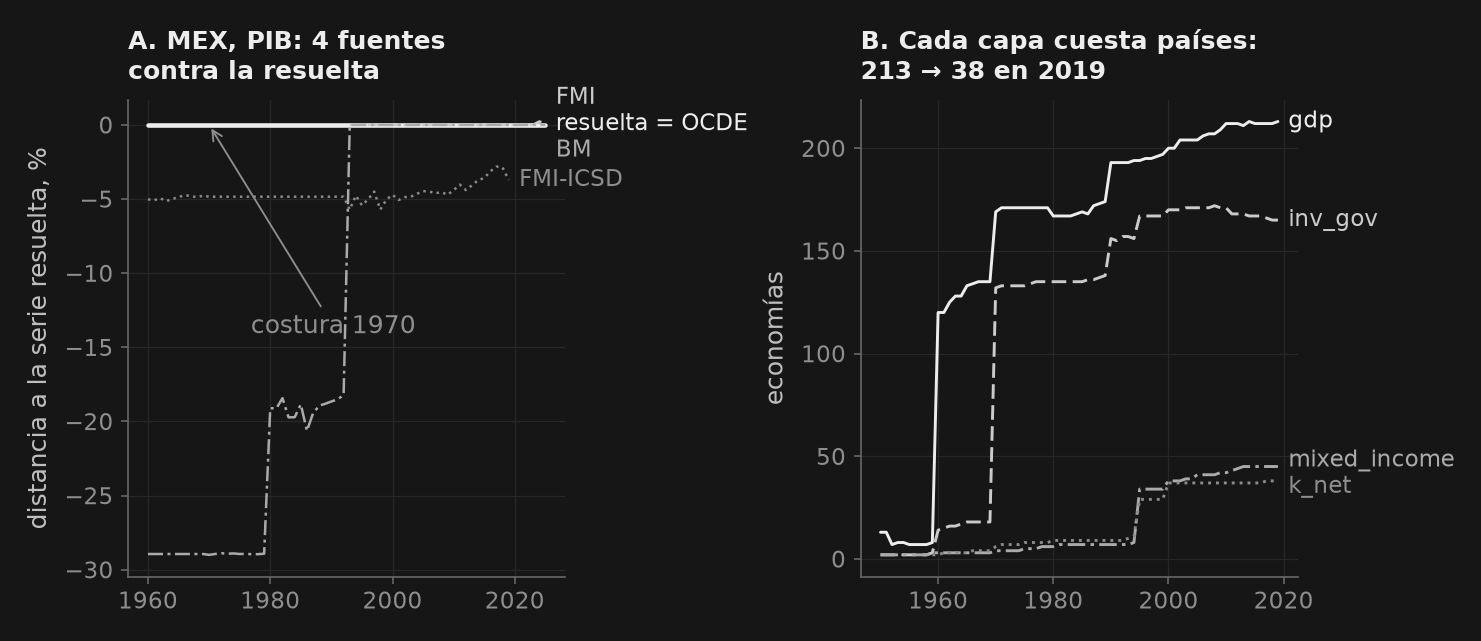

In [20]:
fig, axes = _nbstyle.figura(1, 2)
ticks = pd.to_datetime([f"{y}-01-01" for y in range(1960, 2021, 20)])
# A. Every source as its distance to the resolved series: a flat line grows like it, at another level.
# The primary is not drawn apart: where it publishes, it IS the resolved series.
ax = axes[0]
res = annual.query("code == @EXAMPLE and variable == 'gdp'").set_index("date").value
primary = prov_Y.query("code == @EXAMPLE and variable == 'gdp'").source.iloc[0]
gdp_raw = raw_Y.query("code == @EXAMPLE and variable == 'gdp' and source != @primary")
blocks = [b for b in RANK_Y if (gdp_raw.source == b).any()]
dashes = _nbstyle.styles(len(blocks) + 1)[1:]
ax.plot(res.index, 0 * res, color=_nbstyle.TINTA, lw=2.2, label=tr("resolved", "resuelta") + f" = {SHORT[primary]}")
for i, b in enumerate(blocks):
    s = gdp_raw[gdp_raw.source == b].set_index("date").value.sort_index()
    ax.plot(s.index, 100 * np.log(s / res.reindex(s.index)), color=cols[i + 1], ls=dashes[i], lw=1.2, label=SHORT[b])
seam = seams_Y.query("code == @EXAMPLE and variable == 'gdp' and method == 'ratio'")
if len(seam):
    d = seam.date.min()
    ax.annotate(tr("seam", "costura") + f" {d:%Y}", xy=(d, 0), xytext=(20, -100), textcoords="offset points",
                color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_title(tr(f"A. {EXAMPLE}, GDP: {len(blocks) + 1} sources\nagainst the resolved one",
                f"A. {EXAMPLE}, PIB: {len(blocks) + 1} fuentes\ncontra la resuelta"))
ax.set_ylabel(tr("distance to the resolved series, %", "distancia a la serie resuelta, %"))
ax.set_xticks(ticks, [f"{t:%Y}" for t in ticks])

# B. Economies per year with each layer, up to the last year every layer is at 80% of its own peak
# (after it, what falls is the publication lag, not the coverage).
ax = axes[1]
layers = ["gdp", "inv_gov", "mixed_income", "k_net"]
per_year = {v: annual.loc[annual.variable == v].groupby("date").code.nunique() for v in layers}
last = min(s[s >= 0.8 * s.max()].index.max() for s in per_year.values())
for i, v in enumerate(layers):
    s = per_year[v].loc[:last]
    ax.plot(s.index, s, color=cols[i], ls=_nbstyle.styles(4)[i], lw=1.4, label=v)
ax.set_title(tr(f"B. Each layer costs countries:\n{per_year['gdp'][last]} → {per_year['k_net'][last]} in {last:%Y}",
                f"B. Cada capa cuesta países:\n{per_year['gdp'][last]} → {per_year['k_net'][last]} en {last:%Y}"))
ax.set_ylabel(tr("economies", "economías"))
ax.set_xticks(ticks, [f"{t:%Y}" for t in ticks])
_nbstyle.etiquetar(axes[0], donde="fin", fuera=True)
_nbstyle.etiquetar(axes[1], donde="fin")
plt.show()
del raw_Y, gdp_raw          # the annual stack before precedence is not read again
release_memory()

**Qué mirar en cada panel.** En A cada fuente se dibuja como su distancia, en por ciento, a la serie resuelta, que es la línea gruesa en cero. Una línea plana es una fuente que crece igual que la resuelta aunque esté en otro nivel: eso es justo lo que una costura por cociente puede arreglar, porque conserva el crecimiento de cada una. Una línea que sube o baja es una fuente que crece distinto, y si lo hace en los años del solape la costura sale marcada como inestable. A la izquierda de la flecha, la línea de la fuente que extiende la historia es plana por construcción —la serie resuelta *es* esa fuente, reescalada por el cociente del solape— y su distancia a cero es ese cociente. Una línea que **salta** es otra cosa: una fuente que cambió de base dentro de su propia serie, de modo que lo que publica antes y después del salto no crece igual que la resuelta. En B, cada capa de detalle cuesta economías —el PIB está para casi todas, la inversión pública para menos, la renta mixta y el capital para menos aún— y la caída no es suave: llega por escalones, cuando entra o sale un club de oficinas.

### 2.7 Paso 9 — Lo que pide el cuaderno siguiente

El cuaderno siguiente construye dos economías por país: la que publican las cuentas, y una **imputada**, en la que el consumo duradero es inversión que se acumula en un acervo de bienes duraderos y la inversión pública se acumula en capital público que rinde servicios. Para eso necesita, y aquí se comprueba que estén: el consumo por durabilidad **con su deflactor** —sin él no hay acervo de duraderos—, la inversión del gobierno separada de la del resto y un precio para ella, los acervos donde se publican y el consumo de capital fijo, la remuneración de asalariados, la renta mixta y el excedente, y el empleo por cuenta propia.

Dos cosas que este cuaderno **no** hace, a propósito. No estima ningún acervo: un inventario perpetuo exige decidir depreciaciones y un capital inicial, y esa decisión es del cuaderno que lo usa. Y no ajusta la participación del trabajo él mismo: le deja los ingredientes, con su procedencia, y también las dos versiones ya ajustadas que otros publican —la de la OIT (`labour_share`) y la de PWT (`labsh`)— para compararse con ellas.

#### Lo que no está, y por qué

Donde no hay, no hay columna. La lista de las tres frecuencias, porque es parte de la entrega:
- **Deflactores de la inversión por sector institucional** (hogares, sociedades, gobierno), anuales y trimestrales. Las cuentas sectoriales se publican a precios corrientes; ninguna oficina de las que entran aquí publica su volumen. Para la inversión pública la celda ofrece dos sustitutos: el deflactor de la inversión total o el de construcción, y el precio implícito del FMI, su inversión pública a precios corrientes sobre la misma a PPA de 2017.
- **Vacantes anuales.** Ninguna fuente las publica con esa frecuencia; se agregan desde el trimestral con la regla de la ficha.
- **Insumo-producto entre países.** Son archivos de cien megabytes por año, no una API; tienen su propio cuaderno.
- **Cuentas trimestrales del Banco Mundial y mensuales del FMI-WEO.** No existen: el WDI es anual y el WEO, semestral.
- Las ausencias propias del mensual —tasas, rendimientos, crédito— están en §4.2.

In [21]:
INGREDIENTS = ["cons_dur", "cons_dur_defl", "inv_gov", "inv_defl", "inv_struct_defl", "inv_gov_ppp2017",
               "k_net", "k_gov_net", "k_gov_pim", "cfc", "comp_emp", "mixed_income", "surplus_mixed",
               "emp_selfemp", "emp_self_lfs", "labour_share"]
first = prov_Y.set_index(["variable", "code"])["first"]
for v in INGREDIENTS:
    pv = prov_Y[prov_Y.variable == v]
    by = " · ".join(f"{SHORT[b]} {n}" for b, n in pv.source.value_counts().items())
    print(tr(f"{v}: {len(pv)} economies ({by}), {int((first[v].dt.year < 1970).sum())} from before 1970.",
             f"{v}: {len(pv)} economías ({by}), {int((first[v].dt.year < 1970).sum())} desde antes de 1970."))
n_labsh = pwt.dropna(subset=["labsh"]).code.nunique()
print(tr(f"labsh (PWT 11.0, t01_pwt110.csv.gz): {n_labsh} economies.",
         f"labsh (PWT 11.0, t01_pwt110.csv.gz): {n_labsh} economías."))

# Identities run only where every part comes from one office: a cross-source sum tests the precedence, not the data.
one = prov_Y.set_index(["code", "variable"]).source
parts = ["cons_dur", "cons_semidur", "cons_nondur", "cons_serv"]
src = pd.concat([one.xs(v, level="variable") for v in parts], axis=1)
same = src.index[src.nunique(axis=1).eq(1) & src.notna().all(axis=1)]
dur = ann.loc[ann.index.get_level_values("code").isin(same), parts + ["cons_hh"]].dropna()
dur_gap = (dur[parts].sum(axis=1) / dur.cons_hh - 1).abs()
print(tr(f"Durable + semi-durable + non-durable + services against household consumption, within one office: "
         f"median |gap| {dur_gap.median():.1%} in {dur_gap.index.get_level_values('code').nunique()} countries "
         f"(the split covers households only, S14; cons_hh adds the non-profits and, depending on the office, residents' purchases abroad).",
         f"Duraderos + semiduraderos + no duraderos + servicios contra el consumo de los hogares, dentro de una oficina: "
         f"mediana de |brecha| {dur_gap.median():.1%} en {dur_gap.index.get_level_values('code').nunique()} países "
         f"(el desglose cubre sólo a los hogares, S14; cons_hh suma las ISFLSH y, según la oficina, las compras de los residentes fuera)."))

ig = prov_Y[prov_Y.variable == "inv_gov"]
n_acc = int(ig.source.isin(["y_oecd_ana", "y_eurostat_na"]).sum())
n_imf = int((ig.source == "y_imf_icsd").sum())
r = (ann.inv_gov / ann.inv).dropna()
print(tr(f"Public investment: {n_acc} economies with accounts data, {n_imf} only through the IMF, in the currency of "
         f"each country's GDP (§2.6); the median of inv_gov / inv is {r.median():.1%}.",
         f"Inversión pública: {n_acc} economías con dato de cuentas, {n_imf} sólo por el FMI, en la moneda del PIB de "
         f"cada país (§2.6); la mediana de inv_gov / inv es {r.median():.1%}."))

has = {v: set(prov_Y.code[prov_Y.variable == v]) for v in INGREDIENTS}
stock = has["k_net"] | has["k_gov_net"] | has["k_gov_pim"]
price_gov = has["inv_defl"] | has["inv_struct_defl"] | has["inv_gov_ppp2017"]
durables = has["cons_dur"] & has["cons_dur_defl"]
both_ = durables & has["inv_gov"] & price_gov & stock
g_mixed = both_ & has["mixed_income"]
g_self = both_ & (has["emp_selfemp"] | has["emp_self_lfs"])
print(tr(f"B's two economies, the published and the imputed, can be built in {len(both_)} countries: durables with "
         f"their deflator, public investment with a price, and a stock. The layer that binds is durables "
         f"({len(has['cons_dur'])} economies, {len(durables)} with the deflator). Gollin's adjustment, within those: "
         f"with mixed income in {len(g_mixed)}, with self-employment in {len(g_self)}.",
         f"Las dos economías de B, la publicada y la imputada, pueden construirse en {len(both_)} países: duraderos con "
         f"su deflactor, inversión pública con un precio y un acervo. La capa que ata es la de los duraderos "
         f"({len(has['cons_dur'])} economías, {len(durables)} con el deflactor). El ajuste de Gollin, dentro de ellos: "
         f"con renta mixta en {len(g_mixed)}, con cuenta propia en {len(g_self)}."))

n_dur, n_invgov = len(has["cons_dur"]), len(ig)
# The four parts add up to household consumption within one office, up to the S15 difference named above.
assert dur_gap.median() < 0.05
# Enough of each ingredient to make the next notebook worth running.
assert n_dur >= 30 and n_invgov >= 150 and len(g_mixed) >= 25
# The binding layer is durables, not the stocks or the price of public investment.
assert len(both_) >= len(durables) - 5

cons_dur: 51 economías (OCDE 43 · Eurostat 8), 2 desde antes de 1970.
cons_dur_defl: 49 economías (OCDE 41 · Eurostat 8), 2 desde antes de 1970.
inv_gov: 174 economías (FMI-ICSD 128 · OCDE 42 · Eurostat 4), 18 desde antes de 1970.
inv_defl: 177 economías (FMI 74 · OCDE 61 · BM 37 · Eurostat 5), 40 desde antes de 1970.
inv_struct_defl: 51 economías (OCDE 47 · Eurostat 4), 6 desde antes de 1970.
inv_gov_ppp2017: 173 economías (FMI-ICSD 173), 173 desde antes de 1970.
k_net: 38 economías (OCDE 35 · Eurostat 3), 4 desde antes de 1970.
k_gov_net: 33 economías (OCDE 33), 1 desde antes de 1970.
k_gov_pim: 172 economías (FMI-ICSD 172), 19 desde antes de 1970.
cfc: 45 economías (OCDE 39 · Eurostat 6), 2 desde antes de 1970.
comp_emp: 65 economías (OCDE 59 · Eurostat 6), 4 desde antes de 1970.
mixed_income: 45 economías (OCDE 39 · Eurostat 6), 3 desde antes de 1970.
surplus_mixed: 65 economías (OCDE 59 · Eurostat 6), 4 desde antes de 1970.
emp_selfemp: 51 economías (OCDE 47 · Eurostat 4), 3 desde

## 3. Trimestral: toda la historia que publica cada oficina

El panel trimestral es el que leen los ciclos, y por eso pide otra cosa que el anual: no amplitud, sino **largo y detalle a la vez** —cada componente del gasto con su deflactor, horas y ocupados de las mismas cuentas, paro de las encuestas— para pocas decenas de economías, desde donde cada una empiece.

| Paso | Pregunta | Fuente |
|---|---|---|
| §3.1 | ¿Gasto, producción, renta y trabajo, desde cuándo? | OCDE, `qna_panel` |
| §3.2 | ¿Quién invierte, y cuántos son? | OCDE, cuentas sectoriales y población |
| §3.3 | ¿Paro, actividad y vacantes? | encuestas: OCDE, Eurostat, OIT |
| §3.4 | ¿Cuánto discrepan dos oficinas? ¿Y el crédito? | Eurostat, FMI, BIS |
| §3.5 | ¿Quién gana, y cuántas economías lo tienen todo? | precedencia y escalera |

### 3.1 Paso 10 — Una llamada, todos los productos, desde 1947

`qna_panel` baja las cuentas trimestrales de la OCDE —gasto, producción, renta, trabajo, durabilidad y activos— y las devuelve en un panel `(code, date)`. Cuatro argumentos deciden lo que llega:

- `start="1947"`. Pedir desde 1995 era una decisión de cuota, no de datos: la fecha de inicio la pone cada oficina, no nosotros. Estados Unidos empieza en 1947 y el flujo lo entrega entero; la celda imprime cuántas economías ganan historia anterior a 1995.
- `real=False`. Volúmenes no: con el nominal y el deflactor el volumen se rehace exacto (§1).
- `sa="x13"`. Toma el ajuste oficial donde lo hay y aplica X-13 donde no — en la descarga, con su procedencia anotada país por país; nunca aquí.
- `labor=True`. Ocupados y horas de las mismas cuentas, con su base temporal **ya reparada**. Alguna oficina publica las horas en otra base temporal; `qna_panel` las corrige y guarda el factor, que viaja en el panel como `hours_factor` para que la corrección se vea. Es una afirmación con consecuencia aritmética: divide las horas entre el empleo y entre las trece semanas de un trimestre y tiene que salir una jornada plausible. La celda lo comprueba; el factor está identificado, no elegido.

**Fíjate en el recibo.** Cada país publica en su propio año de referencia de precios, y algunos —los de base `Q`— no encadenan: sus deflactores son de base fija. Nada en los nombres de columna lo dice; los números simplemente llegan.

In [22]:
from puremacro.fetch import qna_countries, qna_panel, qna_meta

qna = load_block("q_oecd_qna", lambda: qna_panel(qna_countries(), start="1947", assets=True, durability=True,
                                                  output=True, income=True, labor=True, labor_activities=True,
                                                  sa="x13", real=False),
                 tr("OECD quarterly national accounts", "cuentas nacionales trimestrales de la OCDE"))
qmeta = qna_meta(qna).set_index("code")      # per-country records: the attrs travel with the block, offline too


def quarter(d):
    """2020T2 in Spanish, 2020Q2 in English."""
    return f"{d.year}{tr('Q', 'T')}{d.quarter}"


# hours_factor is per-country metadata (qna_meta's hours_scale), broadcast as rows to every quarter
# with hours: B reads it from the quarterly panel, so the repair can be seen where the hours are used.
scale = pd.to_numeric(qmeta.hours_scale, errors="coerce")
hours_factor = (qna.loc[qna.variable == "hours", ["code", "date"]].astype({"code": str})
                .assign(variable="hours_factor", value=lambda d: d.code.map(scale), source="q_oecd_qna")
                .dropna(subset=["value"]))

q = wide_panel(qna[qna.variable.isin(["gdp", "inv", "hours", "emp"])])     # the four this section reads
start = q.gdp.dropna().reset_index().groupby("code").date.min()
n_pre95 = int((start < "1995-01-01").sum())
print(tr(f"Panel: {len(start)} economies, {quarter(start.min())}–{quarter(qna.date.max())}; "
         f"{n_pre95} gain history before 1995, USA since {quarter(start['USA'])}.",
         f"Panel: {len(start)} economías, {quarter(start.min())}–{quarter(qna.date.max())}; "
         f"{n_pre95} ganan historia anterior a 1995, EUA desde {quarter(start['USA'])}."))

refs = qmeta.price_ref_year.dropna().astype(int)
q_codes = sorted(qmeta.index[qmeta.price_base == "Q"])
print(tr(f"Price reference years: {refs.nunique()} different ones, from {refs.min()} to {refs.max()}. "
         f"Fixed base (Q): {', '.join(q_codes)} — a downloader that keeps only chained series (L) returns an "
         f"empty frame for them, and without a warning.",
         f"Años de referencia de precios: {refs.nunique()} distintos, de {refs.min()} a {refs.max()}. "
         f"De base fija (Q): {', '.join(q_codes)} — un descargador que filtre sólo encadenados (L) les devuelve "
         f"un marco vacío, y sin avisar."))

# The implied working week: hours (millions per quarter) / employment (thousands) / 13 weeks.
week = (q.hours * 1e6 / (q.emp * 1e3) / 13).dropna()
repaired = scale[scale.notna() & scale.ne(1)]
for c, f in repaired.items():
    wk = week.xs(c, level="code").median()
    print(tr(f"hours_factor different from 1: {c} ×{f:g}. Without the repair its working week would be "
             f"{wk / f:.1f} hours; with it, {wk:.1f}.",
             f"hours_factor distinto de 1: {c} ×{f:g}. Sin la reparación su jornada sería de {wk / f:.1f} horas "
             f"semanales; con ella, {wk:.1f}."))
med = week.median()
out = week[~week.between(25, 50)]
print(tr(f"Implied working week, hours / (employment × 13): median {med:.1f} hours in "
         f"{week.index.get_level_values('code').nunique()} economies; outside 25–50 hours, {len(out)} country-quarters: ",
         f"Jornada implícita, horas / (ocupados × 13): mediana de {med:.1f} horas en "
         f"{week.index.get_level_values('code').nunique()} economías; fuera de 25–50 horas, {len(out)} país-trimestres: ")
      + ", ".join(f"{c} {quarter(d)} ({v:.1f})" for (c, d), v in out.items()) + ".")

# Price bases are the two the OECD publishes, and nothing else.
assert set(qmeta.price_base) <= {"L", "Q"}
# The hours repair is the one the arithmetic identifies, and it is applied: absurd without it, plausible with it.
assert len(repaired) > 0
for c, f in repaired.items():
    assert week.xs(c, level="code").median() / f < 25 < week.xs(c, level="code").median() < 50
assert 25 < med < 50
# Outside the band only the 2020 lockdown, when hours fell and headcounts did not (furlough schemes).
assert set(out.index.get_level_values("date").year) <= {2020}
# Asking from 1947 is what buys the history.
assert start["USA"] <= pd.Timestamp("1950-01-01")

q_oecd_qna             444,584 filas ·  49 economías ·  86 variables · 1947–2026 · congelado
Panel: 49 economías, 1947T1–2026T2; 19 ganan historia anterior a 1995, EUA desde 1947T1.
Años de referencia de precios: 14 distintos, de 1995 a 2025. De base fija (Q): ARG, CHN, IDN, IND, MEX, ZAF — un descargador que filtre sólo encadenados (L) les devuelve un marco vacío, y sin avisar.
hours_factor distinto de 1: CHL ×13. Sin la reparación su jornada sería de 3.2 horas semanales; con ella, 41.3.
Jornada implícita, horas / (ocupados × 13): mediana de 32.9 horas en 33 economías; fuera de 25–50 horas, 5 país-trimestres: DEU 2020T2 (24.5), DEU 2020T3 (25.0), DNK 2020T2 (25.0), FRA 2020T2 (23.4), LUX 2020T2 (23.8).


### 3.2 Paso 11 — Quién invierte, y cuántos son

Dos cosas que el panel trimestral necesita y `qna_panel` no trae. La primera es la inversión por sector institucional, y la OCDE la publica por dos caminos que no se solapan del todo: un flujo de gasto por sector para un puñado de economías, y las cuentas sectoriales trimestrales para muchas más. `qna_sector_gfcf` une los dos, país por país, y deja anotado en la ficha qué camino tomó cada uno.

**Ojo con el doble conteo.** En las cuentas sectoriales la misma partida aparece como recurso y como empleo, y una consulta que no fija esa dimensión devuelve la inversión dos veces. puremacro fija el lado del empleo (`ACCOUNTING_ENTRY = D`); la celda comprueba la consecuencia: el gobierno más el resto tienen que sumar la economía entera, no el doble.

La segunda es la población, en miles de personas, que convierte cualquier agregado en per cápita sin salir de la misma fuente.

In [23]:
from puremacro.fetch import qna_sector_gfcf, qna_population

gfcf_q = load_block("q_oecd_gfcf_sector", lambda: qna_sector_gfcf(start="1947", sa="x13"),
                    tr("OECD quarterly GFCF by sector", "FBCF trimestral por sector, OCDE"))
pop_q = load_block("q_oecd_pop", lambda: qna_population(start="1947"),
                   tr("OECD quarterly population", "población trimestral, OCDE"))

# Which road each economy took, read from the block's own metadata.
road = pd.DataFrame(gfcf_q.attrs["meta"]).query("variable == 'inv_gov'")
by_sector = road.source.str.contains("GFCF_SECTOR")
g = wide_panel(gfcf_q)
gov0 = g.inv_gov.dropna().reset_index().groupby("code").date.min()
print(tr(f"Quarterly public investment: {len(gov0)} economies — {by_sector.sum()} through the expenditure-by-sector "
         f"flow, {(~by_sector).sum()} through the sector accounts; USA since {quarter(gov0['USA'])}.",
         f"Inversión pública trimestral: {len(gov0)} economías — {by_sector.sum()} por el flujo de gasto por sector, "
         f"{(~by_sector).sum()} por las cuentas sectoriales; EUA desde {quarter(gov0['USA'])}."))

# The sum of the two sectors against the whole economy of qna_panel (same office, another table).
both = g.join(q[["inv"]], how="inner").dropna()
gap = ((both.inv_gov + both.inv_priv) / both.inv - 1).abs()
(wc, wd), sector_gap = gap.idxmax(), gap.median()
print(tr(f"inv_gov + inv_priv against inv (same office): median |gap| {sector_gap:.2%} in {len(gap):,} "
         f"country-quarters; worst {wc} {quarter(wd)} ({gap.max():.1%}). A double count would put it near 100%.",
         f"inv_gov + inv_priv frente a inv (misma oficina): mediana de |brecha| {sector_gap:.2%} en {len(gap):,} "
         f"país-trimestres; la peor, {wc} {quarter(wd)} ({gap.max():.1%}). Un doble conteo la pondría cerca del 100%."))

pop0 = pop_q.loc[pop_q.variable == "population"].groupby("code", observed=True).date.min()
print(tr(f"Quarterly population: {len(pop0)} economies, USA since {quarter(pop0['USA'])}.",
         f"Población trimestral: {len(pop0)} economías, EUA desde {quarter(pop0['USA'])}."))

# Deduplicated: the two sectors add up to the whole economy, not to twice it.
assert sector_gap < 0.01
# The repeated entry did not survive.
assert not gfcf_q.duplicated(["code", "date", "variable"]).any()

q_oecd_gfcf_sector       8,594 filas ·  34 economías ·   2 variables · 1947–2026 · congelado
q_oecd_pop              20,672 filas ·  43 economías ·   8 variables · 1947–2026 · congelado
Inversión pública trimestral: 34 economías — 11 por el flujo de gasto por sector, 23 por las cuentas sectoriales; EUA desde 1947T1.
inv_gov + inv_priv frente a inv (misma oficina): mediana de |brecha| 0.07% en 4,178 país-trimestres; la peor, BGR 1999T1 (52.1%). Un doble conteo la pondría cerca del 100%.
Población trimestral: 42 economías, EUA desde 1947T1.


### 3.3 Paso 12 — Encuestas junto a cuentas: paro, actividad, vacantes

El paro no está en las cuentas nacionales; está en las encuestas de fuerza de trabajo, y la OCDE las compila trimestralmente desde 1955 para quien las tiene. Las vacantes llegan por dos caminos que no miden lo mismo: Eurostat publica la **tasa** de vacantes —los puestos sin cubrir sobre el total de puestos— para la Unión y su periferia, y la OCDE el **número** de vacantes registradas en las oficinas públicas de empleo, un conteo administrativo cuyo nivel depende de cuánto del mercado pasa por esas oficinas: se compara dentro de un país, no entre países. La OIT trae el paro y la informalidad trimestrales de las economías que los miden fuera de esos clubes. Con la tasa de vacantes y la de paro, §3.5 calcula la estrechez del mercado, $\theta = v/u$.

**Un dato que se promete se comprueba donde se usa.** Que la encuesta de Estados Unidos empiece en 1955 es una afirmación sobre el panel, no sobre el descargador; la celda la comprueba con el número, no con la llamada.

Una regla de nombres que se repite en adelante: **el nombre de una serie dice su ajuste**. El paro trimestral de la OIT llega sin desestacionalizar y se guarda como `urate_nsa`, y el número de desocupados como `unemp_nsa`. Si compartiera nombre con el `urate` desestacionalizado de la OCDE, la precedencia mezclaría los dos y nada lo notaría. Y otra que ya apareció en §2.3: las cuentas cuentan **puestos** en el territorio y la encuesta **residentes** con empleo; donde más difieren es donde más gente trabaja en un país y vive en otro.

In [24]:
from puremacro.fetch import oecd_lfs_panel, oecd_vacancies, fetch_eurostat_vacancies, ilostat_panel

lfs_q = load_block("q_oecd_lfs", lambda: oecd_lfs_panel(freq="Q", start="1950"),
                   tr("OECD labour force surveys, quarterly", "encuestas de fuerza de trabajo, OCDE, trimestral"))
vac_q = load_block("q_oecd_vac", lambda: oecd_vacancies(freq="Q", start="1950"),
                   tr("OECD registered vacancies", "vacantes registradas, OCDE"))
esvac_q = load_block("q_eurostat_vac", lambda: fetch_eurostat_vacancies(indicator="JVR", nace="B-T", s_adj="SA"),
                     tr("Eurostat job vacancy rate", "tasa de vacantes de Eurostat"))
ilo_q = load_block("q_ilo", lambda: ilostat_panel(freq="Q"),
                   tr("ILOSTAT quarterly labour panel", "panel laboral trimestral de ILOSTAT"))

u0 = lfs_q.loc[lfs_q.variable == "urate"].groupby("code", observed=True).date.min()
print(tr(f"Seasonally adjusted unemployment (OECD): {len(u0)} economies; {int((u0 < '1970-01-01').sum())} since "
         f"before 1970, USA since {quarter(u0['USA'])}.",
         f"Paro desestacionalizado (OCDE): {len(u0)} economías; {int((u0 < '1970-01-01').sum())} desde antes "
         f"de 1970, EUA desde {quarter(u0['USA'])}."))
vac0 = vac_q.loc[vac_q.variable == "vacancies"].groupby("code", observed=True).date.min().sort_values()
print(tr(f"Vacancy rate (Eurostat): {esvac_q.code.nunique()} economies, {quarter(esvac_q.date.min())}–"
         f"{quarter(esvac_q.date.max())}. Registered vacancies (OECD, a count): {len(vac0)} economies, "
         f"{vac0.index[0]} since {quarter(vac0.iloc[0])}.",
         f"Tasa de vacantes (Eurostat): {esvac_q.code.nunique()} economías, {quarter(esvac_q.date.min())}–"
         f"{quarter(esvac_q.date.max())}. Vacantes registradas (OCDE, un conteo): {len(vac0)} economías, "
         f"{vac0.index[0]} desde {quarter(vac0.iloc[0])}."))
ilo_u = set(ilo_q.code[ilo_q.variable == "urate_nsa"])
beyond = ilo_u - set(lfs_q.code.unique()) - set(esvac_q.code.unique())
n_inf = ilo_q.loc[ilo_q.variable == "informal_rate"].code.nunique()
print(tr(f"Unadjusted unemployment (ILO): {len(ilo_u)} economies, {len(beyond)} of them beyond the OECD and "
         f"Eurostat surveys. Quarterly informality: {n_inf}.",
         f"Paro sin desestacionalizar (OIT): {len(ilo_u)} economías, {len(beyond)} de ellas más allá de las "
         f"encuestas de la OCDE y Eurostat. Informalidad trimestral: {n_inf}."))

# Heads in the accounts (jobs in the territory) against employed in the survey (residents in work).
heads = pd.concat([q.emp, wide_panel(lfs_q[lfs_q.variable == "emp_lfs"]).emp_lfs], axis=1).dropna()
diff = heads.emp / heads.emp_lfs - 1
by_code = diff.groupby(level="code").median()
far = by_code.abs().idxmax()
print(tr(f"Heads in the accounts against employed in the survey: median |difference| {diff.abs().median():.1%} in "
         f"{len(by_code)} economies; the largest, {far} ({by_code[far]:+.0%}) — two concepts, two names.",
         f"Cabezas de las cuentas frente a ocupados de la encuesta: mediana de |diferencia| {diff.abs().median():.1%} en "
         f"{len(by_code)} economías; la mayor, {far} ({by_code[far]:+.0%}) — dos conceptos, dos nombres."))

# US survey unemployment since 1955, as promised.
assert u0["USA"] <= pd.Timestamp("1955-01-01")
# Names carry the adjustment: no NSA series under an SA name, and the ILO's counts say they are unadjusted.
assert not set(ilo_q.variable.unique()) & {"urate", "emp_lfs", "lf", "wap", "unemp"}
# Rates are rates.
assert lfs_q.query("variable == 'urate'").value.between(0, 100).all()
assert esvac_q.value.between(0, 100).all()

q_oecd_lfs              42,390 filas ·  45 economías ·   9 variables · 1955–2026 · congelado
q_oecd_vac               9,510 filas ·  32 economías ·   4 variables · 1955–2026 · congelado
q_eurostat_vac           1,818 filas ·  29 economías ·   1 variables · 2003–2026 · congelado


   apartadas (históricas o territorios): JEY


q_ilo                   89,297 filas · 130 economías ·  11 variables · 1948–2026 · congelado
Paro desestacionalizado (OCDE): 44 economías; 4 desde antes de 1970, EUA desde 1955T1.
Tasa de vacantes (Eurostat): 29 economías, 2003T2–2026T2. Vacantes registradas (OCDE, un conteo): 18 economías, AUT desde 1955T1.
Paro sin desestacionalizar (OIT): 122 economías, 75 de ellas más allá de las encuestas de la OCDE y Eurostat. Informalidad trimestral: 54.
Cabezas de las cuentas frente a ocupados de la encuesta: mediana de |diferencia| 2.5% en 37 economías; la mayor, LUX (+61%) — dos conceptos, dos nombres.


### 3.4 Paso 13 — Segundas opiniones, y el crédito

Eurostat no está aquí para rellenar huecos de la OCDE: está para decirnos cuánto discrepan dos oficinas que leen las mismas cuentas, y para traer a las economías europeas que la OCDE no cubre. El FMI hace lo mismo fuera de los dos clubes. La celda mide la discrepancia donde ambas publican: una mediana pequeña es lo esperable, y la peor dice dónde mirar.

El crédito al sector privado lo publica el BIS **trimestralmente**, como porcentaje del PIB, y así se guarda, junto con los precios de la vivienda. No se interpola un trimestre para fabricar meses (§4.2).

In [25]:
from puremacro.fetch import eurostat_na_panel, imf_nea_panel

eurostat_q = load_block("q_eurostat_na", lambda: eurostat_na_panel(freq="Q", durability=True, assets=True, output=True,
                                                                    income=True, labor=True, real=True),
                        tr("Eurostat quarterly national accounts", "cuentas nacionales trimestrales de Eurostat"))
imf_q = load_block("q_imf_nea", lambda: imf_nea_panel(freq="Q", sa="SA", real=True),
                   tr("IMF quarterly national accounts (SA)", "cuentas nacionales trimestrales del FMI (desestacionalizadas)"))


def gdp_of(block):
    """Nominal GDP of one block, as a (code, date) series."""
    return block.loc[block.variable == "gdp"].set_index(["code", "date"]).value


oecd_gdp, es_gdp, imf_gdp = gdp_of(qna), gdp_of(eurostat_q), gdp_of(imf_q)
for other, label in [(es_gdp, "Eurostat"), (imf_gdp, tr("the IMF", "el FMI"))]:
    pair = pd.concat([oecd_gdp, other], axis=1, keys=["oecd", "other"]).dropna()
    dlog = np.log(pair.oecd / pair.other).abs()
    worst = dlog.groupby(level="code").median().idxmax()
    print(tr(f"Where the OECD and {label} publish the nominal GDP of the same economy and quarter "
             f"({len(pair):,} country-quarters): median |Δ log| {dlog.median():.4f}; the worst economy, {worst} "
             f"({dlog.xs(worst, level='code').median():.3f}).",
             f"Donde la OCDE y {label} publican el PIB nominal de la misma economía y trimestre "
             f"({len(pair):,} país-trimestres): mediana de |Δ log| {dlog.median():.4f}; la peor economía, {worst} "
             f"({dlog.xs(worst, level='code').median():.3f})."))
    if other is es_gdp:
        d_es = dlog.median()
codes = {k: set(s.index.get_level_values("code")) for k, s in [("oecd", oecd_gdp), ("es", es_gdp), ("imf", imf_gdp)]}
only_es = sorted(codes["es"] - codes["oecd"])
only_imf = sorted(codes["imf"] - codes["oecd"] - codes["es"])
nsa_es = sorted(set(eurostat_q.code[eurostat_q.variable == "gdp_nsa"]))
print(tr(f"Only through Eurostat: {', '.join(only_es)}; and, unadjusted under gdp_nsa, {', '.join(nsa_es)}. "
         f"Only through the IMF: {len(only_imf)} economies, among them {', '.join(only_imf[:6])}.",
         f"Sólo por Eurostat: {', '.join(only_es)}; y, sin desestacionalizar bajo gdp_nsa, {', '.join(nsa_es)}. "
         f"Sólo por el FMI: {len(only_imf)} economías, entre ellas {', '.join(only_imf[:6])}."))

# Two offices reading the same accounts agree to rounding, almost everywhere.
assert d_es < 0.01
# Each second opinion also brings economies of its own.
assert only_es and only_imf

q_eurostat_na          306,811 filas ·  39 economías · 119 variables · 1978–2026 · congelado
q_imf_nea              127,273 filas ·  66 economías ·  18 variables · 1950–2026 · congelado


Donde la OCDE y Eurostat publican el PIB nominal de la misma economía y trimestre (3,928 país-trimestres): mediana de |Δ log| 0.0000; la peor economía, GBR (0.006).
Donde la OCDE y el FMI publican el PIB nominal de la misma economía y trimestre (6,685 país-trimestres): mediana de |Δ log| 0.0000; la peor economía, GBR (0.004).
Sólo por Eurostat: ALB, BIH, CYP, MKD, MLT, MNE, SRB; y, sin desestacionalizar bajo gdp_nsa, MDA, XKX. Sólo por el FMI: 13 economías, entre ellas ARM, CMR, ECU, HND, JOR, KAZ.


In [26]:
from puremacro.fetch import bis_panel

bis_q = load_block("q_bis", lambda: bis_panel(freq="Q"),
                   tr("BIS credit, property prices and exchange rates", "crédito, vivienda y tipos de cambio del BIS"))

c0 = bis_q.loc[bis_q.variable == "credit_gdp"].groupby("code", observed=True).date.min()
n_hp = bis_q.loc[bis_q.variable == "house_price"].code.nunique()
n_dsr = bis_q.loc[bis_q.variable == "dsr"].code.nunique()
print(tr(f"Private credit / GDP: {len(c0)} economies, {int((c0 < '1970-01-01').sum())} since before 1970 "
         f"(USA since {quarter(c0['USA'])}). House prices: {n_hp}. Debt service ratio: {n_dsr}.",
         f"Crédito privado / PIB: {len(c0)} economías, {int((c0 < '1970-01-01').sum())} desde antes de 1970 "
         f"(EUA desde {quarter(c0['USA'])}). Precios de la vivienda: {n_hp}. Servicio de la deuda: {n_dsr}."))
print(tr(f"The exchange rate against the dollar reaches {bis_q.loc[bis_q.variable == 'fx_usd'].code.nunique()} "
         f"economies: the BIS is the broadest quarterly source of the panel, not only the one for credit.",
         f"El tipo de cambio contra el dólar llega a {bis_q.loc[bis_q.variable == 'fx_usd'].code.nunique()} "
         f"economías: el BIS es la fuente trimestral más ancha del panel, no sólo la del crédito."))

# The euro area is an aggregate: it never reaches the panel as an economy.
assert not set(bis_q.code.unique()) & AGGREGATES
# Credit reaches at least forty economies.
assert len(c0) >= 40

   apartadas (históricas o territorios): AIA, ANT, MSR
q_bis                  236,767 filas · 186 economías ·  21 variables · 1791–2026 · congelado


Crédito privado / PIB: 43 economías, 20 desde antes de 1970 (EUA desde 1947T4). Precios de la vivienda: 57. Servicio de la deuda: 32.
El tipo de cambio contra el dólar llega a 186 economías: el BIS es la fuente trimestral más ancha del panel, no sólo la del crédito.


### 3.5 Paso 14 — La misma regla en otra frecuencia, y la escalera de cobertura

La precedencia es la misma y se aplica igual, porque un criterio que cambia de frecuencia no es un criterio. La OCDE gana a Eurostat, y Eurostat al FMI; las encuestas de la OCDE ganan a las de la OIT, que además llegan con otro nombre. Los umbrales cambian de unidad, no de idea: en el anual, ocho años para ser primaria y tres de solape para medir una costura; aquí, cinco años de trimestres y uno de solape.

Tres series no se descargan: se calculan aquí, después de la precedencia, y la ficha las marca como `derived`. La jornada semanal (`hours_week`) y la parte del empleo por cuenta propia (`self_emp_share`) sólo donde numerador y denominador vienen de la misma fuente —un cociente entre dos oficinas mide su discrepancia, no la economía—; la estrechez $\theta$ junta por definición dos encuestas, la tasa de vacantes de Eurostat y la de paro de la OCDE. Ninguna se extiende hacia atrás, y cada una tiene su fila de procedencia.

Después, la pregunta que decide cualquier estudio trimestral: ¿cuántas economías tienen **todo** lo que el estudio pide? Cada capa de detalle cuesta países, y el escalón que más cuesta no siempre es el que uno espera. El panel es la unión; la escalera es lo que cada pregunta puede pagar.

In [27]:
MIN_OBS_Q = 20       # five years of quarters before a source can be primary
MIN_OVERLAP_Q = 4    # one year of common quarters to measure a seam
RANK_Q = {"q_oecd_qna": 1, "q_oecd_gfcf_sector": 1, "q_oecd_pop": 1, "q_oecd_lfs": 1, "q_oecd_vac": 1, "q_bis": 1,
          "q_eurostat_na": 2, "q_eurostat_vac": 2,
          "q_imf_nea": 3, "q_ilo": 3}
raw_Q = stack([qna, hours_factor, gfcf_q, pop_q, lfs_q, vac_q, esvac_q, ilo_q, eurostat_q, imf_q, bis_q])
# The blocks live on in raw_Q: one copy is enough.
del gfcf_q, pop_q, lfs_q, vac_q, esvac_q, ilo_q, eurostat_q, imf_q, bis_q, hours_factor
release_memory()

audit_Q = audit_units(raw_Q, "Q")
count = audit_Q.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"Quarterly audit: {count['same']:,} of {len(audit_Q):,} comparisons agree; {count['pow10']} powers of ten; "
         f"{count['currency']} other currencies or bases; {count['concept']} {'different concept' if count['concept'] == 1 else 'different concepts'} — ",
         f"Auditoría trimestral: {count['same']:,} de {len(audit_Q):,} comparaciones coinciden; {count['pow10']} "
         f"potencias de diez; {count['currency']} monedas o bases distintas; {count['concept']} "
         f"{'concepto distinto' if count['concept'] == 1 else 'conceptos distintos'} — ")
      + ", ".join(f"{r.code} {r.variable} ({r.pair}, {10 ** r.log10_ratio:.3g})"
                  for r in audit_Q.query("verdict == 'concept'").itertuples()) + ".")
# Where they come from: how far each side of the clashing pairs reaches.
clash = audit_Q.query("verdict == 'concept'")
for c in sorted(set(clash.code)):
    pair_blocks = {b for p in clash.pair[clash.code == c] for b in p.split(" / ")}
    ends = raw_Q.loc[(raw_Q.code == c) & raw_Q.source.isin(pair_blocks)].groupby("source", observed=True).date.max()
    print(f"   {c}: " + ", ".join(f"{b} " + tr("until ", "hasta ") + quarter(d) for b, d in ends.items())
          + tr(" — a vintage that stopped against one that kept being revised.",
               " — una edición que se detuvo frente a otra que se siguió revisando."))

# The precedence of §2.6, with the quarterly thresholds.
quarterly, prov_Q, seams_Q = splice(raw_Q, "Q", RANK_Q, min_obs=MIN_OBS_Q, min_overlap=MIN_OVERLAP_Q)
seam_receipts(prov_Q, seams_Q)
n_ext = int((prov_Q.n_extended > 0).sum())
print(tr(f"In quarters the OECD is already the longest source wherever it publishes: {n_ext} of {len(prov_Q):,} "
         f"country-variables are extended backwards; the other offices add economies and series, not history.",
         f"En trimestres la OCDE ya es la fuente más larga allí donde publica: {n_ext} de {len(prov_Q):,} "
         f"país-variables se extienden hacia atrás; las otras oficinas añaden economías y series, no historia."))
del raw_Q, qna          # the quarterly stack before precedence is not read again
release_memory()

# After puremacro's rescaling, overlaps agree (first frozen run: 99.6%) ...
assert (audit_Q.verdict == "same").mean() > 0.95
# ... and the concept clashes are few enough to list one by one (first frozen run: 0.4%).
assert (audit_Q.verdict == "concept").mean() < 0.02
# The OECD already carries the longest history almost everywhere: few seams, and those few are stable.
ratio_Q = seams_Q.query("method == 'ratio'")
assert len(ratio_Q) < 0.01 * len(prov_Q) and (ratio_Q.empty or ratio_Q.stable.mean() > 0.75)

Auditoría trimestral: 1,667 de 1,674 comparaciones coinciden; 0 potencias de diez; 6 monedas o bases distintas; 1 concepto distinto — GBR va_fin (q_eurostat_na / q_oecd_qna, 0.824).
   GBR: q_eurostat_na hasta 2020T3, q_oecd_qna hasta 2026T2 — una edición que se detuvo frente a otra que se siguió revisando.


Primaria por bloque (país-variables): q_oecd_qna 3,436 · q_ilo 1,200 · q_bis 1,168 · q_eurostat_na 584 · q_oecd_lfs 343 · q_imf_nea 283 · q_oecd_pop 163 · q_oecd_gfcf_sector 67 · q_oecd_vac 51 · q_eurostat_vac 29
1 costura aceptada, 100% de las de cociente estables; extiende la historia una mediana de 4 períodos. 0 extensiones rechazadas.
0 costuras absorben una potencia exacta de diez; el factor queda en t01_seams.csv.
En trimestres la OCDE ya es la fuente más larga allí donde publica: 1 de 7,324 país-variables se extienden hacia atrás; las otras oficinas añaden economías y series, no historia.


In [28]:
def ratio_rows(num, den, name, scale=1.0, same=True):
    """num / den on the spliced panel, as long rows of a derived series (rounded: stable hashes in §7)."""
    p = (quarterly.loc[quarterly.variable.isin([num, den])].astype({"code": str, "variable": str, "source": str})
         .pivot(index=["code", "date"], columns="variable", values=["value", "source"]).dropna())
    keep = (p["source", num] == p["source", den]) if same else np.ones(len(p), bool)
    v = (scale * p["value", num].astype(float) / p["value", den].astype(float))[keep]
    return v.round(9).rename("value").reset_index().assign(variable=name, source="derived")


# hours (millions per quarter) / employment (thousands) / 13 weeks; self-employed / employed; v / u.
derived = pd.concat([ratio_rows("hours", "emp", "hours_week", scale=1e3 / 13),
                     ratio_rows("emp_selfemp", "emp", "self_emp_share"),
                     ratio_rows("vrate", "urate", "theta", same=False)], ignore_index=True)
derived = derived[np.isfinite(derived.value)]
span = derived.groupby(["code", "variable"]).date.agg(first="min", last="max", n="size").reset_index()
prov_D = span.assign(freq="Q", source="derived", alternatives="", extended_from="", n_extended=0)
quarterly = stack([quarterly, derived])
prov_Q = pd.concat([prov_Q, prov_D.reindex(columns=prov_Q.columns)], ignore_index=True)
print(tr("Derived after the splice: ", "Derivadas después de la precedencia: ")
      + " · ".join(f"{v} {span.code[span.variable == v].nunique()} " + tr("economies", "economías")
                   for v in ["hours_week", "self_emp_share", "theta"]))

prim = prov_Q.query("variable == 'gdp'").source.value_counts()
print(tr(f"Quarterly GDP: {prim.sum()} economies ({prim.get('q_oecd_qna', 0)} OECD, "
         f"{prim.get('q_eurostat_na', 0)} Eurostat, {prim.get('q_imf_nea', 0)} IMF).",
         f"PIB trimestral: {prim.sum()} economías ({prim.get('q_oecd_qna', 0)} OCDE, "
         f"{prim.get('q_eurostat_na', 0)} Eurostat, {prim.get('q_imf_nea', 0)} FMI)."))

# The contract: unique keys, finite values, period-start dates.
quarterly = validate_long(quarterly, "Q")
# One provenance row per country-variable in the panel, and no other.
assert len(prov_Q) == quarterly.groupby(["code", "variable"], observed=True).ngroups
# Every name B and C read survived the stacking.
assert set(CONTRACT["Q"]) <= set(quarterly.variable.unique())
# At least the 49 economies with quarterly GDP of the October 2026 panel; more is the point of §3.4.
assert prim.sum() >= 49

Derivadas después de la precedencia: hours_week 37 economías · self_emp_share 42 economías · theta 27 economías
PIB trimestral: 69 economías (49 OCDE, 7 Eurostat, 13 FMI).


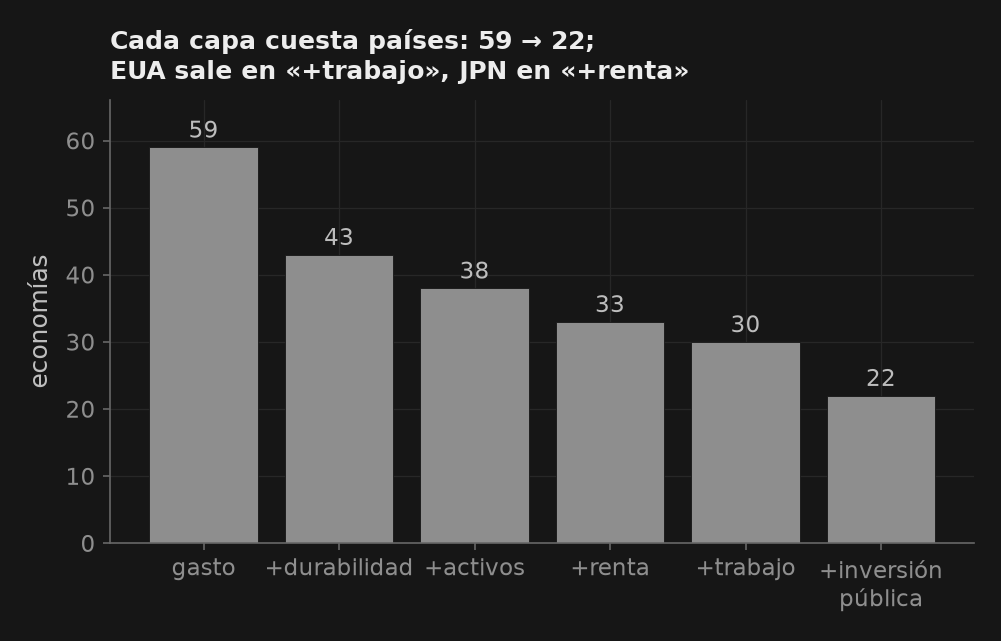

gasto 59 → +durabilidad 43 → +activos 38 → +renta 33 → +trabajo 30 → +inversión pública 22
El escalón que expulsa a EUA es «+trabajo»; el que expulsa a JPN, «+renta».


In [29]:
LADDER = [
    (tr("spending", "gasto"), ["gdp", "cons_hh", "cons_gov", "inv", "exports", "imports"]),
    (tr("+durability", "+durabilidad"), ["cons_dur", "cons_nondur", "cons_serv"]),
    (tr("+assets", "+activos"), ["inv_dwell", "inv_struct", "inv_equip", "inv_ipp"]),
    (tr("+income", "+renta"), ["comp_emp", "surplus_mixed"]),
    (tr("+labour", "+trabajo"), ["emp", "hours"]),
    (tr("+public\ninvestment", "+inversión\npública"), ["inv_gov"]),
]
MIN_Q = 40         # ten years of a series before it counts as "having" it

cov_Q = coverage(quarterly, "Q")
has = cov_Q[cov_Q.n >= MIN_Q].groupby("variable").code.apply(set)
steps, codes = [], None
for label, names in LADDER:
    for v in names:
        codes = set(has.get(v, set())) if codes is None else codes & has.get(v, set())
    steps.append((label, codes))
counts = [len(c) for _, c in steps]
# The step at which each of the two largest OECD economies leaves the ladder.
drop = {c: next((label.replace("\n", " ") for label, s in steps if c not in s), "—") for c in ("USA", "JPN")}

fig, ax = _nbstyle.figura()
x = np.arange(len(steps))
ax.bar(x, counts, color=_nbstyle.BARRA_COLORES[1], edgecolor=_nbstyle.FONDO, lw=0.4)
ax.set_xticks(x, [label for label, _ in steps])
_nbstyle.etiquetar_barras(ax, fmt="{:.0f}")
ax.set_ylim(0, 1.12 * counts[0])        # room for the first bar's label under the title
ax.set_ylabel(tr("economies", "economías"))
ax.set_title(tr(f"Each layer costs countries: {counts[0]} → {counts[-1]};\nUSA leaves at «{drop['USA']}», JPN at «{drop['JPN']}»",
                f"Cada capa cuesta países: {counts[0]} → {counts[-1]};\nEUA sale en «{drop['USA']}», JPN en «{drop['JPN']}»"))
plt.show()

print(" → ".join(f"{label.replace(chr(10), ' ')} {n}" for (label, _), n in zip(steps, counts)))
print(tr(f"The step that drops USA is «{drop['USA']}»; the one that drops JPN, «{drop['JPN']}».",
         f"El escalón que expulsa a EUA es «{drop['USA']}»; el que expulsa a JPN, «{drop['JPN']}»."))

# A ladder only goes down.
assert all(a >= b for a, b in zip(counts, counts[1:]))
assert counts[0] >= 45

**Cómo leer la escalera sin exagerar.** Cada barra cuenta economías con al menos diez años de **todas** las series de su escalón y de los anteriores, en cualquier período; no dice que esos años coincidan. Para una regresión con todas las capas hace falta además un bloque contiguo común, y eso lo da `regular_block` (§6), no esta figura. Los escalones que expulsan a Estados Unidos y a Japón son una propiedad de lo que la OCDE publica trimestralmente, no de esas economías: las cuentas anuales de §2.2 y §2.3 sí traen su renta y su trabajo.

## 4. Mensual: descubrir países, no inventar observaciones

El panel mensual es el de la coyuntura: pocas cuentas y muchas señales —producción industrial, paro, precios, tasas, tipos de cambio— para todas las economías que alguien publique cada mes. La regla es la del título: las consultas descubren qué países hay, y ninguna celda rellena un mes que la fuente no publicó.

| Paso | Pregunta | Fuente |
|---|---|---|
| §4.1 | ¿Actividad, trabajo y precios, y desde cuándo? | OCDE, Eurostat |
| §4.2 | ¿Tipos de cambio, tasas, rendimientos y materias primas? ¿Quién gana? | BIS, FMI, mercados, FRED; precedencia |

### 4.1 Paso 15 — Actividad, trabajo y precios

Las consultas dejan abierta la dimensión país pero fijan todas las demás —frecuencia, concepto, unidad, sexo, edad, rama, ajuste—: cada fila de la tabla de conceptos fija todo menos el país, y lo que la fuente no publica queda como fila ausente, no como cero. Si después de fijarlas queda más de una serie por país y mes, `stes_panel` se niega a elegir —«Ambiguous»— en lugar de quedarse con la primera.

La OCDE entra con tres llamadas: `stes_panel` trae los indicadores de corto plazo —actividad, tasas, tipo de cambio, encuestas de confianza, dinero, paro y precios—, `oecd_lfs_panel` la encuesta de fuerza de trabajo con sus niveles y el tramo de 15 a 64 años, y `oecd_vacancies` las vacantes y el paro **registrados** en las oficinas de empleo, que no son los de la encuesta. El paro de la encuesta aparece en las dos primeras: es la misma cifra en dos cuadros, y la celda comprueba que dicen lo mismo. Eurostat lee las mismas encuestas europeas con otra edad —de 15 a 74 años, no de 15 y más— bajo el mismo nombre, `urate`; la ficha lo dice, y la celda mide cuánto pesa.

La producción industrial no es PIB mensual: es la industria, una parte del producto y en casi todas partes no la mayor. Sirve como señal de actividad, y como tal se guarda.

**Ojo con los precios.** La OCDE cambió en enero de 2026 la clasificación de su índice de precios al consumidor: el flujo viejo quedó congelado para toda la Unión Europea y el nuevo no trae a todos. La unión de los dos vive en puremacro, no aquí. Y un recordatorio que ya costó caro en este curso: `CPALTT01MXM659N` no es la inflación mensual sino la interanual, y acumularla como si fuera mensual produce un «nivel de precios» disparatado. Aquí se guardan **índices**, con su año base en la ficha; la inflación se calcula, no se descarga.

In [30]:
from puremacro.fetch import stes_panel, STES_CONCEPTS, oecd_lfs_panel, oecd_vacancies

stes = load_block("m_oecd_stes", lambda: stes_panel(start="1900"),
                  tr("OECD monthly short-term indicators", "indicadores mensuales de corto plazo de la OCDE"))
lfs_m = load_block("m_oecd_lfs", lambda: oecd_lfs_panel(freq="M", start="1950"),
                   tr("OECD monthly labour force survey", "encuesta mensual de fuerza de trabajo de la OCDE"))
vac_m = load_block("m_oecd_vac", lambda: oecd_vacancies(freq="M", start="1950"),
                   tr("OECD registered vacancies and unemployment", "vacantes y paro registrados de la OCDE"))


def codes_with(d, v):
    """Economies with at least one value of ``v`` in a long block."""
    return set(d.code[d.variable == v].astype(str))


# One line per concept, in the order of the OECD's own table: activity, rates, exchange rate, surveys,
# money, labour, prices. The course name is the record's; the unit and the adjustment are the OECD's.
spec = {course_name(c, NAMES["m_oecd_stes"]): s for c, s in STES_CONCEPTS.items()}
cov = (coverage(stes, "M").groupby("variable")
       .agg(n=("code", "size"), first=("first", "min"), last=("last", "max")))
cov = cov.reindex([v for v in spec if v in cov.index])
cov["sa"] = [{True: "SA", False: "NSA"}.get(spec[v].sa, "—") for v in cov.index]
cov["unit"] = [spec[v].unit for v in cov.index]
print(cov.reset_index().rename(columns={"n": tr("economies", "economías"), "first": tr("from", "desde"),
                                        "last": tr("to", "hasta"), "unit": tr("unit", "unidad")})
      .to_string(index=False))

# The CPI under the new classification, and the economies whose history still comes from the old flow.
cpi_meta = next(m for m in stes.attrs["meta"] if m["concept"] == "cpi")
stale = sorted(cpi_meta["stale_countries"])
cpi_last = stes.loc[stes.variable == "cpi"].groupby("code", observed=True).date.max()
print(tr(f"\nCPI: the old flow (frozen since the 2026 reclassification) completes the history of "
         f"{len(cpi_meta['countries_fallback'])} economies; for {len(stale)} the new one brings nothing and the series "
         f"stops where the old one ends: ",
         f"\nIPC: el flujo viejo (congelado desde la reclasificación de 2026) completa la historia de "
         f"{len(cpi_meta['countries_fallback'])} economías; para {len(stale)} el nuevo no trae nada y la serie "
         f"se queda donde termina el viejo: ")
      + ", ".join(f"{c} {cpi_last[c]:%Y-%m}" for c in stale) + ".")

# Survey unemployment is published twice by the OECD: the two tables must say the same thing.
both = pd.concat([d.loc[d.variable == "urate"].set_index(["code", "date"]).value for d in (stes, lfs_m)],
                 axis=1, keys=["stes", "lfs"]).dropna()
gap_u = (both.stes - both.lfs).abs()
print(tr(f"Labour force survey: unemployment in {len(codes_with(stes, 'urate') | codes_with(lfs_m, 'urate'))} "
         f"economies; the 15-64 band in {len(codes_with(lfs_m, 'urate_1564'))}. The same rate in both OECD tables: "
         f"{len(both):,} common country-months, largest difference {gap_u.max():.2f} pp.",
         f"Encuesta de fuerza de trabajo: paro en {len(codes_with(stes, 'urate') | codes_with(lfs_m, 'urate'))} "
         f"economías; el tramo de 15 a 64 años en {len(codes_with(lfs_m, 'urate_1564'))}. La misma tasa en los dos "
         f"cuadros de la OCDE: {len(both):,} país-meses en común, diferencia máxima {gap_u.max():.2f} pp."))
usa_v = "USA" in codes_with(vac_m, "vacancies")
print(tr(f"Registered at the employment offices: vacancies in {len(codes_with(vac_m, 'vacancies'))} economies "
         f"({'the USA among them' if usa_v else 'without the USA'}), registered unemployment in "
         f"{len(codes_with(vac_m, 'reg_unemp'))}.",
         f"Registrados en las oficinas de empleo: vacantes en {len(codes_with(vac_m, 'vacancies'))} economías "
         f"({'EUA entre ellas' if usa_v else 'sin EUA'}), paro registrado en "
         f"{len(codes_with(vac_m, 'reg_unemp'))}."))

# Labour rates are shares of a population: between 0 and 100. Prices and production indices are positive.
LAB_RATES = list(SERIES.query("freq == 'M' and family == 'labour_survey' and kind == 'rate'").variable)
for d in (stes, lfs_m):
    assert d.value[d.variable.isin(LAB_RATES)].between(0, 100).all()
assert (stes.value[stes.variable.astype(str).str.match(r"(cpi|hicp|ip)")] > 0).all()
# B's two monthly series, at least with the breadth of the panel they replace (41 and 39 economies).
assert len(codes_with(stes, "ip")) >= 39
assert len(codes_with(stes, "urate") | codes_with(lfs_m, "urate")) >= 39
# One survey, two tables, one number.
assert gap_u.max() < 0.05

m_oecd_stes            543,434 filas ·  49 economías ·  31 variables · 1914–2026 · congelado
m_oecd_lfs              46,833 filas ·  41 economías ·  13 variables · 1955–2026 · congelado
m_oecd_vac              28,034 filas ·  31 economías ·   4 variables · 1955–2026 · congelado
   variable  economías   desde   hasta  sa                                           unidad
         ip         41 1919-01 2026-08  SA                                index, 2015 = 100
     ip_mfg         44 1919-01 2026-08  SA                                index, 2015 = 100
  ip_constr         30 1955-01 2026-08  SA                                index, 2015 = 100
 retail_vol         40 1955-01 2026-08  SA                                index, 2015 = 100
    rate_on         47 1954-07 2026-09   —                                percent per annum
    rate_3m         45 1956-01 2026-09   —                                percent per annum
  yield_10y         46 1953-04 2026-09   —                                per

Registrados en las oficinas de empleo: vacantes en 17 economías (EUA entre ellas), paro registrado en 27.


In [31]:
# The FRED code's suffix 659 is the change over the same month of the previous year. The index kept
# here reproduces it; read as a monthly rate and accumulated, it invents a price level.
fred_mx = (pd.read_csv(ruta_dato("CPALTT01MXM659N.csv"), parse_dates=["observation_date"])
           .set_index("observation_date").iloc[:, 0])
cpi_mx = stes.query("code == 'MEX' and variable == 'cpi'").set_index("date").value
yoy = (100 * (cpi_mx / cpi_mx.shift(12, freq="MS") - 1)).reindex(fred_mx.index)
gap_yoy = (yoy - fred_mx).dropna().abs()
since = fred_mx.loc["2000":]
fake = (1 + since / 100).prod() ** (12 / len(since)) - 1
print(tr(f"CPALTT01MXM659N is the 12-month change of MEX's index kept here: {len(gap_yoy)} months, largest "
         f"difference {gap_yoy.max():.4f} pp. Accumulated as if it were monthly, it would make Mexican prices grow "
         f"{fake:.0%} a year since 2000.",
         f"CPALTT01MXM659N es la variación a doce meses del índice de MEX que se guarda aquí: {len(gap_yoy)} meses, "
         f"diferencia máxima {gap_yoy.max():.4f} pp. Acumulada como si fuera mensual, haría crecer los precios de "
         f"México {fake:.0%} al año desde 2000."))

# The FRED series is year-on-year: the index reproduces it to rounding.
assert gap_yoy.max() < 0.01

CPALTT01MXM659N es la variación a doce meses del índice de MEX que se guarda aquí: 655 meses, diferencia máxima 0.0001 pp. Acumulada como si fuera mensual, haría crecer los precios de México 75% al año desde 2000.


In [32]:
from puremacro.fetch import eurostat_monthly_panel

eurostat_m = load_block("m_eurostat", lambda: eurostat_monthly_panel(),
                        tr("Eurostat monthly indicators", "indicadores mensuales de Eurostat"))

n_h = len(codes_with(eurostat_m, "hicp_core"))
ip_new = sorted(codes_with(eurostat_m, "ip") - codes_with(stes, "ip"))
print(tr(f"Eurostat adds the HICP by component (energy, food, core, excluding energy) for {n_h} economies; "
         f"industrial production for {len(codes_with(eurostat_m, 'ip'))}, {len(ip_new)} of them without OECD data: ",
         f"Eurostat añade el IAPC por componente (energía, alimentos, subyacente, sin energía) para {n_h} economías; "
         f"producción industrial para {len(codes_with(eurostat_m, 'ip'))}, {len(ip_new)} de ellas sin dato de la OCDE: ")
      + ", ".join(f"{c} ({name[c]})" for c in ip_new) + ".")
base_es = next(m["units"] for m in eurostat_m.attrs["meta"] if m["variable"] == "ip")
print(tr(f"A base that moved: Eurostat publishes industrial production as '{base_es}', the OECD as "
         f"'{STES_CONCEPTS['ip'].unit}'. Within a country the seam of §4.2 rescales to the primary's base; across "
         f"countries, the level of an index is not compared.",
         f"Una base que se movió: Eurostat publica la producción industrial como «{base_es}», la OCDE como "
         f"«{STES_CONCEPTS['ip'].unit}». Dentro de un país la costura de §4.2 reescala a la base de la primaria; "
         f"entre países, el nivel de un índice no se compara."))

# Same name, another age band: Eurostat's urate is 15-74, the OECD's 15+. How much does it weigh?
pair = pd.concat([d.loc[d.variable == "urate"].set_index(["code", "date"]).value for d in (eurostat_m, lfs_m)],
                 axis=1, keys=["estat", "oecd"]).dropna()
gap_age = (pair.estat - pair.oecd).abs()
print(tr(f"Unemployment 15-74 (Eurostat) against 15+ (OECD): {pair.index.get_level_values('code').nunique()} "
         f"economies, {len(pair):,} months; median difference {gap_age.median():.2f} pp, within 0.1 pp in "
         f"{(gap_age <= 0.1 + 1e-9).mean():.0%} of them. Those over 74 who look for work are too few to move the rate.",
         f"Paro de 15 a 74 años (Eurostat) contra 15 y más (OCDE): {pair.index.get_level_values('code').nunique()} "
         f"economías, {len(pair):,} meses; diferencia mediana {gap_age.median():.2f} pp, dentro de 0.1 pp en el "
         f"{(gap_age <= 0.1 + 1e-9).mean():.0%} de ellos. Los mayores de 74 que buscan trabajo son muy pocos para "
         f"mover la tasa."))
for note in eurostat_m.attrs.get("missing", ()):
    print("   " + tr("declared by the source: ", "declarado por la fuente: ") + str(note))

# The HICP by component reaches well beyond the euro area.
assert n_h >= 25
# The age band is in the record, and in the data it is a rounding matter.
assert gap_age.median() < 0.1

m_eurostat             189,688 filas ·  52 economías ·  15 variables · 1970–2026 · congelado


Eurostat añade el IAPC por componente (energía, alimentos, subyacente, sin energía) para 38 economías; producción industrial para 36, 8 de ellas sin dato de la OCDE: ALB (Albania), BIH (Bosnia and Herzegovina), CYP (Cyprus), MKD (North Macedonia), MLT (Malta), MNE (Montenegro), SRB (Serbia), UKR (Ukraine).
Una base que se movió: Eurostat publica la producción industrial como «index, 2021 = 100», la OCDE como «index, 2015 = 100». Dentro de un país la costura de §4.2 reescala a la base de la primaria; entre países, el nivel de un índice no se compara.
Paro de 15 a 74 años (Eurostat) contra 15 y más (OCDE): 31 economías, 13,110 meses; diferencia mediana 0.00 pp, dentro de 0.1 pp en el 99% de ellos. Los mayores de 74 que buscan trabajo son muy pocos para mover la tasa.
   declarado por la fuente: rate_on: euro members end 2021-12 (EONIA discontinued; irt_st_m carries no euro short-term rate)


### 4.2 Paso 16 — Tipos de cambio, tasas, rendimientos y materias primas

Tres trampas, una por renglón.

- **Tipo de cambio efectivo.** En el índice del BIS una subida es **apreciación**, lo contrario del tipo bilateral expresado en moneda nacional por dólar. Y la base cambia de fuente a fuente: el BIS publica 2020 = 100, el FMI 2010 = 100. Un índice tiene su propio año de referencia: sus crecimientos son comparables, sus niveles no dicen quién es más caro. La costura reescala a la base de la primaria, y la procedencia anota cuál es.
- **Tasas.** Una tasa no se empalma por cociente —un cociente de tasas de interés no significa nada cuando una de las dos cruza cero—; se extiende sin reescalar, y sólo si en el solape las dos fuentes difieren poco.
- **Cestas.** El BIS publica una cesta amplia desde 1994 y una estrecha desde 1964. No es la misma variable con más historia: es otra cesta, y se guarda con otro nombre (`neer_narrow`). Quien quiera la serie larga la empalma sabiendo lo que hace.

Las materias primas no son de ninguna economía: se guardan aparte, en `t01_commodities.csv.gz`, para que nadie recorra `WLD` como si fuera un país. Y los tres archivos de la regla de Sahm que lee B se bajan de FRED tal cual, con el formato de FRED.

#### Lo que no está en el mensual, y por qué

Donde no hay, no hay columna. La lista de lo anual y lo trimestral está en §2.7; ésta es la del mensual:
- **Tasa a un mes fuera de Europa.** Eurostat la publica para las economías europeas —para los miembros del euro es el EURIBOR, la tasa de la zona repetida en cada uno—; fuera de Europa no hay una serie comparable gratuita.
- **Tasa de política de los miembros del euro desde 1999.** Desde entonces la fija el BCE para la zona, que es un agregado; no se asigna a cada miembro.
- **Rendimientos corporativos fuera de Estados Unidos.** Los índices europeos y emergentes que había en FRED quedaron reducidos a una ventana de tres años; sólo Moody's, para EUA.
- **Rendimiento a dos años.** La familia de la OCDE que lo traía desapareció de FRED.
- **Crédito mensual.** El BIS lo publica trimestral (§3.4) y el WDI anual (§2.1).
- **Ajuste estacional hecho aquí y acervos estimados.** Son decisiones del cuaderno que los usa; aquí se anota qué llegó ajustado y qué no.

In [33]:
from puremacro.fetch import bis_panel, imf_monthly_panel

bis_m = load_block("m_bis", lambda: bis_panel(freq="M"),
                   tr("BIS exchange rates, consumer prices and policy rates",
                      "tipos de cambio, precios al consumidor y tasas de política del BIS"))
imf_m = load_block("m_imf", lambda: imf_monthly_panel(),
                   tr("IMF monthly indicators", "indicadores mensuales del FMI"))


def since(d, v):
    """Number of economies with ``v`` and the first month any of them has it."""
    s = d.loc[d.variable == v]
    return s.code.nunique(), s.date.min()


(n, first), (n_n, first_n) = since(bis_m, "neer"), since(bis_m, "neer_narrow")
starts = bis_m.loc[bis_m.variable == "policy_rate"].groupby("code", observed=True).date.agg(["min", "max"])
print(tr(f"Broad NEER and REER (BIS): {n} economies since {first:%Y}; narrow: {n_n} since {first_n:%Y}. Policy rate: "
         f"{len(starts)} economies, {int((starts['min'].dt.year < 1960).sum())} since before 1960.",
         f"NEER y REER amplios (BIS): {n} economías desde {first:%Y}; estrechos: {n_n} desde {first_n:%Y}. Tasa de "
         f"política: {len(starts)} economías, {int((starts['min'].dt.year < 1960).sum())} desde antes de 1960."))
euro_end = sorted(starts.index[starts["max"] == "1998-12-01"].astype(str))
print(tr(f"The policy rates of {len(euro_end)} euro members end in 1998-12 at the BIS ({', '.join(euro_end)}): from "
         f"1999 the rate is the ECB's, which the BIS publishes for the euro area —an aggregate— and is not assigned here.",
         f"Las tasas de política de {len(euro_end)} miembros del euro acaban en 1998-12 en el BIS ({', '.join(euro_end)}): "
         f"desde 1999 la tasa es la del BCE, que el BIS publica para la zona del euro —un agregado— y aquí no se asigna."))
base = {b: next(m["units"] for m in d.attrs["meta"] if m["variable"] == "neer")
        for b, d in (("BIS", bis_m), (tr("IMF", "FMI"), imf_m), ("Eurostat", eurostat_m))}
print(tr("NEER bases: ", "Bases del NEER: ")
      + " · ".join(tr(f"{b} '{u}'", f"{b} «{u}»") for b, u in base.items()))

other = codes_with(stes, "cpi") | codes_with(bis_m, "cpi") | codes_with(eurostat_m, "hicp")
n_cpi, cpi_new = len(codes_with(imf_m, "cpi")), codes_with(imf_m, "cpi") - other
print(tr(f"The IMF extends the CPI to {n_cpi} economies ({len(cpi_new)} without another monthly source) and seasonally "
         f"adjusted industrial production to {len(codes_with(imf_m, 'ip'))}; unadjusted, to {len(codes_with(imf_m, 'ip_nsa'))}.",
         f"El FMI extiende el IPC a {n_cpi} economías ({len(cpi_new)} sin otra fuente mensual) y la producción "
         f"industrial desestacionalizada a {len(codes_with(imf_m, 'ip'))}; sin desestacionalizar, a "
         f"{len(codes_with(imf_m, 'ip_nsa'))}."))
print(tr(f"The IMF's unemployment arrives unadjusted for {len(codes_with(imf_m, 'urate_nsa'))} economies: it enters as "
         f"urate_nsa and does not widen B's urate. The name says the adjustment.",
         f"El paro del FMI llega sin desestacionalizar para {len(codes_with(imf_m, 'urate_nsa'))} economías: entra como "
         f"urate_nsa y no amplía el urate de B. El nombre dice el ajuste."))

# BIS publishes no aggregates into the panel; the IMF's group codes never reach it.
assert not set(bis_m.code.unique()) & AGGREGATES and not set(imf_m.code.unique()) & AGGREGATES
assert bis_m.loc[bis_m.variable == "reer"].code.nunique() >= 60
# An unadjusted rate never hides under the adjusted name.
assert "urate" not in set(imf_m.variable.unique()) and "urate_nsa" not in ADJUSTED["M"]

   apartadas (históricas o territorios): AIA, ANT, MSR
m_bis                  447,913 filas · 186 economías ·   8 variables · 1791–2026 · congelado


   apartadas (históricas o territorios): AIA, ANT, CSK, CWX, DDR, GGY, GLP, GUF, JEY, MSR, MTQ, REU, SPM, SUN, YAR, YMD, YUG
m_imf                  891,066 filas · 207 economías ·  21 variables · 1914–2026 · congelado


NEER y REER amplios (BIS): 63 economías desde 1994; estrechos: 25 desde 1964. Tasa de política: 48 economías, 16 desde antes de 1960.
Las tasas de política de 8 miembros del euro acaban en 1998-12 en el BIS (AUT, BEL, DEU, ESP, FRA, ITA, NLD, PRT): desde 1999 la tasa es la del BCE, que el BIS publica para la zona del euro —un agregado— y aquí no se asigna.
Bases del NEER: BIS «index, 2020=100» · FMI «index, 2010 = 100» · Eurostat «index, 2015 = 100 (42 trading partners)»
El FMI extiende el IPC a 188 economías (122 sin otra fuente mensual) y la producción industrial desestacionalizada a 48; sin desestacionalizar, a 64.
El paro del FMI llega sin desestacionalizar para 87 economías: entra como urate_nsa y no amplía el urate de B. El nombre dice el ajuste.


In [34]:
from puremacro.fetch import rates_panel, stock_index_monthly, commodity_prices_monthly, fetch_fred_many
from _t01 import sahm

rates_m = load_block("m_rates", lambda: rates_panel(start="1950"),
                     tr("interest rates and bond yields, longest free history",
                        "tasas de interés y rendimientos, la historia gratuita más larga"))
stocks_m = load_block("m_stocks", lambda: stock_index_monthly(),
                      tr("headline stock indices", "índices bursátiles principales"))
# Not an economy: its own file, never in the monthly panel (§4.2).
commodities = load_block("m_commodities", lambda: commodity_prices_monthly(),
                         tr("World Bank Pink Sheet", "Pink Sheet del Banco Mundial"), allowed={"WLD"})
# The three FRED files B reads, as FRED publishes them: one date column, no country.
fred_sahm, sahm_origin = from_source("t01_blocks/sahm.csv.gz",
                                     lambda: fetch_fred_many(["UNRATE", "SAHMCURRENT", "SAHMREALTIME"]),
                                     tr("FRED: US unemployment and the Sahm rule", "FRED: paro de EUA y regla de Sahm"))
if "date" in fred_sahm.columns:                  # the frozen copy is a plain table
    fred_sahm = fred_sahm.assign(date=pd.to_datetime(fred_sahm.date)).set_index("date")



def first_month(d, v):
    """First month with ``v``, per economy (plain string codes)."""
    s = d.loc[d.variable == v]
    return s.groupby(s.code.astype(str)).date.min()


# Where rates_panel starts before the OECD's own table, or has what the table lacks: the reason it exists.
earlier = {}
for v in ("rate_on", "rate_3m", "yield_10y"):
    r = first_month(rates_m, v)
    earlier[v] = int((~(first_month(stes, v).reindex(r.index) <= r)).sum())
print(tr(f"rates_panel ({rates_m.attrs.get('source', '—')}): overnight rate in {len(codes_with(rates_m, 'rate_on'))} "
         f"economies, three-month in {len(codes_with(rates_m, 'rate_3m'))}, ten-year in "
         f"{len(codes_with(rates_m, 'yield_10y'))}; it starts before the OECD's table, or has what the table lacks, in ",
         f"rates_panel ({rates_m.attrs.get('source', '—')}): tasa a un día en {len(codes_with(rates_m, 'rate_on'))} "
         f"economías, a tres meses en {len(codes_with(rates_m, 'rate_3m'))}, a diez años en "
         f"{len(codes_with(rates_m, 'yield_10y'))}; empieza antes que el cuadro de la OCDE, o tiene lo que al cuadro le falta, en ")
      + ", ".join(f"{v} {k}" for v, k in earlier.items()) + ".")
aaa0 = rates_m.loc[rates_m.variable == "yield_corp_aaa"].date.min()
print(tr(f"Corporate yields (Moody's Aaa and Baa): only the USA, since {aaa0:%Y-%m}.",
         f"Rendimientos corporativos (Moody's Aaa y Baa): sólo EUA, desde {aaa0:%Y-%m}."))
n_s, s0 = since(stocks_m, "stock_idx")
print(tr(f"Stock indices: {n_s} economies, month-end close since {s0:%Y}, in points of the local index: "
         f"a level that is only compared with itself.",
         f"Índices bursátiles: {n_s} economías, cierre de mes desde {s0:%Y}, en puntos del índice local: "
         f"un nivel que sólo se compara consigo mismo."))
print(tr(f"Commodities ({BLOCKS['m_commodities']['origin']}): {commodities.variable.nunique()} series, "
         f"{commodities.date.min():%Y-%m}–{commodities.date.max():%Y-%m}, code WLD, in t01_commodities.csv.gz.",
         f"Materias primas ({BLOCKS['m_commodities']['origin']}): {commodities.variable.nunique()} series, "
         f"{commodities.date.min():%Y-%m}–{commodities.date.max():%Y-%m}, código WLD, en t01_commodities.csv.gz."))

# B computes the Sahm rule with _t01.sahm: on FRED's UNRATE it must give FRED's own SAHMCURRENT.
rule = (sahm(fred_sahm.UNRATE.dropna()) - fred_sahm.SAHMCURRENT).dropna().abs()
print(tr(f"Sahm rule (FRED, {sahm_origin}): UNRATE since {fred_sahm.UNRATE.first_valid_index():%Y-%m}; _t01.sahm on "
         f"UNRATE reproduces SAHMCURRENT in {len(rule)} months, largest difference {rule.max():.4f} pp (FRED rounds to "
         f"hundredths). SAHMREALTIME, computed with the data of each moment, starts in "
         f"{fred_sahm.SAHMREALTIME.first_valid_index():%Y-%m}.",
         f"Regla de Sahm (FRED, {sahm_origin}): UNRATE desde {fred_sahm.UNRATE.first_valid_index():%Y-%m}; _t01.sahm "
         f"sobre UNRATE reproduce SAHMCURRENT en {len(rule)} meses, con diferencia máxima {rule.max():.4f} pp (FRED "
         f"redondea a centésimas). SAHMREALTIME, calculada con los datos de cada momento, empieza en "
         f"{fred_sahm.SAHMREALTIME.first_valid_index():%Y-%m}."))

# Moody's is a US index; nothing else carries a corporate yield.
assert set(rates_m.code[rates_m.variable.isin(["yield_corp_aaa", "yield_corp_baa"])]) == {"USA"}
# Commodities are the world's, not a country's.
assert set(commodities.code.unique()) == {"WLD"}
# The rule B uses is FRED's rule, up to FRED's rounding.
assert rule.max() <= 0.005 + 1e-9

m_rates                 61,854 filas ·  47 economías ·   5 variables · 1950–2026 · congelado
m_stocks                13,890 filas ·  34 economías ·   2 variables · 1964–2026 · congelado
m_commodities           37,187 filas ·   1 economías ·  48 variables · 1960–2026 · congelado
rates_panel (FRED (OECD MEI mirror; Moody's); ECB Data Portal (FM, IRS); Deutsche Bundesbank (BBSIS)): tasa a un día en 46 economías, a tres meses en 45, a diez años en 42; empieza antes que el cuadro de la OCDE, o tiene lo que al cuadro le falta, en rate_on 2, rate_3m 4, yield_10y 7.
Rendimientos corporativos (Moody's Aaa y Baa): sólo EUA, desde 1950-01.
Índices bursátiles: 34 economías, cierre de mes desde 1985, en puntos del índice local: un nivel que sólo se compara consigo mismo.
Materias primas (congelado): 48 series, 1960-01–2026-09, código WLD, en t01_commodities.csv.gz.
Regla de Sahm (FRED, congelado): UNRATE desde 1948-01; _t01.sahm sobre UNRATE reproduce SAHMCURRENT en 919 meses, con diferencia máxima

In [35]:
MIN_OBS_M = 60       # five years of months: with fewer, a source cannot be primary for anything
MIN_OVERLAP_M = 12   # a whole year: a shorter overlap of unadjusted prices measures the season, not the level
RANK_M = {"m_oecd_stes": 1, "m_oecd_lfs": 1, "m_oecd_vac": 1, "m_bis": 1, "m_stocks": 1,
          "m_rates": 2, "m_eurostat": 2, "m_imf": 3}
# BIS before OECD for the effective rates: the broad basket is the one the course uses.
PREFER_M = {"reer": ["m_bis", "m_oecd_stes", "m_eurostat", "m_imf"],
            "fx_usd": ["m_bis", "m_oecd_stes", "m_imf"],
            "cpi": ["m_oecd_stes", "m_bis", "m_imf"]}
raw_M = stack([stes, lfs_m, vac_m, eurostat_m, bis_m, imf_m, rates_m, stocks_m])
del stes, lfs_m, vac_m, eurostat_m, bis_m, imf_m, rates_m, stocks_m     # they live on in raw_M
release_memory()

audit_M = audit_units(raw_M, "M")
count = audit_M.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"Monthly units audit: {len(audit_M)} comparisons of levels in persons ("
         + ", ".join(sorted(audit_M.variable.unique())) + f"), {count['same']} agree. Everything else in the monthly "
         f"panel is an index or a rate: the audit does not divide them, and the seam sets their scale.",
         f"Auditoría de unidades mensual: {len(audit_M)} comparaciones de niveles en personas ("
         + ", ".join(sorted(audit_M.variable.unique())) + f"), {count['same']} coinciden. Todo lo demás del panel "
         f"mensual es un índice o una tasa: la auditoría no los divide, y su escala la fija la costura."))

# The precedence of §2.6, with this cell's thresholds.
monthly, prov_M, seams_M = splice(raw_M, "M", RANK_M, PREFER_M, min_obs=MIN_OBS_M, min_overlap=MIN_OVERLAP_M)
seam_receipts(prov_M, seams_M)
n_by = {v: monthly.loc[monthly.variable == v].code.nunique() for v in ("cpi", "ip", "urate")}
print(tr(f"Monthly: {monthly.variable.nunique()} variables, {monthly.code.nunique()} economies; CPI in {n_by['cpi']}, "
         f"industrial production in {n_by['ip']}, seasonally adjusted unemployment in {n_by['urate']}.",
         f"Mensual: {monthly.variable.nunique()} variables, {monthly.code.nunique()} economías; IPC en {n_by['cpi']}, "
         f"producción industrial en {n_by['ip']}, paro desestacionalizado en {n_by['urate']}."))
method = seams_M.method.value_counts()
rate_rej = seams_M.note.str.contains("rate_tol", na=False)
print(tr(f"Seams: {method.get('ratio', 0)} by ratio (indices), {method.get('level', 0)} without rescaling (rates), "
         f"{int(rate_rej.sum())} rates rejected for differing by more than 0.25 pp over the overlap.",
         f"Costuras: {method.get('ratio', 0)} por cociente (índices), {method.get('level', 0)} sin reescalar (tasas), "
         f"{int(rate_rej.sum())} tasas rechazadas por diferir más de 0.25 pp en el solape."))
print(tr("Primary of NEER: ", "Primaria de NEER: ")
      + " · ".join(f"{b} {k}" for b, k in prov_M.query("variable == 'neer'").source.value_counts().items()))
del raw_M               # the monthly stack before precedence is not read again
release_memory()

# The contract: unique keys, finite values, period-start dates.
monthly = validate_long(monthly, "M")
# B's contract survives the stacking, and the monthly breadth did not shrink below the panel it replaces.
assert set(CONTRACT["M"]) <= set(monthly.variable.unique())
assert monthly.code.nunique() >= 43
# B's two series are at least as broad as in the panel they replace (41 and 39 economies).
assert n_by["ip"] >= 41 and n_by["urate"] >= 39
# Commodities never entered the monthly panel.
assert "WLD" not in set(monthly.code.unique())
# One provenance row per country-variable in the panel, and the source changes only at a recorded seam.
assert len(prov_M) == monthly.groupby(["code", "variable"], observed=True).ngroups
n_src = monthly.groupby(["code", "variable"], observed=True).source.nunique()
n_seam = seams_M.query("method != 'rejected'").groupby(["code", "variable"]).size()
assert (n_src - 1).eq(n_seam.reindex(n_src.index, fill_value=0)).all()
# The level audit finds no unit clash (first frozen run: all of them agree).
assert (audit_M.verdict == "same").mean() > 0.9
# Rates spliced without rescaling never moved by more than the tolerance.
assert seams_M.query("method == 'level'").ratio.abs().le(0.25).all()   # for rates, 'ratio' holds the mean gap in pp

Auditoría de unidades mensual: 67 comparaciones de niveles en personas (emp_lfs, lf, lf_nsa, reg_unemp, vacancies), 67 coinciden. Todo lo demás del panel mensual es un índice o una tasa: la auditoría no los divide, y su escala la fija la costura.


Primaria por bloque (país-variables): m_imf 1,521 · m_oecd_stes 895 · m_bis 615 · m_eurostat 136 · m_oecd_lfs 107 · m_stocks 36 · m_oecd_vac 5 · m_rates 2
203 costuras aceptadas, 91% de las de cociente estables; extienden la historia una mediana de 180 períodos. 9 extensiones rechazadas.
   Por qué: 9 tasas que difieren en el solape
0 costuras absorben una potencia exacta de diez; el factor queda en t01_seams.csv.
La que más deriva: RUS neer, m_imf → m_bis en 1994, deriva 20.1%.
Mensual: 65 variables, 207 economías; IPC en 189, producción industrial en 53, paro desestacionalizado en 46.
Costuras: 156 por cociente (índices), 47 sin reescalar (tasas), 9 tasas rechazadas por diferir más de 0.25 pp en el solape.
Primaria de NEER: m_bis 63 · m_imf 49


## 5. Comparar calendarios antes de comparar economías

Un flujo total mensual se suma al trimestre; un índice o una tasa se promedian; un stock al cierre toma la última observación. La regla no se elige celda por celda: es una columna de la ficha, `aggregation`, y la celda la lee de ahí.

El código exige tres meses para un trimestre y cuatro trimestres para un año; nunca presenta un trimestre con un mes como si estuviera completo. Y la suma de los cuatro trimestres nominales es el año — donde no lo es, lo que difiere es la fuente, la añada o el calendario mismo, no la aritmética: hay oficinas cuyo año contable no termina en diciembre. La celda lo separa: cuando el trimestral y el anual vienen de la misma oficina la diferencia es de revisión o de calendario; cuando el anual vino de otra porque así lo decidió la precedencia, la diferencia es el precio de esa decisión.

In [36]:
AGG = SERIES.set_index(["freq", "variable"]).aggregation


def to_lower_freq(long, variable, freq_from, freq_to):
    """Aggregate one variable with its dictionary rule; incomplete periods stay missing.

    A period is complete when every month (quarter) in it has a row: rows exist
    only where there is a number (§1), so counting rows counts observations.
    """
    rule = AGG[(freq_from, variable)]
    need = {("M", "Q"): 3, ("Q", "Y"): 4}[(freq_from, freq_to)]
    d = long.loc[long.variable == variable]
    period = d.date.dt.to_period(freq_to).dt.start_time.rename("date")
    g = d.value.groupby([d.code.astype(str), period])
    return g.agg(rule).where(g.count() == need)


# (a) The same survey at two frequencies: three monthly rates averaged against the published quarter.
u_m = to_lower_freq(monthly.loc[monthly.source == "m_oecd_lfs"], "urate", "M", "Q")
u_q = quarterly.loc[(quarterly.variable == "urate") & (quarterly.source == "q_oecd_lfs")]
u_q = u_q.set_index([u_q.code.astype(str), "date"]).value
both_u = pd.concat([u_m, u_q], axis=1, keys=["m", "q"]).dropna()
d = (both_u.m - both_u.q).abs().median()
print(tr(f"Unemployment: the three-month mean against the published quarter, same survey (OECD): "
         f"{both_u.index.get_level_values(0).nunique()} countries, {len(both_u):,} quarters, median |difference| {d:.2f} pp.",
         f"Paro: la media de tres meses frente al trimestral publicado, misma encuesta (OCDE): "
         f"{both_u.index.get_level_values(0).nunique()} países, {len(both_u):,} trimestres, mediana |diferencia| {d:.2f} pp."))

# (b) Four quarters against the year, split by who published each side (a row keeps its own source).
q_gdp = quarterly.loc[quarterly.variable == "gdp"]
q_src = q_gdp.groupby([q_gdp.code.astype(str), q_gdp.date.dt.to_period("Y").dt.start_time.rename("date")]).source.first()
y_gdp = annual.loc[annual.variable == "gdp"]
y_gdp = y_gdp.set_index([y_gdp.code.astype(str), "date"])
sum4 = to_lower_freq(quarterly, "gdp", "Q", "Y").dropna()
yq = pd.DataFrame({"ratio": sum4 / y_gdp.value.reindex(sum4.index), "q_src": q_src.reindex(sum4.index),
                   "y_src": y_gdp.source.reindex(sum4.index)}).dropna().astype({"q_src": str, "y_src": str})
yq["gap"] = (yq.ratio - 1).abs()
OFFICE = {"q_oecd_qna": "y_oecd_ana", "q_eurostat_na": "y_eurostat_na", "q_imf_nea": "y_imf_nea"}
yq["same_office"] = yq.q_src.map(OFFICE) == yq.y_src
for (qs, ys), g in yq.groupby(["q_src", "y_src"]):
    k = g.index.get_level_values(0).nunique()
    print(tr(f"   {qs} summed / {ys}: median ratio {g.ratio.median():.4f}, {k} {'country' if k == 1 else 'countries'}, "
             f"{int((g.gap > 0.01).sum())} of {len(g)} years outside ±1%.",
             f"   {qs} sumado / {ys}: razón mediana {g.ratio.median():.4f}, {k} {'país' if k == 1 else 'países'}, "
             f"{int((g.gap > 0.01).sum())} de {len(g)} años fuera de ±1%."))
same, diff = yq.gap[yq.same_office].median(), yq.gap[~yq.same_office].median()
print(tr(f"Same office: {same:.2%} median difference; different office: {diff:.2%} — that is the price of precedence.",
         f"Misma oficina: {same:.2%} de diferencia mediana; oficina distinta: {diff:.2%} — ése es el precio de la precedencia."))

# Same office: four quarters are the year, up to revisions (first frozen run: 0.03 %).
assert abs(same) < 0.005
# The same survey averaged is the published quarter.
assert d < 0.1

Paro: la media de tres meses frente al trimestral publicado, misma encuesta (OCDE): 41 países, 5,962 trimestres, mediana |diferencia| 0.00 pp.
   q_eurostat_na sumado / y_eurostat_na: razón mediana 0.9999, 2 países, 4 de 46 años fuera de ±1%.
   q_eurostat_na sumado / y_oecd_ana: razón mediana 1.0000, 5 países, 8 de 149 años fuera de ±1%.
   q_imf_nea sumado / y_eurostat_na: razón mediana 0.9986, 1 país, 0 de 12 años fuera de ±1%.
   q_imf_nea sumado / y_imf_nea: razón mediana 1.0000, 11 países, 43 de 207 años fuera de ±1%.
   q_imf_nea sumado / y_oecd_ana: razón mediana 1.0000, 3 países, 9 de 53 años fuera de ±1%.
   q_oecd_qna sumado / y_imf_nea: razón mediana 1.0000, 1 país, 0 de 20 años fuera de ±1%.
   q_oecd_qna sumado / y_oecd_ana: razón mediana 1.0000, 49 países, 165 de 1710 años fuera de ±1%.
   q_oecd_qna sumado / y_wdi: razón mediana 1.0866, 1 país, 3 de 3 años fuera de ±1%.
Misma oficina: 0.03% de diferencia mediana; oficina distinta: 0.05% — ése es el precio de la preceden

In [37]:
def best_window(c):
    """The twelve months that best add up to the office's year: (k, median gap).

    The window starts 3k months after January of the year it is labelled with: k = -3..-1 are fiscal
    years labelled by the year they end in (April, July, October of the year before), k = 1..3 by the
    year they start in.
    """
    s = quarterly.loc[(quarterly.code == c) & (quarterly.variable == "gdp")].set_index("date").value
    four = s.sort_index().asfreq("QS").rolling(4).sum()      # the sum of the four quarters up to each date
    a = y_gdp.value.loc[c]
    gaps = {k: np.nanmedian(np.abs(four.reindex(a.index + pd.DateOffset(months=9 + 3 * k)).to_numpy()
                                   / a.to_numpy() - 1))
            for k in range(-3, 4)}
    k = min(gaps, key=gaps.get)
    return k, gaps[k]


# Where one office does not add up to its own year, slide the window: a fiscal year shows itself, and
# a window that does not close the gap says the calendar is not the explanation.
MONTH = dict(zip((1, 4, 7, 10), tr("January April July October", "enero abril julio octubre").split()))
CLOSES = 0.005
worst = yq.gap[yq.same_office].groupby(level=0).median().nlargest(3)
fiscal = {c: best_window(c) for c in worst.index}
print(tr("Where one office does not add up to its own year, the suspect is the calendar:",
         "Donde una oficina no suma su propio año, el sospechoso es el calendario:"))
for c, g in worst.items():
    k, g_best = fiscal[c]
    month = MONTH[1 + 3 * (k % 4)]
    before = tr(" of the year before", " del año anterior") if k < 0 else ""
    if k != 0 and g_best < CLOSES:
        print(tr(f"   {c} ({name[c]}): {g:.1%} with the calendar year; {g_best:.2%} with a year that starts in {month}{before}.",
                 f"   {c} ({name[c]}): {g:.1%} con el año de calendario; {g_best:.2%} con un año que empieza en {month}{before}."))
    else:
        print(tr(f"   {c} ({name[c]}): {g:.1%} with the calendar year; no twelve-month window closes it (the best, "
                 f"{g_best:.2%}): not the calendar, but a revision or another edition.",
                 f"   {c} ({name[c]}): {g:.1%} con el año de calendario; ninguna ventana de doce meses lo cierra (la mejor, "
                 f"{g_best:.2%}): no es el calendario, sino una revisión u otra edición."))

# (c) A quarter with one month is not a quarter: Mexico's industrial production at the end of the panel.
ip_q = to_lower_freq(monthly, "ip", "M", "Q").loc[EXAMPLE]
ip_m = monthly.loc[(monthly.variable == "ip") & (monthly.code == EXAMPLE)]
counts = ip_m.groupby(ip_m.date.dt.to_period("Q").dt.start_time.rename("date")).size()
print(pd.DataFrame({tr("observed months", "meses observados"): counts,
                    tr("ip, quarterly mean", "ip, media trimestral"): ip_q.reindex(counts.index).round(2)})
      .rename(index=quarter).rename_axis(tr("quarter", "trimestre")).tail(8).to_string())

# A quarter needs its three months.
assert ip_q.reindex(counts.index)[counts < 3].isna().all()
# At least one of the three is a fiscal year, and a window is named only when it closes the gap.
assert any(k != 0 and g_best < CLOSES for k, g_best in fiscal.values())

Donde una oficina no suma su propio año, el sospechoso es el calendario:
   UGA (Uganda): 5.9% con el año de calendario; ninguna ventana de doce meses lo cierra (la mejor, 1.10%): no es el calendario, sino una revisión u otra edición.
   IND (India): 5.9% con el año de calendario; ninguna ventana de doce meses lo cierra (la mejor, 1.10%): no es el calendario, sino una revisión u otra edición.
   AUS (Australia): 3.5% con el año de calendario; 0.05% con un año que empieza en julio.
           meses observados  ip, media trimestral
trimestre                                        
2024T4                    3                101.94
2025T1                    3                102.48
2025T2                    3                102.30
2025T3                    3                101.08
2025T4                    3                102.23
2026T1                    3                101.72
2026T2                    3                103.26
2026T3                    1                   NaN


**Lo que dicen los números.** Dentro de una misma oficina, cuatro trimestres suman el año: la diferencia mediana es de 0,03%, lo que mueve una revisión. Entre oficinas distintas es de 0,05%: ése es el precio de la precedencia, y es pequeño. Las excepciones se leen una por una. Australia cierra con un año que empieza en julio: su año fiscal. India y Uganda no cierran con ninguna ventana de doce meses —5,9% con el año calendario, 1,1% con la mejor ventana—, así que el calendario no es la explicación: el trimestral y el anual de la misma oficina son ediciones distintas, y antes de comparar unos con otros hay que saber cuál es cuál.

## 6. El panel amplio y la muestra de estimación son objetos distintos

Intersectar todas las variables eliminaría a los países por los que preguntará el seminario — a Estados Unidos y a Japón, por los escalones de renta y de trabajo de §3.5. El panel que se entrega es la **unión**: cada economía con lo que publica. La muestra se elige después, pregunta por pregunta, con `regular_block`, y se declara. Los conteos de abajo no llevan ponderaciones: una economía es una economía, del tamaño que sea.

PIB real anual: 213 economías
PIB trimestral: 69 economías
producción industrial mensual: 53 economías
paro mensual: 46 economías
Unión anual: 218. Intersección de los cuatro conceptos: 46 — AUS, AUT, BEL, BGR, BIH, BRA, CAN, CHE, CHL, COL…
Huecos interiores (país-variables con un período sin dato entre el primero y el último): 2,285 anuales, 830 trimestrales, 506 mensuales.
   la peor de las anuales: PRK gdp_pc_maddison, 135 períodos sin dato entre 1820 y 2022.
   la peor de las trimestrales: BOL emp_ees_lfs, 108 períodos sin dato entre 1989T1 y 2025T4.
   la peor de las mensuales: NZL urate_nsa, 431 períodos sin dato entre 1987-01 y 2025-09.


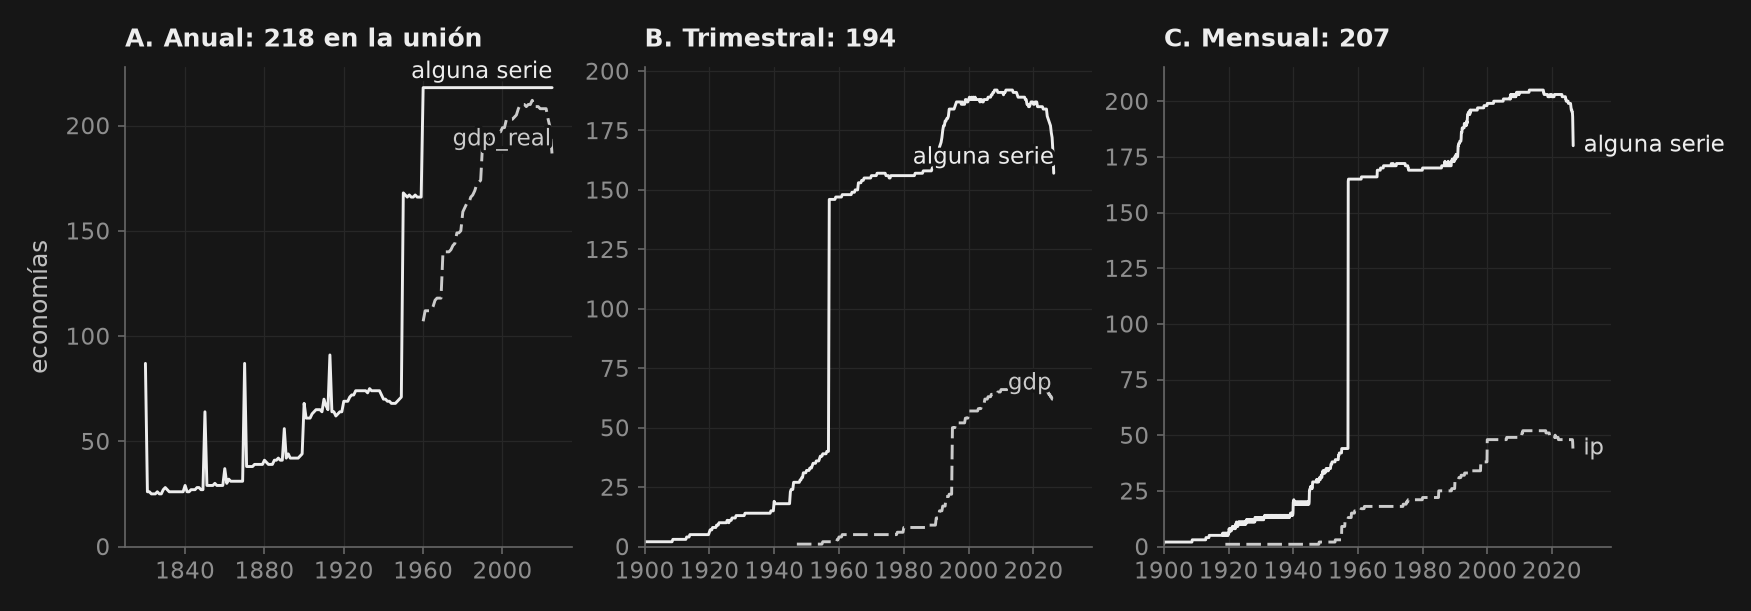

El trimestral y el mensual empiezan en 1791 con una sola serie, GBR fx_usd (q_bis): la figura empieza en 1900. Cada línea se detiene en el último período con el 80% de su máximo; después, lo que cae es el rezago de publicación, no la cobertura.


In [38]:
receipts = {"Y": coverage(annual, "Y"), "Q": cov_Q, "M": coverage(monthly, "M")}   # cov_Q: §3.5's, same panel
sets = {tr("annual real GDP", "PIB real anual"): set(annual.code[annual.variable == "gdp_real"]),
        tr("quarterly GDP", "PIB trimestral"): set(quarterly.code[quarterly.variable == "gdp"]),
        tr("monthly IP", "producción industrial mensual"): set(monthly.code[monthly.variable == "ip"]),
        tr("monthly unemployment", "paro mensual"): set(monthly.code[monthly.variable == "urate"])}
inter = set.intersection(*sets.values())
union = {f: p.code.nunique() for f, p in (("Y", annual), ("Q", quarterly), ("M", monthly))}

for label, s in sets.items():
    print(tr(f"{label}: {len(s)} economies", f"{label}: {len(s)} economías"))
print(tr(f"Annual union: {union['Y']}. Intersection of the four concepts: {len(inter)} — ",
         f"Unión anual: {union['Y']}. Intersección de los cuatro conceptos: {len(inter)} — ")
      + ", ".join(sorted(inter)[:10]) + "…")
word = {"Y": tr("annual", "anuales"), "Q": tr("quarterly", "trimestrales"), "M": tr("monthly", "mensuales")}
print(tr("Interior gaps (country-variables with a missing period between the first and the last): ",
         "Huecos interiores (país-variables con un período sin dato entre el primero y el último): ")
      + ", ".join(f"{int((r.internal_gaps > 0).sum()):,} {word[f]}" for f, r in receipts.items()) + ".")
for f, r in receipts.items():
    w = r.loc[r.internal_gaps.idxmax()]
    lo, hi = (x.replace("Q", tr("Q", "T")) for x in (w["first"], w["last"]))      # 1989T1 in Spanish
    print(tr(f"   the worst {word[f]}: {w.code} {w.variable}, {w.internal_gaps} periods without data between {lo} and {hi}.",
             f"   la peor de las {word[f]}: {w.code} {w.variable}, {w.internal_gaps} períodos sin dato entre {lo} y {hi}."))

# Figure C: economies per period with any series, and with the core concept of each frequency.
fig, axes = _nbstyle.figura(1, 3)
core = {"Y": ("gdp_real", annual), "Q": ("gdp", quarterly), "M": ("ip", monthly)}
titles = {"Y": tr(f"A. Annual: {union['Y']} in the union", f"A. Anual: {union['Y']} en la unión"),
          "Q": tr(f"B. Quarterly: {union['Q']}", f"B. Trimestral: {union['Q']}"),
          "M": tr(f"C. Monthly: {union['M']}", f"C. Mensual: {union['M']}")}


def upto(s):
    """A count per period, up to its last period at 80 % of its peak: after it, what falls is publication lag."""
    return s.loc[:s[s >= 0.8 * s.max()].index.max()]


for ax, (f, (v, p)) in zip(axes, core.items()):
    every = upto(p.groupby("date").code.nunique())
    one = upto(p.loc[p.variable == v].groupby("date").code.nunique())
    ax.plot(every.index, every, color=cols[0], lw=1.4, label=tr("any series", "alguna serie"))
    ax.plot(one.index, one, color=cols[1], ls=_nbstyle.styles(2)[1], lw=1.4, label=v)
    ax.set_ylim(bottom=0)
    if f != "Y":
        ax.set_xlim(left=pd.Timestamp("1900-01-01"))             # before 1900, a single series (receipt below)
    ax.set_title(titles[f])
    _nbstyle.etiquetar(ax, donde="fin")
axes[0].set_ylabel(tr("economies", "economías"))
plt.show()
r0 = quarterly.loc[quarterly.date.idxmin()]
print(tr(f"The quarterly and monthly panels begin in {r0.date:%Y} with a single series, {r0.code} {r0.variable} "
         f"({r0.source}): the figure starts in 1900. Each line stops at the last period with 80% of its peak; after "
         f"it, what falls is publication lag, not coverage.",
         f"El trimestral y el mensual empiezan en {r0.date:%Y} con una sola serie, {r0.code} {r0.variable} "
         f"({r0.source}): la figura empieza en 1900. Cada línea se detiene en el último período con el 80% de su "
         f"máximo; después, lo que cae es el rezago de publicación, no la cobertura."))

# The union is what the contract promised: every registered economy that publishes anything.
assert annual.code.nunique() >= 217
# An intersection is never larger than its smallest set.
assert len(inter) <= min(map(len, sets.values()))
# Receipts count exactly the rows of the panel.
assert all(r.n.sum() == len(p) for r, p in zip(receipts.values(), (annual, quarterly, monthly)))

## 7. Congelar: manifiesto, hashes, ida y vuelta

La lección termina donde empezó: con archivos. Pero aquí hay una decisión distinta de la del cuaderno de cuentas nacionales: **sólo se escribe cuando se refrescó algo**. La corrida por omisión no descarga, así que no tiene nada nuevo que escribir. Lo que hace es demostrar que los archivos entregados son exactamente lo que este cuaderno produce a partir de los bloques congelados, bit a bit. El hash del manifiesto deja de ser sólo una prueba de integridad y pasa a ser una prueba de reproducibilidad.

Tres decisiones, las tres de §1:
1. **Niveles y deflactores, sin volúmenes.** En los paneles, el volumen es $100\times$ nominal / deflactor, exacto hasta el último bit; guardarlo sería guardar la misma información dos veces y arriesgarse a que las copias dejen de cuadrar. Los bloques, en cambio, guardan lo que devolvió cada llamada, tal cual: son la materia prima, y los nombres del curso se aplican al leerlos.
2. **Una fuente por fila; lo demás, en las fichas.** Unidades, ajuste y regla de agregación viven en `t01_series.csv`; quién ganó y por qué, en `t01_provenance.csv`.
3. **Nombres de columna en inglés.** Los archivos los leen cuadernos en dos idiomas; su esquema no puede depender del idioma de quien los escribió. Por la misma razón, nada de lo que se escribe pasa por `tr`: las dos versiones del cuaderno escriben los mismos bytes.

Y una cuestión técnica que no es cosmética: los valores de los paneles se redondean a doce **cifras significativas** antes de escribir, y los gzip llevan la hora en cero. Sin eso el archivo cambia de hash según la máquina y la hora sin que haya cambiado ningún número. Cifras significativas y no decimales, porque un redondeo a nueve decimales borra lo pequeño: el índice de precios de Argentina en 1975 vale una milmillonésima del de hoy, y con nueve decimales quedaba plano —cinco meses de inflación cero en plena aceleración—. Congelar la mitad de los datos a mitad de camino es cómo se acaba con dos versiones del mismo panel; por eso hay un solo escritor, y está al final. Para ensayar un refresco sin tocar la entrega, `MAV_T01_DEST` manda lo que se escribe a otra carpeta.

In [39]:
from _t01 import frozen

# Where a refresh writes: data_curso/, or MAV_T01_DEST to rehearse one without touching the delivery.
OUT = Path(os.environ["MAV_T01_DEST"]) if VIVO and os.environ.get("MAV_T01_DEST") else DATA
NAME, PANELS = {"Y": "annual", "Q": "quarterly", "M": "monthly"}, {"Y": annual, "Q": quarterly, "M": monthly}


def where(file):
    """This run's copy if it wrote one; otherwise the delivery's (a partial refresh rewrites only part)."""
    return OUT / file if readable(OUT / file) else DATA / file


def significant(x, digits=12):
    """Round to significant digits, not decimals: a 1975 Argentine price index is a billionth of today's."""
    return np.fromiter((float(f"{v:.{digits}g}") for v in np.asarray(x, dtype=float).tolist()), float, len(x))


# The panels in memory become what the files hold: twelve significant digits, once.
for p in (annual, quarterly, monthly, commodities):
    p["value"] = significant(p.value)
# One table each for provenance and seams; the OECD's quarterly deflators get the reference year their metadata declares.
provenance = pd.concat([prov_Y, prov_Q, prov_M], ignore_index=True)
oecd_defl = (provenance.freq == "Q") & (provenance.source == "q_oecd_qna") & provenance.variable.str.endswith("_defl")
provenance.loc[oecd_defl, "ref_year"] = provenance.code[oecd_defl].map(qmeta.price_ref_year.dropna().astype(int).astype(str))
provenance["ref_year"] = provenance.ref_year.fillna("")
seams = pd.concat([seams_Y, seams_Q, seams_M], ignore_index=True)
countries_out = COUNTRIES.assign(**{f"in_{f}": COUNTRIES.code.isin(set(p.code.unique())) for f, p in PANELS.items()})
# Every file the panels make, built only when it is its turn: three sorted copies at once would not fit an iPad.
products = {**{f"t01_{NAME[f]}.csv.gz": (lambda p=p: frozen(p)) for f, p in PANELS.items()},
            "t01_commodities.csv.gz": lambda: frozen(commodities),
            "t01_provenance.csv": lambda: provenance, "t01_seams.csv": lambda: seams,
            **{f"t01_coverage_{NAME[f]}.csv": (lambda f=f: receipts[f]) for f in "YQM"},
            "t01_countries.csv": lambda: countries_out}

arg = monthly.loc[(monthly.code == "ARG") & (monthly.variable == "cpi") & (monthly.date.dt.year == 1975), "value"]
print(tr(f"Argentina's CPI in 1975, as it will be written: {arg.iloc[0]:.6g} in January, {arg.iloc[-1]:.6g} in "
         f"December (×{arg.iloc[-1] / arg.iloc[0]:.1f}); nine decimals would have kept {arg.round(9).nunique()} "
         f"distinct values of {len(arg)}.",
         f"El IPC de Argentina en 1975, tal como se escribirá: {arg.iloc[0]:.6g} en enero, {arg.iloc[-1]:.6g} en "
         f"diciembre (×{arg.iloc[-1] / arg.iloc[0]:.1f}); nueve decimales habrían dejado {arg.round(9).nunique()} "
         f"valores distintos de {len(arg)}."))

# Twelve significant digits keep the small: Argentina's 1975 index still rises every month.
assert len(arg) == 12 and (arg.diff().dropna() > 0).all()
# Every panel the manifest lists is a file this notebook makes.
assert {e["file"] for e in manifest["panels"].values()} <= set(products)

El IPC de Argentina en 1975, tal como se escribirá: 1.06904e-09 en enero, 4.51932e-09 en diciembre (×4.2); nueve decimales habrían dejado 5 valores distintos de 12.


In [40]:
import puremacro
from _t01 import csv_digest, content_digest, write_csv, write_block, new_manifest, release_memory

written = []
if VIVO:      # 1. every block refreshed in this run, as its call returned it, with its attrs beside it
    for block, e in ((b, e) for b, e in BLOCKS.items() if e["frame"] is not None):
        d = e["frame"]
        if block in ("t01_pwt110", "t01_pwt110_labor"):
            d = pwt if block == "t01_pwt110" else pwt_labor        # the wide code-year shape C reads
        elif block == "sahm" or ("date" not in d.index.names and "date" not in d.columns):
            d = d.reset_index()                                    # FRED's dated table; the country list
        else:
            d = as_long(d)[["code", "date", "variable", "value"]].sort_values(["code", "date", "variable"])
        write_block(OUT, e, d, e["frame"].attrs)
        written.append(e["file"])
    for sid in ("UNRATE", "SAHMCURRENT", "SAHMREALTIME") if BLOCKS["sahm"]["frame"] is not None else ():
        written.append(f"t01_{sid}.csv")      # B's three FRED files, in FRED's own layout
        write_csv(OUT / written[-1], fred_sahm[sid].dropna().rename_axis("observation_date").reset_index())
# 2. The panels and their receipts: written under VIVO; rebuilt and compared byte for byte always.
same = {}
for file, make in products.items():
    same[file] = (write_csv(OUT / file, make()) if VIVO else csv_digest(make())) == content_digest(where(file))
    written += [file] if VIVO else []
    release_memory()        # one sorted copy at a time
if VIVO:      # 3. the manifest: one entry per file, every hash, and who refreshed what
    new = new_manifest(manifest, where, BLOCKS, pwt={"t01_pwt110": pwt, "t01_pwt110_labor": pwt_labor},
                            panels={**{NAME[f]: (f"t01_{NAME[f]}.csv.gz", f, p) for f, p in PANELS.items()},
                                    "commodities": ("t01_commodities.csv.gz", "M", commodities)},
                            extra={"ranks": {"Y": RANK_Y, "Q": RANK_Q, "M": RANK_M}, "prefer": {"Y": PREFER_Y, "M": PREFER_M},
                                   "thresholds": {f: {"min_obs": o, "min_overlap": v} for f, o, v in
                                                  (("Y", MIN_OBS, MIN_OVERLAP), ("Q", MIN_OBS_Q, MIN_OVERLAP_Q),
                                                   ("M", MIN_OBS_M, MIN_OVERLAP_M))}},
                            version=puremacro.__version__)
    (OUT / "t01_manifest.json").write_text(json.dumps(new, indent=2, ensure_ascii=False, default=str) + "\n")
    manifest = json.loads((OUT / "t01_manifest.json").read_text())
    tables = [f for f in written if not f.startswith("t01_blocks/")]
    print(tr(f"Written to {OUT.name}/: {len(written) - len(tables)} block files with their attrs, ",
             f"Escritos en {OUT.name}/: {len(written) - len(tables)} archivos de bloque con sus atributos, ")
          + ", ".join(tables) + tr(" and t01_manifest.json.", " y t01_manifest.json."))
else:
    mb = sum(where(f).stat().st_size for f in same) / 1e6
    print(tr(f"Reproduced bit for bit from the frozen blocks: {len(same)} files, {mb:.1f} MB; nothing was written.",
             f"Reproducido bit a bit desde los bloques congelados: {len(same)} archivos, {mb:.1f} MB; nada se escribió."))

# Every product was rebuilt and compared; a refresh wrote every one.
assert set(same) == set(products) and (not VIVO or set(products) <= set(written))
# The delivery is what this notebook makes from the blocks: same content, bit for bit.
assert all(same.values()), [f for f, ok in same.items() if not ok]

Reproducido bit a bit desde los bloques congelados: 10 archivos, 29.4 MB; nada se escribió.


In [41]:
from _t01 import listed, assert_same_rows, peak_rss_mb


def reread(freq, variables=None, codes=None):
    """What B and C get from load_panel; a rehearsal reads its own folder the same way."""
    return load_panel(freq, variables=variables, codes=codes, folder=None if OUT == DATA else OUT)


# Receipts: what was delivered, from which blocks, and what it cost.
table = pd.DataFrame([{tr("file", "archivo"): e["file"], "series": e["variables"], tr("economies", "economías"): e["countries"],
                       tr("periods", "períodos"): f"{e['first'][:7]}–{e['last'][:7]}",
                       tr("observations", "observaciones"): f"{e['observations']:,}", "sha256": e["sha256"][:12]}
                      for e in manifest["panels"].values()])
print(table.to_string(index=False))
stamps = sorted(str(e["fetched_utc"])[:16].replace("T", " ") for e in BLOCKS.values() if e["fetched_utc"])
fresh_list = sorted(b for b, e in BLOCKS.items() if e["frame"] is not None)
print(tr(f"Blocks: {len(BLOCKS)}, {len(fresh_list)} refreshed in this run ({', '.join(fresh_list) or 'none'}); "
         f"the oldest downloaded on {stamps[0]}, the newest on {stamps[-1]} (UTC).",
         f"Bloques: {len(BLOCKS)}, {len(fresh_list)} refrescados en esta corrida ({', '.join(fresh_list) or 'ninguno'}); "
         f"el más viejo descargado el {stamps[0]}, el más reciente el {stamps[-1]} (UTC)."))

# Every file the manifest lists is, byte for byte, the file on disk.
for e in listed(manifest):
    assert sha256(where(e["file"])) == e["sha256"], e["file"]
# B and C read back exactly the panels in memory (one frequency at a time: memory).
for f, p in PANELS.items():
    assert_same_rows(frozen(reread(f)), frozen(p))
    release_memory()
# The volume we do not store is rebuilt from the two series we do.
q = wide_panel(reread("Q", variables=["gdp", "gdp_defl"], codes=["USA"]))
mem = wide_panel(quarterly.loc[(quarterly.code == "USA") & quarterly.variable.isin(["gdp", "gdp_defl"])])
assert np.allclose(100 * q.gdp / q.gdp_defl, 100 * mem.gdp / mem.gdp_defl, rtol=1e-9)

t = time.perf_counter()
reread("Q", variables=CONTRACT["Q"])
t_read = time.perf_counter() - t
print(tr(f"Filtered read of the {len(CONTRACT['Q'])} quarterly series B and C use: {t_read:.2f} s. Whole notebook: "
         f"{time.perf_counter() - T0:.0f} s; peak resident memory (ru_maxrss, which on a Mac also counts freed pages "
         f"the system has not reclaimed yet) {peak_rss_mb():.0f} MB.",
         f"Lectura filtrada de las {len(CONTRACT['Q'])} series trimestrales de B y C: {t_read:.2f} s. Cuaderno completo: "
         f"{time.perf_counter() - T0:.0f} s; memoria residente máxima (ru_maxrss, que en una Mac cuenta también páginas "
         f"liberadas que el sistema aún no reclama) {peak_rss_mb():.0f} MB."))

               archivo  series  economías        períodos observaciones       sha256
     t01_annual.csv.gz     190        218 1820-01–2026-01       911,066 f5a701d31766
  t01_quarterly.csv.gz     203        194 1791-01–2026-07       964,497 4562af81c399
    t01_monthly.csv.gz      65        207 1791-01–2026-09     1,485,477 fcc39868b80b
t01_commodities.csv.gz      48          1 1960-01–2026-09        37,187 d2dbe738001b
Bloques: 30, 0 refrescados en esta corrida (ninguno); el más viejo descargado el 2026-10-07 23:47, el más reciente el 2026-10-07 23:48 (UTC).


Lectura filtrada de las 23 series trimestrales de B y C: 0.34 s. Cuaderno completo: 28 s; memoria residente máxima (ru_maxrss, que en una Mac cuenta también páginas liberadas que el sistema aún no reclama) 1505 MB.


## 8. Tu turno

1. **Cobertura de la participación del trabajo.** En 1970–2019, ¿cuántas economías tienen remuneración de asalariados, valor añadido y renta mixta o empleo por cuenta propia en un bloque contiguo de al menos 30 años? Repórtalas, con la fuente primaria de cada ingrediente.
2. **Precedencia.** Pon el WDI primero para `gdp` —en `PREFER_Y`, que ordena por variable; `RANK_Y` ordena bloques— y vuelve a apilar. Compara el número de costuras, su deriva y el crecimiento medio 1970–2019 de cinco economías con el de la precedencia original.
3. **Una costura.** Elige en `t01_seams.csv` una costura inestable. Explica qué difiere entre las dos fuentes antes y después de la fecha, y si la usarías para un promedio de largo plazo.
4. **Capital público.** Para una economía con `k_gov_net` y `k_gov_pim`, compara niveles y crecimientos. ¿Qué parte de la diferencia es de método?
5. **Calendario.** Construye la producción industrial trimestral con la regla de la ficha y compárala, en crecimiento, con el valor añadido industrial trimestral de las cuentas.
6. **Extensión.** Añade el índice de precios de los alquileres como serie mensual: su ficha en el diccionario, su llamada y su recibo. No toques ninguna otra celda.

### Soluciones (esquema)
1. `regular_block(..., freq="Y", start="1970", end="2019", min_obs=30)` sobre las columnas necesarias; la fuente sale de `t01_provenance.csv`.
2. Basta un `PREFER_Y` con el WDI primero para `gdp`; `splice_sources` devuelve las costuras nuevas.
3. Lee `ratio_drift`, `ratio_min` y `ratio_max`; una deriva grande indica crecimientos distintos, no un error de unidades.
4. El método del FMI fija depreciaciones y un acervo inicial; el balance nacional usa sus propias vidas útiles.
5. La ficha dice `mean` para un índice; la producción industrial excluye construcción y servicios.
6. Una fila en `t01_series.csv`, la llamada dentro de su propio `load_block` —si `stes_panel` no conoce el concepto, se añade en puremacro, no aquí— y `MAV_T01_VIVO` con el nombre del bloque.

### Explora con IA
- «Lee `t01_provenance.csv` para México: ¿qué fuente ganó en cada variable anual y qué alternativas se descartaron? Cita las filas.»
- «Con `t01_series.csv`, ¿qué variables trimestrales no están desestacionalizadas y por qué tienen ese nombre? Cita la ficha, no inventes cobertura.»

**Resumen.** Partimos de preguntar qué economías hay, no cuáles queremos: el registro del Banco Mundial, más Taiwán, separa 218 economías de 79 agregados por un metadato, no por la forma del código. Cada fuente entró por una sola puerta —una llamada de puremacro, un archivo congelado, una ficha por serie— y una variable sin ficha o un código fuera del registro detenían el cuaderno.

El panel anual apila el WDI, la OCDE, Eurostat, el FMI, la OIT y Maddison. La auditoría de §2.5 mostró que la trampa de unidades es real y está identificada —un factor de un millón entre pesos y millones de pesos— y que, corregida en la fuente, casi todas las comparaciones coinciden; lo que queda se separa en tablas mal declaradas, monedas o bases distintas y conceptos distintos. La precedencia de §2.6 puso las cuentas de cada país en la moneda del PIB que gana, eligió una fuente primaria por país y variable y extendió la historia con 1581 costuras, cada una con su cociente y su deriva; las que derivan y además mueven el nivel más del doble se rechazaron.

El trimestral pide todo desde 1947 y gana historia anterior a 1995 para 19 economías; la inversión pública trimestral llega por dos caminos que se unen país por país sin contar dos veces, el paro de Estados Unidos desde 1955, y la escalera de §3.5 muestra que Estados Unidos sale en el escalón del trabajo y Japón en el de la renta.

El mensual reúne actividad, empleo, precios por componente, tipos de cambio efectivos, tasas y rendimientos para 207 economías; lo que no existe gratis quedó escrito como ausencia, no como cero.

§5 mostró que cuatro trimestres de una misma oficina son su año —salvo donde el año es fiscal, o donde el trimestral y el anual son ediciones distintas— y que la diferencia entre oficinas es el precio de la precedencia. §6, que la unión y la intersección son objetos distintos.

Y §7 cerró con archivos: los tres paneles se reconstruyen bit a bit a partir de los bloques congelados, y B y C los leen con `load_panel(freq, variables=…)`.

**Sigue:** [B — medición, vintages y diagnóstico del ciclo](T01_B_measurement_and_cycles_es.ipynb). El [complemento de cuentas nacionales](T01_B_hechos_estilizados_internacionales_es.ipynb) conserva los detalles de construcción: es un laboratorio de profundización, no un prerrequisito colocado después de este cuaderno.